<a href="https://colab.research.google.com/github/oumodavid1625/Bioinformatics/blob/main/Cervical_MHCII_Manuscript_Master.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Cervical cancer MHC-II study: Analysis notebook**

This notebook contains analysis code for GSE44001 survival, TCGA-CESC survival, Ugandan HIV-associated expression, and the revised GSE208653 single-cell compartment audit. No previous notebook, private Google Drive mount, patient login, GPU, or manual upload of results is required.

Upload this `.ipynb` to Google Colab, select a standard CPU runtime and choose **Runtime → Run all**. First execution downloads several hundred MB of public data; allow approximately 15–45 minutes depending on network/CPU. Downloads are cached within the session. A session can expire: download the final ZIP and save the executed notebook. This notebook uses current installed libraries and records exact versions; numerical output can vary across library versions.

The final **M01–M03** cells create manuscript tables, figures, interpretation notes and one combined ZIP. Stable code-cell labels (**B**, **H**, **S**, **M**) identify the analysis generating each output. The cells display their outputs and keep all cohort-specific audits and sensitivity results.

### Scientific scope

The fixed panel is **CIITA, CD74, HLA-DRA, HLA-DRB1, HLA-DPA1, HLA-DPB1**. For bulk data, each gene is standardised within its cohort, the six z-scores are averaged, and that average is standardised to one SD. This does not create a calibrated clinical assay or make absolute scores comparable across platforms. TCGA processed expression is retained as supplied; Uganda TPM is transformed as log2(TPM+1). Single-cell pseudobulk uses log1p(CP10K) and specimen/compartment-relative scaling.

GSE44001 deposited DFS is the original primary survival question. TCGA PFI is an independent assessment with a different endpoint, not identical external DFS validation. Uganda examines a conditional HIV-positive versus HIV-negative expression difference. Single-cell summaries describe three specimens without verified HIV stratification. Do not pool these endpoints or treat captured cells as independent patients.

### Analysis history and interpretation

This consolidated notebook was assembled **after** all component results were examined. Historical internal plans are retained with their original dates; the single-cell amendment explicitly records its post-review changes. No genes, weights, primary endpoints or outcome-selected thresholds have been changed during consolidation.

Preserve all negative/uncertain estimates. PTPRC is an expression proxy, not a complete immune-cell fraction; composition adjustment does not establish mediation. Epithelial labels remain provisional and do not establish malignancy or antigen-presentation function. The low automatic doublet flag rate remains unresolved; rank-based exclusions and additional-marker checks are stress tests. No ambient-RNA correction, ethics approval/exemption, biomarker validation, clinical utility or novel mechanism is asserted.

### Notebook map

| Section | Purpose |
|---|---|
| C01 | Configuration, dependencies and reproducibility |
| B01–B12 | Original public data, GEO/TCGA survival models and diagnostics |
| H01–H09 | Ugandan expression cohort, HIV models and robustness |
| S01–S07 | Revised single-cell annotations and compartment summaries |
| M01–M03 | Manuscript tables, numbered figures, audit and unified export |


## C01 · Configuration and common dependencies

In [1]:
import sys,subprocess,importlib.util,json,hashlib,platform,os
from pathlib import Path
from datetime import datetime,timezone
required={'numpy':'numpy','pandas':'pandas','scipy':'scipy','matplotlib':'matplotlib','openpyxl':'openpyxl','lifelines':'lifelines==0.30.3','sklearn':'scikit-learn','skimage':'scikit-image','threadpoolctl':'threadpoolctl'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
if importlib.util.find_spec('scrublet') is None:subprocess.check_call([sys.executable,'-m','pip','install','-q','--no-deps','scrublet==0.2.3'])
import numpy as np,pandas as pd
from IPython.display import display,Image as DisplayImage
MROOT=(Path('/content') if Path('/content').exists() else Path.cwd())/'cervical_mhcii_manuscript'
MOUT=MROOT/'manuscript_outputs';MOUT.mkdir(parents=True,exist_ok=True)
MASTER_GENES=['CIITA','CD74','HLA-DRA','HLA-DRB1','HLA-DPA1','HLA-DPB1']
MASTER_RUN={'notebook_version':'1.0','started_utc':datetime.now(timezone.utc).isoformat(),'seed':20261110,'fixed_panel':MASTER_GENES,'consolidation_after_results_review':True}
(MOUT/'run_configuration.json').write_text(json.dumps(MASTER_RUN,indent=2))
print('Study root:',MROOT)
print('One complete public-data run; no automatic downloads until the final export.')


Study root: /content/cervical_mhcii_manuscript
One complete public-data run; no automatic downloads until the final export.


## B01 · Retrieve original bulk sources

In [2]:
BULK_EXPECTED_SHA256={'GSE44001_series_matrix.txt.gz': '73c48eb6a39f6584eabd762f1d011279a1ac3b0e76fd79c65de310b9adb0ac0c', 'GPL14951_platform.soft.gz': '29c1296d340976bbff43ca3d35149ae6ccf58c0e90b94791b8c084ae0c83f5d4', 'TCGA_CESC_HiSeqV2.gz': '3b312d9f7daf4bb5e12efe1920932f7869e995227d18f5c96149bfe752f708de', 'TCGA_CDR.xlsx': 'ea594c0fbb6731477c7ac511fab449ca9c38b0d42d269591ed9f5c4090e75a5a'}
import sys, subprocess, importlib.util
required = {'pandas':'pandas', 'numpy':'numpy', 'openpyxl':'openpyxl'}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import pandas as pd, numpy as np
from pathlib import Path
import urllib.request, gzip, csv, io, json, hashlib, platform, shutil, re
from datetime import datetime, timezone
from IPython.display import display
ROOT = MROOT/'bulk'
RAW, OUT = ROOT/'raw', ROOT/'outputs'
RAW.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
GENES = ['CIITA','CD74','HLA-DRA','HLA-DRB1','HLA-DPA1','HLA-DPB1']
SOURCES = {
 'GSE44001_series_matrix.txt.gz':'https://ftp.ncbi.nlm.nih.gov/geo/series/GSE44nnn/GSE44001/matrix/GSE44001_series_matrix.txt.gz',
 'GPL14951_platform.soft.gz':'https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL14nnn/GPL14951/soft/GPL14951_family.soft.gz',
 'TCGA_CESC_HiSeqV2.gz':'https://tcga.xenahubs.net/download/TCGA.CESC.sampleMap%2FHiSeqV2.gz',
 'TCGA_CDR.xlsx':'https://api.gdc.cancer.gov/data/1b5f413e-a8d1-4d10-92eb-7c4ae739ed81'
}
manifest=[]
for name,url in SOURCES.items():
    dest=RAW/name
    if not dest.exists():
        print('Downloading',name)
        tmp=dest.with_suffix(dest.suffix+'.part')
        try:
            with urllib.request.urlopen(url, timeout=180) as response, tmp.open('wb') as f:
                if name == 'GPL14951_platform.soft.gz':
                    # The GEO family file includes every sample and can exceed 2 GB.
                    # Stop the network stream after the platform table; retain only that section.
                    found_end=False
                    with gzip.GzipFile(fileobj=response, mode='rb') as source, gzip.GzipFile(fileobj=f,mode='wb',mtime=0) as target:
                        for line in source:
                            target.write(line)
                            if line.startswith(b'!platform_table_end'):
                                found_end=True
                                break
                    assert found_end, 'Incomplete platform table'
                else:
                    shutil.copyfileobj(response,f)
            tmp.replace(dest)
        except Exception:
            tmp.unlink(missing_ok=True)
            raise
    digest=hashlib.sha256(dest.read_bytes()).hexdigest()
    if name!='GPL14951_platform.soft.gz':assert digest==BULK_EXPECTED_SHA256[name],'Source changed: '+name
    manifest.append({'file':name,'url':url,'sha256':digest,'bytes':dest.stat().st_size,
                     'retrieval_note':'platform-section-only; not complete remote family file' if name == 'GPL14951_platform.soft.gz' else 'complete file',
                     'audit_utc':datetime.now(timezone.utc).isoformat()})
pd.DataFrame(manifest).to_csv(OUT/'source_manifest.csv',index=False)
print('Downloads ready. Output folder:', OUT)


Downloads ready. Output folder: /content/cervical_mhcii_manuscript/bulk/outputs


## B02 · Preserve GEO clinical annotations

In [3]:
metadata=[]; expression_lines=[]; in_table=False
with gzip.open(RAW/'GSE44001_series_matrix.txt.gz','rt') as f:
    for line in f:
        if line.startswith('!series_matrix_table_begin'):
            in_table=True; continue
        if line.startswith('!series_matrix_table_end'): break
        if in_table: expression_lines.append(line)
        elif line.startswith('!Sample_'):
            metadata.append(next(csv.reader([line],delimiter='\t')))
samples=next(row[1:] for row in metadata if row[0]=='!Sample_geo_accession')
assert len(samples)==len(set(samples)), 'Duplicate GEO sample identifiers'
geo=pd.DataFrame(index=pd.Index(samples,name='sample_id'))
raw_annotations=[]
for row in metadata:
    if row[0]=='!Sample_characteristics_ch1':
        for sample,value in zip(samples,row[1:]):
            key,sep,val=value.partition(':')
            raw_annotations.append({'sample_id':sample,'field':key.strip(),'value':val.strip() if sep else value})
annotations=pd.DataFrame(raw_annotations)
assert not annotations.duplicated(['sample_id','field']).any(), 'Repeated clinical fields require review'
geo=geo.join(annotations.pivot(index='sample_id',columns='field',values='value'))
geo.to_csv(OUT/'GSE44001_clinical_original.csv')
annotations.to_csv(OUT/'GSE44001_annotations_long.csv',index=False)
required_fields=['Stage','largest diameter','disease_free_survival_(dfs)_(months)','status_of_dfs']
assert set(required_fields)<=set(geo.columns), f'Unexpected fields: {geo.columns.tolist()}'
geo['dfs_months']=pd.to_numeric(geo['disease_free_survival_(dfs)_(months)'],errors='coerce')
geo['dfs_status_deposited']=pd.to_numeric(geo['status_of_dfs'],errors='coerce')
geo['tumour_diameter_deposited']=pd.to_numeric(geo['largest diameter'],errors='coerce')
geo['eligible_dfs']=geo.dfs_months.gt(0)&geo.dfs_status_deposited.isin([0,1])
print('GEO patients:',len(geo))
print('DFS status as deposited:',geo.dfs_status_deposited.value_counts(dropna=False).to_dict())
print('Stage counts:',geo.Stage.value_counts(dropna=False).to_dict())
print('Available original clinical fields:',required_fields)
print('Tumour diameter units and DFS event definition require source confirmation.')
display(geo.head())


GEO patients: 300
DFS status as deposited: {0: 262, 1: 38}
Stage counts: {'IB1': 217, 'IIA': 42, 'IB2': 28, 'IA2': 13}
Available original clinical fields: ['Stage', 'largest diameter', 'disease_free_survival_(dfs)_(months)', 'status_of_dfs']
Tumour diameter units and DFS event definition require source confirmation.


,Stage,disease_free_survival_(dfs)_(months),largest diameter,status_of_dfs,dfs_months,dfs_status_deposited,tumour_diameter_deposited,eligible_dfs
sample_id,,,,,,,,
GSM1076341,IB1,71.63,2.3,0,71.63,0,2.3,True
GSM1076342,IB1,103.73,2.4,0,103.73,0,2.4,True
GSM1076343,IB1,32.57,1.5,0,32.57,0,1.5,True
GSM1076344,IB1,94.47,2.2,0,94.47,0,2.2,True
GSM1076345,IB1,85.6,1.6,0,85.60,0,1.6,True


## B03 · Map probes and compute fixed GEO score

In [4]:
platform_lines=[]; in_table=False
with gzip.open(RAW/'GPL14951_platform.soft.gz','rt') as f:
    for line in f:
        if line.startswith('!platform_table_begin'): in_table=True; continue
        if line.startswith('!platform_table_end'): break
        if in_table: platform_lines.append(line)
gpl=pd.read_csv(io.StringIO(''.join(platform_lines)),sep='\t',dtype=str,low_memory=False)
print('Platform columns:',gpl.columns.tolist())
assert 'ID' in gpl and 'Symbol' in gpl, 'Review platform gene-symbol field before proceeding'
gpl['gene']=gpl.Symbol.fillna('').str.strip()
probe_map=gpl.loc[gpl.gene.isin(GENES),['ID','gene']].drop_duplicates()
assert not probe_map.ID.duplicated().any(), 'Ambiguous probe mapping'
probe_map.to_csv(OUT/'selected_probe_mapping.csv',index=False)
expr=pd.read_csv(io.StringIO(''.join(expression_lines)),sep='\t',index_col=0)
del expression_lines
expr.index=expr.index.astype(str)
assert not expr.index.duplicated().any(), 'Duplicate expression probes'
assert set(expr.columns)==set(samples), 'Expression / clinical mismatch'
selected=expr.loc[expr.index.intersection(probe_map.ID)].copy()
selected['gene']=probe_map.set_index('ID').loc[selected.index,'gene']
geo_genes=selected.groupby('gene').mean(numeric_only=True).T.reindex(index=samples,columns=GENES)
print('Expression quantiles:',np.nanquantile(expr.to_numpy(dtype=float),[0,.25,.5,.75,1]))
coverage=pd.DataFrame({'gene':GENES,'GEO_probes':[int((probe_map.gene==g).sum()) for g in GENES]})
def pathway_score(x):
    x=x.reindex(columns=GENES).apply(pd.to_numeric,errors='coerce')
    sd=x.std(ddof=1)
    if x.isna().any().any() or not sd.gt(0).all():
        print('Score withheld: missing values, missing gene, or invariant gene.')
        return pd.Series(np.nan,index=x.index)
    z=(x-x.mean())/sd
    score=z.mean(axis=1)
    if not score.std(ddof=1)>0: return pd.Series(np.nan,index=x.index)
    return (score-score.mean())/score.std(ddof=1)
geo['pathway_score_sd']=pathway_score(geo_genes)
geo_genes.to_csv(OUT/'GSE44001_pathway_expression.csv',index_label='sample_id')
geo.to_csv(OUT/'GSE44001_analysis_ready.csv')
display(coverage)


Platform columns: ['ID', 'Transcript', 'Species', 'Source', 'Search_Key', 'ILMN_Gene', 'Source_Reference_ID', 'RefSeq_ID', 'Entrez_Gene_ID', 'GI', 'Accession', 'Symbol', 'Protein_Product', 'Array_Address_Id', 'Probe_Type', 'Probe_Start', 'SEQUENCE', 'Chromosome', 'Probe_Chr_Orientation', 'Probe_Coordinates', 'Cytoband', 'Definition', 'Ontology_Component', 'Ontology_Process', 'Ontology_Function', 'Synonyms', 'Obsolete_Probe_Id', 'GB_ACC']
Expression quantiles: [ 6.28663099  6.72028205  7.29768364  9.3249474  14.6869953 ]


,gene,GEO_probes
0,CIITA,1
1,CD74,3
2,HLA-DRA,2
3,HLA-DRB1,1
4,HLA-DPA1,1
5,HLA-DPB1,1


## B04 · Match TCGA primary expression to curated outcomes

In [5]:
tcga_expr=pd.read_csv(RAW/'TCGA_CESC_HiSeqV2.gz',sep='\t',index_col=0)
tcga_expr.index=tcga_expr.index.astype(str)
assert not tcga_expr.index.duplicated().any(), 'Duplicate TCGA gene symbols require review'
primary=[c for c in tcga_expr.columns if re.match(r'^TCGA-[A-Z0-9]{2}-[A-Z0-9]{4}-01',c)]
assert primary, 'No primary tumour columns detected'
primary_map=pd.DataFrame({'sample_id':primary,'patient_id':[c[:12] for c in primary]})
primary_map.to_csv(OUT/'TCGA_sample_patient_map.csv',index=False)
primary_map.loc[primary_map.patient_id.duplicated(keep=False)].to_csv(OUT/'TCGA_duplicate_primary_samples.csv',index=False)
tcga_genes=tcga_expr.reindex(GENES)[primary].T
coverage['TCGA_present']=[g in tcga_expr.index for g in GENES]
tcga_genes.index=tcga_genes.index.str[:12]
tcga_genes=tcga_genes.groupby(level=0).mean()
tcga_genes.index.name='patient_id'
tcga_genes.to_csv(OUT/'TCGA_pathway_expression.csv')
cdr=pd.read_excel(RAW/'TCGA_CDR.xlsx',sheet_name='TCGA-CDR')
cdr=cdr.loc[cdr['type'].eq('CESC')].copy().set_index('bcr_patient_barcode')
assert not cdr.index.duplicated().any(), 'Duplicate CDR patients'
cdr.to_csv(OUT/'TCGA_CESC_CDR_original.csv')
tcga=cdr.join(tcga_genes,how='inner')
tcga['pathway_score_sd']=pathway_score(tcga[GENES])
endpoint_rows=[]
for endpoint in ['OS','DSS','DFI','PFI']:
    status=pd.to_numeric(tcga[endpoint],errors='coerce')
    duration=pd.to_numeric(tcga[endpoint+'.time'],errors='coerce')
    ok=status.isin([0,1])&duration.gt(0)
    tcga[endpoint+'_eligible']=ok
    endpoint_rows.append({'endpoint':endpoint,'unit':'days','patients':int(ok.sum()),
                          'events':int(status.loc[ok].eq(1).sum()),'excluded_or_missing':int((~ok).sum())})
endpoints=pd.DataFrame(endpoint_rows)
tcga.to_csv(OUT/'TCGA_CESC_analysis_ready.csv',index_label='patient_id')
coverage.to_csv(OUT/'gene_coverage.csv',index=False)
print('CDR cervical patients:',len(cdr),'matched primary-tumour expression:',len(tcga))
display(endpoints)


CDR cervical patients: 307 matched primary-tumour expression: 302


,endpoint,unit,patients,events,excluded_or_missing
0,OS,days,290,71,12
1,DSS,days,286,54,16
2,DFI,days,174,26,128
3,PFI,days,290,70,12


## B05 · Missingness audit

In [6]:
missingness=[]
for cohort,frame in [('GEO_original',geo[required_fields]),('TCGA_CDR',cdr)]:
    clean=frame.replace(r'^\s*(?:\[Not Available\]|\[Not Applicable\]|Unknown|NA)?\s*$',np.nan,regex=True)
    for col in clean:
        missingness.append({'cohort':cohort,'field':col,'n':len(clean),
                            'missing_n':int(clean[col].isna().sum()),
                            'missing_percent':float(clean[col].isna().mean()*100)})
pd.DataFrame(missingness).to_csv(OUT/'clinical_missingness.csv',index=False)


/tmp/ipykernel_548/2784999181.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clean=frame.replace(r'^\s*(?:\[Not Available\]|\[Not Applicable\]|Unknown|NA)?\s*$',np.nan,regex=True)


## B06 · Survival software and input checks

In [7]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('lifelines') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','lifelines==0.30.3'])
import lifelines, scipy
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test
from scipy.stats import spearmanr, chi2
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter
from lifelines.exceptions import ConvergenceWarning
from pathlib import Path
import pandas as pd, numpy as np, json, re, warnings, gzip, io
SURV=ROOT/'survival_outputs'; SURV.mkdir(exist_ok=True)
G=pd.read_csv(OUT/'GSE44001_analysis_ready.csv',index_col='sample_id')
T=pd.read_csv(OUT/'TCGA_CESC_analysis_ready.csv',index_col='patient_id')
GX=pd.read_csv(OUT/'GSE44001_pathway_expression.csv',index_col='sample_id')
TX=pd.read_csv(OUT/'TCGA_pathway_expression.csv',index_col='patient_id').reindex(T.index)
assert G.index.is_unique and T.index.is_unique
assert set(GENES)<=set(GX) and set(GENES)<=set(TX)
NUMBOOT=200
SEED=20261110
print('Loaded GEO:',len(G),'TCGA:',len(T),'Bootstrap replicates per primary model:',NUMBOOT)
print('Software:',{'lifelines':lifelines.__version__,'scipy':scipy.__version__,'pandas':pd.__version__})


assert GENES==MASTER_GENES


Loaded GEO: 300 TCGA: 302 Bootstrap replicates per primary model: 200
Software: {'lifelines': '0.30.3', 'scipy': '1.16.3', 'pandas': '2.2.3'}


## B07 · Clinical derivations and PTPRC proxy

In [8]:
G['time']=pd.to_numeric(G.dfs_months,errors='coerce')
G['event']=pd.to_numeric(G.dfs_status_deposited,errors='coerce')
assert G.Stage.isin(['IA2','IB1','IB2','IIA']).all()
G['stage_II']=G.Stage.eq('IIA').astype(int)
G['size_sd']=(pd.to_numeric(G.tumour_diameter_deposited,errors='coerce')-pd.to_numeric(G.tumour_diameter_deposited,errors='coerce').mean())/pd.to_numeric(G.tumour_diameter_deposited,errors='coerce').std(ddof=1)
G['score']=pd.to_numeric(G.pathway_score_sd,errors='coerce')
def major_stage(value):
    text=str(value).upper().replace('STAGE','').strip()
    match=re.match(r'^(IV|III|II|I)(?:[AB0-9]|$)',text)
    return match.group(1) if match else np.nan
T['major_stage']=T.clinical_stage.map(major_stage)
T['age10']=pd.to_numeric(T.age_at_initial_pathologic_diagnosis,errors='coerce')/10
T['score']=pd.to_numeric(T.pathway_score_sd,errors='coerce')
T['non_squamous']=np.where(T.histological_type.notna(),~T.histological_type.str.contains('Squamous Cell',case=False,na=False),np.nan).astype(float)
for stage in ['II','III','IV']:
    T['stage_'+stage]=np.where(T.major_stage.notna(),T.major_stage.eq(stage).astype(float),np.nan)
T['time']=pd.to_numeric(T['PFI.time'],errors='coerce')
T['event']=pd.to_numeric(T['PFI'],errors='coerce')
# Reuse the full normalised matrices loaded by the feasibility cells.
assert 'expr' in globals() and 'gpl' in globals() and 'tcga_expr' in globals(), 'Run preceding feasibility cells first'
ptp_map=gpl.loc[gpl['Symbol'].eq('PTPRC'),'ID'].astype(str).drop_duplicates()
assert len(ptp_map)>0 and 'PTPRC' in tcga_expr.index
geo_ptp=expr.loc[expr.index.intersection(ptp_map)].mean(axis=0).reindex(G.index)
tcga_ptp=tcga_expr.loc['PTPRC',primary].copy()
tcga_ptp.index=tcga_ptp.index.str[:12]
tcga_ptp=tcga_ptp.groupby(level=0).mean().reindex(T.index)
for d,v in [(G,geo_ptp),(T,tcga_ptp)]:
    d['PTPRC_sd']=(v-v.mean())/v.std(ddof=1)
G.to_csv(SURV/'GEO_derived_variables.csv');T.to_csv(SURV/'TCGA_derived_variables.csv')
correlations=[]
for cohort,d in [('GEO',G),('TCGA',T)]:
    keep=d[['score','PTPRC_sd']].dropna()
    rho,p=spearmanr(keep.score,keep.PTPRC_sd)
    correlations.append({'cohort':cohort,'n':len(keep),'spearman_rho':rho,'p':p})
pd.DataFrame(correlations).to_csv(SURV/'PTPRC_correlations.csv',index=False)
print('TCGA major stage:',T.major_stage.value_counts(dropna=False).to_dict())
print('PTPRC correlation:',correlations)



TCGA major stage: {'I': 162, 'II': 68, 'III': 45, 'IV': 20, nan: 7}
PTPRC correlation: [{'cohort': 'GEO', 'n': 300, 'spearman_rho': np.float64(0.6245127168079645), 'p': np.float64(7.570501903051844e-34)}, {'cohort': 'TCGA', 'n': 302, 'spearman_rho': np.float64(0.6511763676273723), 'p': np.float64(8.077770790755271e-38)}]


## B08 · Primary and independent Cox models

In [9]:
results=[];diagnostics=[];model_log=[];models={};model_data={}
def analysis_rows(d,cols):
    z=d[['time','event']+cols].apply(pd.to_numeric,errors='coerce')
    z=z.loc[z.time.gt(0)&z.event.isin([0,1])].dropna()
    assert np.isfinite(z.to_numpy()).all()
    return z
def fit_model(name,d,cols,role='exploratory',diagnose=False):
    z=analysis_rows(d,cols)
    if z.event.sum()<10 or z[cols].nunique().min()<2:
        model_log.append({'model':name,'status':'not fitted: too few events or invariant predictor','n':len(z),'events':int(z.event.sum())})
        return None
    try:
        with warnings.catch_warnings(record=True) as warns:
            warnings.simplefilter('always')
            cph=CoxPHFitter(penalizer=0).fit(z,duration_col='time',event_col='event')
        model_log.append({'model':name,'status':'fitted','role':role,'n':len(z),'events':int(z.event.sum()),'warnings':' | '.join(str(w.message) for w in warns)})
        for variable,row in cph.summary.iterrows():
            results.append({'model':name,'role':role,'variable':variable,'n':len(z),'events':int(z.event.sum()),'HR':row['exp(coef)'],'CI_low':row['exp(coef) lower 95%'],'CI_high':row['exp(coef) upper 95%'],'p':row['p'],'coef':row['coef'],'se':row['se(coef)']})
        models[name]=cph;model_data[name]=z
        if diagnose:
            ph=proportional_hazard_test(cph,z,time_transform='rank').summary
            for var,row in ph.iterrows():
                diagnostics.append({'model':name,'variable':var,'test':'scaled Schoenfeld / rank time','p':row['p'],'test_statistic':row['test_statistic']})
        return cph
    except Exception as e:
        model_log.append({'model':name,'status':'failed','error':repr(e),'n':len(z),'events':int(z.event.sum())})
        if role=='primary':raise
        return None
geo_cov=['stage_II','size_sd'];tcga_cov=['age10','stage_II','stage_III','stage_IV','non_squamous']
for cohort,d,cov in [('GEO',G,geo_cov),('TCGA_PFI',T,tcga_cov)]:
    fit_model(cohort+'_unadjusted',d,['score'],'supporting')
    fit_model(cohort+'_adjusted',d,['score']+cov,'primary' if cohort=='GEO' else 'independent_assessment',True)
    fit_model(cohort+'_PTPRC_sensitivity',d,['score']+cov+['PTPRC_sd'],'exploratory')
TO=T.copy();TO['time']=pd.to_numeric(TO['OS.time'],errors='coerce');TO['event']=pd.to_numeric(TO.OS,errors='coerce')
fit_model('TCGA_OS_adjusted',TO,['score']+tcga_cov,'secondary',True)
# Compare score-containing and clinical-only models on identical rows.
incremental=[]
for name,cov in [('GEO_adjusted',geo_cov),('TCGA_PFI_adjusted',tcga_cov)]:
    z=model_data[name]
    base=CoxPHFitter().fit(z.drop(columns='score'),duration_col='time',event_col='event')
    lr=2*(models[name].log_likelihood_-base.log_likelihood_)
    incremental.append({'model':name,'n':len(z),'events':int(z.event.sum()),'LR_1df':lr,'p':chi2.sf(max(0,lr),1)})
pd.DataFrame(incremental).to_csv(SURV/'incremental_likelihood_ratio.csv',index=False)
print(pd.DataFrame(results).query("variable == 'score'")[['model','n','events','HR','CI_low','CI_high','p']].to_string(index=False))



                     model   n  events       HR   CI_low  CI_high        p
            GEO_unadjusted 300      38 1.018497 0.737354 1.406837 0.911451
              GEO_adjusted 300      38 1.004534 0.723475 1.394780 0.978447
     GEO_PTPRC_sensitivity 300      38 0.973562 0.646089 1.467017 0.898088
       TCGA_PFI_unadjusted 290      70 0.812182 0.647807 1.018265 0.071375
         TCGA_PFI_adjusted 284      70 0.837886 0.666027 1.054091 0.130997
TCGA_PFI_PTPRC_sensitivity 284      70 0.937295 0.713495 1.231293 0.641773
          TCGA_OS_adjusted 284      71 0.807842 0.649409 1.004928 0.055387


## B09 · Prespecified sensitivity analyses and PH checks

In [10]:
# Finer GEO stage adjustment is exploratory given only 38 events.
Gfull=G.copy()
for stage in ['IB1','IB2','IIA']:Gfull['substage_'+stage]=G.Stage.eq(stage).astype(int)
fit_model('GEO_full_substage',Gfull,['score','size_sd','substage_IB1','substage_IB2','substage_IIA'])
fit_model('TCGA_PFI_stage_I_II',T.loc[T.major_stage.isin(['I','II'])],['score','age10','stage_II','non_squamous'])
fit_model('TCGA_PFI_squamous',T.loc[T.non_squamous.eq(0)],['score','age10','stage_II','stage_III','stage_IV'])
for cohort,d,x,cov in [('GEO',G,GX,geo_cov),('TCGA_PFI',T,TX,tcga_cov)]:
    for gene in GENES:
        remaining=[g for g in GENES if g!=gene]
        z=x[remaining].apply(pd.to_numeric,errors='coerce')
        s=((z-z.mean())/z.std(ddof=1)).mean(axis=1)
        dd=d.copy();dd['score']=(s-s.mean())/s.std(ddof=1)
        fit_model(cohort+'_omit_'+gene,dd,['score']+cov)
        dd=d.copy();v=pd.to_numeric(x[gene],errors='coerce');dd['gene_sd']=(v-v.mean())/v.std(ddof=1)
        fit_model(cohort+'_gene_'+gene,dd,['gene_sd']+cov)
res=pd.DataFrame(results)
gene_tests=res.loc[res.variable.eq('gene_sd')].copy()
def bh(p):
    p=np.array(p,dtype=float);order=np.argsort(p);ranked=p[order]*len(p)/np.arange(1,len(p)+1)
    adj=np.minimum.accumulate(ranked[::-1])[::-1].clip(0,1);out=np.empty(len(p));out[order]=adj;return out
gene_tests['BH_q_across_12_tests']=bh(gene_tests.p.to_numpy())
gene_tests.to_csv(SURV/'individual_genes_exploratory_BH.csv',index=False)
res.to_csv(SURV/'cox_models_all_coefficients.csv',index=False)
pd.DataFrame(model_log).to_csv(SURV/'model_fit_log.csv',index=False)
pd.DataFrame(diagnostics).to_csv(SURV/'proportional_hazards_tests.csv',index=False)
# If the exposure PH test fails, fit a prespecified score x log(time) sensitivity.
# A Cox time-varying model uses each risk interval's event time, not each subject's final follow-up.
ph_score=[r for r in diagnostics if r['variable']=='score' and r['model'] in ['GEO_adjusted','TCGA_PFI_adjusted'] and r['p']<.05]
if ph_score:
    from lifelines import CoxTimeVaryingFitter
    tvrows=[]
    for issue in ph_score:
        name=issue['model'];z=model_data[name]
        event_times=np.sort(z.loc[z.event.eq(1),'time'].unique())
        # Split at every observed event time: piecewise-constant representation exact at failures.
        intervals=[]
        for pid,(_,row) in enumerate(z.iterrows()):
            cuts=np.r_[0,event_times[event_times<row.time],row.time]
            for start,stop in zip(cuts[:-1],cuts[1:]):
                item=row.drop(['time','event']).to_dict()
                item.update({'id':pid,'start':start,'stop':stop,'event':int(row.event==1 and stop==row.time),'score_log_time':row.score*np.log(max(stop,1e-8))})
                intervals.append(item)
        tv=CoxTimeVaryingFitter().fit(pd.DataFrame(intervals),id_col='id',start_col='start',stop_col='stop',event_col='event')
        s=tv.summary.reset_index();s.insert(0,'model',name);s.to_csv(SURV/(name+'_time_varying_sensitivity.csv'),index=False)
        print('PH sensitivity generated:',name)
else:
    print('No primary score PH test below 0.05; time-varying sensitivity not triggered.')
print('Fitted models:',len(models),'Individual-gene tests:',len(gene_tests))



No primary score PH test below 0.05; time-varying sensitivity not triggered.
Fitted models: 34 Individual-gene tests: 12


## B10 · Bootstrap uncertainty and cohort descriptions

In [11]:
rng=np.random.default_rng(SEED);boot_results=[]
for name in ['GEO_adjusted','TCGA_PFI_adjusted']:
    z=model_data[name]
    for b in range(NUMBOOT):
        zz=z.iloc[rng.integers(0,len(z),len(z))].reset_index(drop=True)
        try:
            with warnings.catch_warnings(record=True) as ww:
                warnings.simplefilter('always')
                m=CoxPHFitter().fit(zz,duration_col='time',event_col='event')
            if any(isinstance(w.message,ConvergenceWarning) for w in ww):
                raise RuntimeError('Convergence warning: bootstrap estimate excluded')
            coef=float(m.params_['score'])
            boot_results.append({'model':name,'replicate':b+1,'coef':coef,'status':'ok','warnings':' | '.join(str(w.message) for w in ww)})
        except Exception as e:
            boot_results.append({'model':name,'replicate':b+1,'coef':np.nan,'status':'failed','warnings':str(e)})
    print('Bootstrap finished:',name,flush=True)
boot=pd.DataFrame(boot_results);boot.to_csv(SURV/'bootstrap_replicates.csv',index=False)
bs=[]
for name,b in boot.groupby('model'):
    valid=b.coef.dropna()
    bs.append({'model':name,'successful':len(valid),'requested':NUMBOOT,'HR_percentile_low':float(np.exp(valid.quantile(.025))),'HR_percentile_high':float(np.exp(valid.quantile(.975)))})
pd.DataFrame(bs).to_csv(SURV/'bootstrap_coefficient_intervals.csv',index=False)
descriptions=[]
for name,d in [('GEO_DFS',G),('TCGA_PFI',T)]:
    z=analysis_rows(d,['score'])
    reverse=KaplanMeierFitter().fit(z.time,event_observed=1-z.event)
    descriptions.append({'cohort':name,'n':len(z),'events':int(z.event.sum()),'reverse_KM_median_followup':float(reverse.median_survival_time_),'time_unit':'months' if name=='GEO_DFS' else 'days','score_median':d.score.median(),'score_min':d.score.min(),'score_max':d.score.max()})
pd.DataFrame(descriptions).to_csv(SURV/'cohort_description.csv',index=False)
print(pd.DataFrame(bs).to_string(index=False))



Bootstrap finished: GEO_adjusted
Bootstrap finished: TCGA_PFI_adjusted
            model  successful  requested  HR_percentile_low  HR_percentile_high
     GEO_adjusted         200        200           0.682602            1.488191
TCGA_PFI_adjusted         195        200           0.621257            1.075263


## B11 · Bulk cohort figures

In [12]:
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120})
fig,axes=plt.subplots(1,2,figsize=(11,4.7))
for ax,(cohort,d,unit) in zip(axes,[('GEO: deposited DFS',G,'Months'),('TCGA: progression-free interval',T,'Days')]):
    z=analysis_rows(d,['score']);cut=z.score.median()
    for high,color,label in [(False,'#276b8c','Below median'),(True,'#b9653f','At/above median')]:
        sub=z.loc[z.score.ge(cut) if high else z.score.lt(cut)]
        km=KaplanMeierFitter().fit(sub.time,sub.event,label=f'{label} (n={len(sub)})')
        km.plot_survival_function(ax=ax,ci_show=True,color=color,show_censors=True)
    ax.set(title=cohort,xlabel=unit,ylabel='Event-free probability',ylim=(0,1.02))
    ax.legend(fontsize=8,frameon=False)
fig.suptitle('Descriptive median-score groups; continuous Cox models are primary',fontsize=11)
fig.tight_layout();fig.savefig(SURV/'Figure_1_descriptive_KM.png',dpi=300,bbox_inches='tight');fig.savefig(SURV/'Figure_1_descriptive_KM.pdf');plt.close(fig)
show_models=['GEO_unadjusted','GEO_adjusted','GEO_PTPRC_sensitivity','TCGA_PFI_unadjusted','TCGA_PFI_adjusted','TCGA_PFI_PTPRC_sensitivity','TCGA_OS_adjusted']
f=res.loc[res.variable.eq('score')].set_index('model').loc[show_models]
labels=['GEO DFS: unadjusted','GEO DFS: stage + diameter','GEO DFS: + PTPRC','TCGA PFI: unadjusted','TCGA PFI: clinical adjustment','TCGA PFI: + PTPRC','TCGA OS: clinical adjustment']
fig,ax=plt.subplots(figsize=(9,4.7))
y=np.arange(len(f))[::-1]
ax.errorbar(f.HR,y,xerr=[f.HR-f.CI_low,f.CI_high-f.HR],fmt='o',color='#246b87',capsize=3)
ax.axvline(1,color='gray',ls='--',lw=1);ax.set_xscale('log');ax.set_yticks(y,labels)
ax.set_xlabel('Hazard ratio per 1 SD increase in fixed pathway score (95% CI)')
ax.set_title('Primary, independent and sensitivity estimates')
ax.xaxis.set_major_locator(FixedLocator([0.6,0.8,1.0,1.2,1.4]))
ax.xaxis.set_minor_locator(FixedLocator([]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x:.1f}'))
fig.tight_layout();fig.savefig(SURV/'Figure_2_forest.png',dpi=300,bbox_inches='tight');fig.savefig(SURV/'Figure_2_forest.pdf');plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(9,3.8))
for ax,(cohort,d) in zip(axes,[('GEO',G),('TCGA',T)]):
    z=d[['score','PTPRC_sd']].dropna();rho=spearmanr(z.score,z.PTPRC_sd).statistic
    ax.scatter(z.PTPRC_sd,z.score,s=13,alpha=.55,color='#246b87')
    ax.set(title=f'{cohort}: Spearman rho = {rho:.2f}',xlabel='PTPRC expression (SD)',ylabel='Pathway score (SD)')
fig.tight_layout();fig.savefig(SURV/'Figure_3_PTPRC_correlation.png',dpi=300,bbox_inches='tight');fig.savefig(SURV/'Figure_3_PTPRC_correlation.pdf');plt.close(fig)
print('Saved three figures as PNG (300 dpi) and PDF.')



Saved three figures as PNG (300 dpi) and PDF.


## B12 · Bulk analysis plan, interpretation and audit

In [13]:
(SURV/'Analysis_Plan.md').write_text('# Analysis plan locked before examining survival associations\n\nCreated 10 November 2026. This is an internally recorded analysis plan, not an externally preregistered protocol. Feasibility counts and missingness were already examined. No survival association estimates had been examined when this version was written.\n\n## Primary question and exposure\nAssess the association between a fixed six-gene MHC class II pathway expression score and deposited DFS in GSE44001. Genes: CIITA, CD74, HLA-DRA, HLA-DRB1, HLA-DPA1, HLA-DPB1. Retain equal gene weights, unambiguous probe mappings and within-cohort standardisation from the feasibility notebook. Report HR per one SD increase. Do not select genes or score cut-offs based on outcomes.\n\n## Primary GEO analysis\nUse positive DFS time in months, status 1 as the deposited event category and status 0 as censored. This coding is consistent with the 38 recurrences reported by subsequent analyses, but the accessible original abstract and GEO series do not fully document the event composite, censoring rules, or time origin. Report this limitation; do not claim a verified cause-specific recurrence endpoint. Model: continuous pathway score + stage IIA versus stage I (IA2/IB1/IB2) + tumour diameter per cohort SD. Diameter is expressed per SD because original units have not been independently verified. Stage grouping is prespecified for parsimony with 38 events, not chosen from model estimates. Exclude missing fields from each relevant model and report counts.\n\n## Independent assessment\nUse TCGA-CDR PFI as the prespecified independent endpoint because it is a broadly available progression-related endpoint in this resource; do not treat PFI as postoperative DFS. Model: pathway score + age per 10 years + major stage indicators II/III/IV versus I + non-squamous histology indicator (adenocarcinoma/adenosquamous versus SCC). Complete cases; no imputation in the initial analysis. TCGA stage-I/II subset is a sensitivity analysis, not a verified surgical cohort. OS is a secondary endpoint. DFI and DSS remain descriptive in this analysis to avoid expanding the endpoint search. No cross-cohort pooling because outcomes/populations differ.\n\n## Secondary and sensitivity analyses\nUnadjusted models; adding PTPRC expression (per SD) as an exploratory leukocyte-marker sensitivity analysis in each cohort; GEO full substage adjustment; TCGA stage-I/II restriction; TCGA squamous-only restriction; six leave-one-gene-out score analyses per cohort; individual genes analysed per SD with Benjamini-Hochberg adjustment across the 12 gene/cohort tests. PTPRC is a crude marker, not a validated immune-cell fraction and not evidence of tumour-cell-specific expression or causal mediation.\n\n## Diagnostics and uncertainty\nReport Wald HRs and 95% CIs, proportional-hazards diagnostics using scaled Schoenfeld residuals with rank time transformation (tests are exploratory), and reverse Kaplan-Meier median follow-up. A prespecified score x log(time) interaction will be fitted as a time-varying sensitivity if the primary score violates PH at p<0.05; report alongside the original, rather than replacing it. No outcome-selected cut-off. Median-score Kaplan-Meier curves are descriptive only. Use 200 patient-bootstrap replicates for the pathway coefficient in each primary adjusted model (conditional on fixed cohort score scaling), recording failures. Incremental likelihood-ratio tests use identical complete-case rows. No claim of predictive accuracy or clinical utility from an apparent C-index. No treatment-effect, mechanism, or immunotherapy-response claim.\n\n## Interpretation and publication\nGEO is the primary hypothesis test at two-sided alpha 0.05. TCGA PFI is an independent assessment, explicitly with a different endpoint; its nominal p-value does not rescue a negative primary result. Sensitivity findings are exploratory and must not replace the primary model. This is a focused replication/extension: cervical HLA-DRA prognosis has already been investigated (PMID 27654088); CD74/HLA-DRA carcinogenesis (PMID 35208514), TCGA MHC expression by HPV status (doi:10.3390/cells11233911), and an HLA-DMA-containing model using TCGA/GSE44001 (doi:10.1186/s40001-025-02515-5) limit novelty. An exact duplicate was not identified in the targeted search; absence of a result is not proof of originality. Confirm institutional ethics determination before submission; no ethics approval or exemption is invented here.\n')
from datetime import datetime,timezone
for audit_file in ['source_manifest.csv','selected_probe_mapping.csv','gene_coverage.csv','clinical_missingness.csv']:
    shutil.copy2(OUT/audit_file,SURV/audit_file)
rows=res.loc[res.variable.eq('score')].set_index('model')
def markdown_table(frame):
    headers=list(frame.columns)
    lines=['| '+' | '.join(headers)+' |','| '+' | '.join(['---']*len(headers))+' |']
    for values in frame.itertuples(index=False,name=None):
        lines.append('| '+' | '.join(f'{v:.4g}' if isinstance(v,(float,np.floating)) else str(v) for v in values)+' |')
    return '\n'.join(lines)
def result_line(name):
    r=rows.loc[name]
    return f"HR {r.HR:.2f} (95% CI {r.CI_low:.2f}–{r.CI_high:.2f}), p={r.p:.4g}; n={int(r.n)}, events={int(r.events)}"
primary=rows.loc['GEO_adjusted'];independent=rows.loc['TCGA_PFI_adjusted']
conclusion=('The primary GEO analysis supports an association under the specified model.' if primary.p<.05 else 'The primary GEO analysis does not provide clear evidence of an association; this is not proof of no effect.')
conclusion+=' '+('TCGA PFI shows a nominally significant association, using a different endpoint and population.' if independent.p<.05 else 'TCGA PFI also does not provide clear evidence of an association under its specified model.')
report=['# Cervical cancer pathway study: initial survival results',
'Executed '+datetime.now(timezone.utc).isoformat(),
'## Interpretation',conclusion,
'## Main estimates',
'- GEO DFS, unadjusted: '+result_line('GEO_unadjusted'),
'- GEO DFS, adjusted for stage IIA versus I and tumour diameter per SD: '+result_line('GEO_adjusted'),
'- TCGA PFI, unadjusted: '+result_line('TCGA_PFI_unadjusted'),
'- TCGA PFI, adjusted for age, major stage and non-squamous histology: '+result_line('TCGA_PFI_adjusted'),
'- TCGA OS, secondary: '+result_line('TCGA_OS_adjusted'),
'## Leukocyte-marker sensitivity',
'- GEO DFS with PTPRC added: '+result_line('GEO_PTPRC_sensitivity'),
'- TCGA PFI with PTPRC added: '+result_line('TCGA_PFI_PTPRC_sensitivity'),
'PTPRC is a crude leukocyte-expression marker. Adjustment cannot establish tumour-cell-specific expression, causal mediation, or independence from all immune infiltration.',
'## Diagnostics and bootstrap',
markdown_table(pd.DataFrame(diagnostics).query("variable == 'score'") [['model','p']]),
markdown_table(pd.DataFrame(bs)),
'Bootstrap intervals use 200 patient resamples with fixed original cohort score scaling. These are supplemental, not an independent validation or a full predictive-performance assessment. Check model_fit_log.csv for warnings. PH tests are exploratory; inspect any triggered time-varying sensitivity files.',
'The secondary TCGA OS score PH test is below 0.05 (see table), so its constant-HR estimate requires caution and must not be used to promote an overall-survival claim. The GEO full-substage sensitivity model emitted a convergence warning and is not reliable for interpretation. Bootstrap estimates with convergence warnings or errors were excluded from percentile intervals; failure counts are retained.',
'## Publication assessment',
'Given the negative primary and independent analyses plus existing literature overlap, this initial result is not a strong standalone biomarker-discovery submission. A transparent replication report could be considered after endpoint-source clarification and a specific contribution are established. This is a replication/extension, not a discovery of an HLA–prognosis relationship. A positive secondary result or individual gene must not replace a negative primary endpoint. No gene weights or cut-offs were selected for significance. TCGA PFI and GEO DFS are different outcomes and were not pooled. The score is cohort-standardised, so the same numerical threshold is not a transferable clinical test.',
'## Important unresolved source and design limitations',
'- GEO deposited DFS status 1 is treated as an event, consistent with published reanalyses reporting 38 recurrences. The accessible original abstract/series do not completely verify the event composite, censoring rules or exact time origin; source documentation is still required before submission.',
'- Tumour diameter units are not independently verified; the analysis uses a per-SD term.',
'- The GEO public fields do not provide age, nodes, margins, LVSI, adjuvant therapy, HPV or histology. These cannot be claimed as adjusted covariates.',
'- TCGA histological subtype and HPV biology may affect the expression signal. Non-squamous adjustment and squamous-only sensitivity do not replace explicit HPV-status analysis.',
'- A limited event count, heterogeneous treatment, historical cohorts, bulk-tissue composition, and unverified probe specificity limit clinical interpretation.',
'- The model assumes log-linear continuous covariate effects; this initial analysis does not fully establish functional form. No clinical prediction or treatment-selection claim is justified.',
'- Missing outcomes and covariates are excluded; see the cohort flow and complete-case counts. No ethics approval, exemption or waiver is asserted.',
'## Literature and data sources',
'1. Lee et al. Genetic profiling to predict recurrence of early cervical cancer. Gynecol Oncol (2013). https://pubmed.ncbi.nlm.nih.gov/24145113/',
'2. GEO GSE44001 and GPL14951. https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE44001',
'3. Liu et al. TCGA Clinical Data Resource. Cell (2018). https://gdc.cancer.gov/about-data/publications/PanCan-Clinical-2018',
'4. Human Leukocyte Antigen-DR Expression is Significantly Related to an Increased Disease-Free and Disease-Specific Survival in Patients With Cervical Adenocarcinoma (2016). https://pubmed.ncbi.nlm.nih.gov/27654088/',
'5. CD74 and HLA-DRA in Cervical Carcinogenesis (2022). https://pubmed.ncbi.nlm.nih.gov/35208514/',
'6. Evans et al. Reduced MHC Class I and II Expression in HPV-Negative vs. HPV-Positive Cervical Cancers (2022). https://doi.org/10.3390/cells11233911',
'7. Bao et al. Identification of immune-related cervical cancer prognostic biomarkers and construction of prognostic model based on tumor microenvironment (2025). https://doi.org/10.1186/s40001-025-02515-5',
'## Novelty search record',
'Targeted web searches on 10 November 2026 covered cervical cancer, CIITA/CD74/HLA-DRA/HLA-DRB1/HLA-DPA1/HLA-DPB1, GSE44001, MHC-II, antigen presentation, survival and prognosis. Existing work materially overlaps the biology and cohorts. An exact duplicate of this fixed six-gene analysis was not identified in the targeted search; this is not an exhaustive systematic novelty review.']
(SURV/'Cervical_Cancer_Initial_Results.md').write_text('\n\n'.join(report))
flow=[]
for cohort,d,cov in [('GEO',G,geo_cov),('TCGA_PFI',T,tcga_cov)]:
    eligible=analysis_rows(d,['score']);adjusted=analysis_rows(d,['score']+cov)
    flow.append({'cohort':cohort,'input_patients':len(d),'endpoint_and_score_eligible':len(eligible),'adjusted_complete_cases':len(adjusted),'adjusted_events':int(adjusted.event.sum()),'excluded_for_covariates':len(eligible)-len(adjusted)})
pd.DataFrame(flow).to_csv(SURV/'cohort_flow.csv',index=False)
versions={'python':sys.version,'lifelines':lifelines.__version__,'pandas':pd.__version__,'numpy':np.__version__,'scipy':scipy.__version__}
(SURV/'software_versions.json').write_text(json.dumps(versions,indent=2))
print(conclusion)
print('GEO adjusted:',result_line('GEO_adjusted'))
print('TCGA PFI adjusted:',result_line('TCGA_PFI_adjusted'))


The primary GEO analysis does not provide clear evidence of an association; this is not proof of no effect. TCGA PFI also does not provide clear evidence of an association under its specified model.
GEO adjusted: HR 1.00 (95% CI 0.72–1.39), p=0.9784; n=300, events=38
TCGA PFI adjusted: HR 0.84 (95% CI 0.67–1.05), p=0.131; n=284, events=70


## H01 · Setup and historical analysis plan

In [14]:
import importlib.util, subprocess, sys
required={'pandas':'pandas','numpy':'numpy','openpyxl':'openpyxl','scipy':'scipy','matplotlib':'matplotlib'}
missing=[p for m,p in required.items() if importlib.util.find_spec(m) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import pandas as pd,numpy as np,scipy,scipy.stats as st
from pathlib import Path
import urllib.request,urllib.parse,hashlib,json,io,gzip,re,time,concurrent.futures,shutil,warnings
from datetime import datetime,timezone
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
BASE=MROOT/'uganda'
RAW=BASE/'raw';OUT=BASE/'outputs';STAR=RAW/'star'
for d in [RAW,OUT,STAR]:d.mkdir(parents=True,exist_ok=True)
GENES=['CIITA','CD74','HLA-DRA','HLA-DRB1','HLA-DPA1','HLA-DPB1']
SEED=20261110
source_manifest=[]
def download(url,path,attempts=4):
    if path.exists():return path.read_bytes()
    for attempt in range(attempts):
        try:
            request=urllib.request.Request(url,headers={'User-Agent':'CervicalResearchAudit/1.0'})
            with urllib.request.urlopen(request,timeout=120) as response:b=response.read()
            temp=path.with_suffix(path.suffix+'.part');temp.write_bytes(b);temp.replace(path)
            return b
        except Exception:
            if attempt==attempts-1:raise
            time.sleep(1+2*attempt)
print('CPU analysis; no patient login or controlled-access downloads required.')


(OUT/'Uganda_Analysis_Plan.md').write_text("# HIV-focused cervical cancer extension: analysis plan\n\nRecorded 10 November 2026 after the earlier GEO/TCGA survival analyses and a metadata feasibility audit, before examining HIV–pathway association estimates in this cohort. This extension is exploratory, not prospectively preregistered.\n\n## Cohort and question\nUse the 118 published Discovery patients in Supplementary Table 2 of Gagliardi et al., Nature Genetics 2020 (doi:10.1038/s41588-020-0673-7). Exclude the 89 mutation-extension cases and five excluded non-cervical cases. One Discovery patient has unknown HIV status and is excluded from HIV comparisons; never recode Unknown as Negative. Prefer the lexicographically first primary tumour portion (01A, then 01B, then 01C) and then file UUID if a tie remains; export the complete alternatives and selected mapping. Use current open GDC STAR-Counts gene-level TPM files, log2(TPM+1). This retains the same six-gene scoring rule but uses a new RNA-seq processing source, not the legacy RPKM matrix; numerical scores are cohort-relative and not directly comparable clinical thresholds.\n\nQuestion: Is HIV status associated with the fixed MHC-II pathway score after accounting for clinical context, DNA-derived tumour purity and leukocyte-associated expression?\n\n## Fixed exposure/response and covariates\nThe response is the equal-weight mean of six gene z-scores (CIITA, CD74, HLA-DRA, HLA-DRB1, HLA-DPA1, HLA-DPB1), re-standardised to one SD across all 118 discovery patients, regardless of HIV status. Do not alter gene membership for statistical significance. Require finite, variable expression for all genes. Sum TPM across duplicate rows for an identical gene symbol, exporting the mapping; normally unique protein-coding symbols are expected.\n\nHIV: Positive=1, Negative=0, Unknown=missing. Clinical covariates: age per 10 years; stage III/IV vs I/II; HPV clade A7 and Other vs A9; final non-squamous vs squamous histology. Use the publication's final pathology classification, not an unreconciled original clinical diagnosis. Primary composition covariates: published DNA-derived tumour purity per 0.1 unit and PTPRC expression per SD. Purity outside [0,1] is flagged and treated as missing, not clipped. No imputation in this initial analysis.\n\n## Models and uncertainty\nOne main test: HIV coefficient in ordinary least squares of score ~ HIV + age10 + advanced_stage + HPV_A7 + HPV_Other + non_squamous + purity10 + PTPRC_sd. Report effect in pathway-score SD units, 95% CI, two-sided p-value, with HC3 heteroskedasticity-robust inference using a t reference with residual degrees of freedom. This conditional cross-sectional association is not an HIV causal effect or proof of tumour-cell-specific HLA expression.\n\nSupporting models: unadjusted and clinical-only estimates, plus purity-only and PTPRC-only composition adjustment. Compare unadjusted/clinical/composition models on the same complete-case rows as the main model, while also reporting the maximum available unadjusted/clinical samples. Complete-case flow and covariate distributions by HIV are mandatory. Assess predictor rank, condition number, collinearity, leverage and Cook's distance.\n\nPrespecified exploratory sensitivities: squamous-only model; standardised rank-mean pathway score; six leave-one-gene-out scores; exclusion of high Cook's-distance observations as a sensitivity only (the full-data result remains primary); and published T-cell-content adjustment in place of PTPRC. CIBERSORT-derived T-cell estimates may share expression information with HLA and are not independent cellular measurements; use as sensitivity only, noting their legacy RPKM source and potentially different tumour portions. Restricting this sensitivity to original CIBERSORT p<0.05 is an additional quality sensitivity. A score~HIV*PTPRC interaction with the same clinical/purity covariates tests modification of an expression association, not survival or treatment response; it is exploratory. Individual-gene adjusted HIV estimates have BH correction across six tests. No searching of gene weights, cut-offs, endpoints, or subgroups for significance.\n\nSpearman correlations with PTPRC, published tumour purity and T-cell content describe expression context. Calculate HIV-stratified PTPRC correlations with 2,000 patient bootstrap resamples for the between-group rho difference. These are secondary, descriptive estimates. Group comparisons and figure captions must not use raw TPM as a measure of cell counts.\n\n## Survival, tissue composition and interpretation limits\nDo not perform a new survival analysis in this audit: the published sample-annotation table lacks the necessary treatment and follow-up variables, and current GDC clinical diagnoses require reconciliation with final pathology. The original paper excluded untreated patients for survival analyses. ART and diagnostic CD4 data are only meaningful within HIV-positive cases and are not comparable covariates in the HIV-negative group. PTPRC is a proxy, not formal deconvolution. DNA tumour purity adds an independent modality but cannot assign the expression signal to a cell type. The presence of multiple available tumour portions limits matching with publication-derived purity and immune estimates.\n\nThe original study already compared HIV-associated immune scores, and 2026 HIV-positive cervical cancer single-cell work adds overlap. This analysis may be a focused extension, but no claim of first discovery, demonstrated mechanism, validated biomarker or improved clinical prediction is justified. Preserve and report the earlier negative GEO and TCGA survival findings. Do not pool numerical scores or assume TCGA patients are HIV-negative in the absence of verified individual status.\n")

assert GENES==MASTER_GENES


CPU analysis; no patient login or controlled-access downloads required.


## H02 · Published clinical annotations

In [15]:
SUPP_URL='https://media.springernature.com/full/springer-static/esm/art%3A10.1038%2Fs41588-020-0673-7/MediaObjects/41588_2020_673_MOESM3_ESM.xlsx'
b=download(SUPP_URL,RAW/'media_supp3.xlsx')
assert b.startswith(b'PK'), 'Supplement download is not an Excel workbook'
source_manifest.append({'source':'publication supplementary tables','url':SUPP_URL,'sha256':hashlib.sha256(b).hexdigest(),'bytes':len(b)})
ann=pd.read_excel(RAW/'media_supp3.xlsx',sheet_name='Supplementary Table 2',header=3)
assert {'Patient','Cohort','HIV status','Final histology','Tumour purity'}<=set(ann)
assert ann.Patient.is_unique
ann.to_csv(OUT/'published_sample_annotations.csv',index=False)
discovery=ann.loc[ann.Cohort.eq('Discovery')].copy().set_index('Patient')
assert len(discovery)==118, 'Published discovery cohort count changed; inspect source'
print('Published discovery patients:',len(discovery))
print('HIV status:',discovery['HIV status'].value_counts(dropna=False).to_dict())
print('Final histology:',discovery['Final histology'].value_counts(dropna=False).to_dict())
print('Extended and excluded cases are not included in expression comparisons.')
miss=pd.DataFrame({'field':discovery.columns,'missing_n':discovery.isna().sum().values,'total_n':len(discovery)})
miss.to_csv(OUT/'clinical_missingness.csv',index=False)
display(miss.loc[miss.field.isin(['Age','Stage','HPV clade','Tumour purity','HIV status','CD4 counts at diagnosis'])])



Published discovery patients: 118
HIV status: {'Positive': 72, 'Negative': 45, 'Unknown': 1}
Final histology: {'Squamous': 97, 'Adenosquamous': 10, 'Adenocarcinoma': 8, 'Neuroendocrine': 2, 'Undifferentiated': 1}
Extended and excluded cases are not included in expression comparisons.


,field,missing_n,total_n
1,HIV status,0,118
3,Stage,1,118
8,Age,1,118
9,CD4 counts at diagnosis,47,118
12,HPV clade,0,118
26,Tumour purity,1,118


## H03 · Pinned GDC expression retrieval

In [16]:
UGANDA_FILE_SHA256={'059476d4-e9be-4524-b15e-a2e4226780d0': '37a6420bc5ffefca580d9d61470e93fd6aee1c0db11298200ff8454c73d18d7c', '00c37eb7-ee53-4eb5-b417-6b5c0a605cd5': '7f36817a7d0f1a411426440e14d026281abd2e631b805d1593569b7f693f8294', '23261081-b2a1-4f1d-b8ea-0b2a92f4f328': 'eee10cd42ceba27bbe92dc33bc1e476ae2cd4422cc10806e8b99ecc259c05b44', '25ef10b9-591b-434e-8fe8-de33adc398e4': '9191a32efc6565f37abd333a292c2f133a19d205008edec669a4ce0653d8c271', '733c05f1-ebdb-4119-bb5e-15a4020ce1d5': '87ce89d2c6c40ee993ae47b42d2f1553133d7eb4aba0122406fb5099fee06dc3', '2bb4e9c8-f080-4b9e-88d0-d3892afc06ad': '232613ecde79caddfaca115a4811804215ac1fdac12ddfe9e1c513b52a8e1384', '523f4a94-43dc-4520-9f92-50b23584e9ea': 'cf1542eff8e6073eccd0762bd0ac14bbf48d082a05a3d3bacbaa26bc1c9f755d', '10da8356-96b5-4015-91a2-13914eb9170c': 'bf0fd252ed81836a72a3b417740fc036940e3fa4961a64381d1d5fcd2cd168ea', '91391f8b-ec07-429b-915b-08a2302b0938': 'a3370b90ab774854e63acc90568203877a9a776f1191aeb21e1cda999da5ce47', 'b2540cad-c7c7-4ffb-ad8e-fcb5a1042212': '80b61e3d41425f39f7d1082f8856e27cb8f165d02e4cfb850fb3124f034965c4', '40affd06-8df7-4107-a5bd-d7f665bf999d': '47a16b95cd4595262c7fadf33f72cb86239e7a93f9c5cd0a4f11b53266324817', '516d0ce9-6fb7-4603-a3c0-3537a0404740': '4bcdd811c25a311f6fd5ebeb804880aff379aa3fe23fd49ef6682f95b53d1019', '669b7a44-7d00-426d-af08-d4f308e14480': '1a6751aa9cb13c5dd3a94decd8de300eb791ce42c81a5a69e4fc81902173ff9f', 'e9d1d673-1384-4879-a64c-e76f642faa30': 'e6b092a756c2cfa54ef37b25564644f8be6f035ff2da5de657c1f7274a2e0658', '93aba099-93d4-40a7-acdc-9778772c2cfd': '7388304519c2d3e94bee57f51ff5a368d17779e1e8177dcfcbe65d4f1b355640', '0c9407f3-d444-4b56-b5d0-14352f57c302': 'be7ec792d1201927feb2c162e6b38914cec455bb9d8b8f93feb2c29d51a48500', '6fee321c-3577-4f3c-9277-e70d97b2ffcf': '5ec3c67a7c946706291682934c87b39a5ebc473415ddfa58d4d4c8dff92237cf', '636e582f-35ea-4898-9643-36af86a9a37c': 'a003cb99a522ed5b569f363eed1d2baaa2031ea1be60921f003c2753b2bcef23', '1c199237-8a04-4fa2-bd61-672341ba271c': 'f2d46c2f467519addfa18f334eb7815c154725fa432244383d0c2b4c0eef018c', 'd3bb8a96-a850-4611-942a-eecceb0430a8': 'a8f59f2c9214e757e87a275da69b58c9f254a2cba17f19c8eaea7a37d7792899', 'e963556f-268a-4457-93d9-18cca8e6ef83': '7d9245e4997358ebf425b12aeffd4c279fb78245b598883eeabf269c8fd0eac8', '6ba2cc5a-1343-4f99-8286-590666f264fc': '0d9259054b9d54b018e6c5ca607c0b18ce65e1af956f65f9bcca40985a45349b', '078ca376-512a-4dba-a82a-3edabd650f72': '1d68317875b2750475c01261f52116dbf332c4dec319ca6ef64a745d44315f46', 'c12b96fc-1596-4b48-9266-6ebf1e4a9c1a': '3633b095099daebb4d2288b8636e726d809f11ab989b424b7902eeca5bdbdf3d', '412668ce-3a73-4f34-ac02-cd62851eb66e': '297df4dcfeaeafc2e258b9c0f0ea18a903c6ede75e630186592e7224464fe932', '840c04d0-bb6a-4199-acd4-2ca0bedc8457': 'e303dbd133bc05cae0bc73e7252f50bb987dde087fba19bd16c6048d3cc7b8ef', '5e333820-1202-4266-b9d1-4370d6f44e8b': 'cdcd9d68dda92db3a60efe396af1b8354c1644af97c681d5d84f0b8f33d0ce84', '2c5a4642-b33a-4911-a29e-442e79eaf538': '9b2e5088a1b24844077096d7e544fabc0ec503db033382311664d69f0c1a0079', '14648865-d8ba-410e-bd9f-ffcb12cd6e8d': 'a2e00801379a32f9300531d9e915e03556e1f4aca561ee0767ae46dad8b2fc26', '4c405d84-8048-4fdb-b0f3-60219e4a8dc8': '9b351d6a16ad7926543491ccbd3bbd979720c4b9222cff08392d53febbd0d06b', '08d0d2bb-baa6-48fa-bae3-2ec0ad05716b': '2266f9d5d4c5ed67cd49e1e565b22ed9145337743e8bcad2f2fae7612c6f4bb3', '4fac8dbe-ffb6-4d30-ab9d-81563f08576e': '90731a58422b485473d9bbf5608e2d5ceb788c38b3e96c3e76ec21f999f439dc', '6986343f-1dd6-4f04-b471-733b40096d4a': '755f9a6513f216ba9f4570e74e1b02eee6af0077d7147b51c28fc738b93377fb', '98c6b318-6b4e-4af2-a2e2-a20b04ebf9b0': '1cd9be52fd1d08c85e06e1c0b8603fc137f4d6d57812ae35fa1b9923f51e0948', '4bac2f55-b5b6-42f3-aed9-40cd9afcc6b7': '940f42a0f603827dc9272954fdfd91a38f4cf5a1d43ac5e5cd18a1e8e8a96dd6', 'bad7c298-92db-463b-bd2e-a777c0920828': '5d74991def61489e30255878bcf96d7051373a7d6bed8afe2f7358bc519d4b42', 'b0ce23cd-fd00-41f9-91b0-3d210429f641': 'f96de303c5b34f82f9e2678f81562df268e2417a3c584dc60a51bff87ecc28f7', '1b309be6-a08e-4b3c-8c18-db6a8b2c14bf': '2addfcfc19e7075e04440722d8e1b77c0ea4dead9291c819b2ba771ba1e402bb', '734d419e-8b9c-4845-976a-8452e5dd795e': '05445130cd49b0ec26cf21736c3ba912000882bf6e76cf8fce7dd8157a4b59df', '46507c27-43f4-4a43-b8c9-4d366ebcb811': '6c84aa32e21301610b4a80de9e97d65f79261b6b2bf1a4e1b8b405b6874e8873', '2942119b-bc5a-4e4c-a727-a5eabfc5d7fc': 'cef9490d6bc95ee404a52c7955d97baa1c246239c42d3076503e34807af9acc0', '8cb37382-21b0-4103-8af5-3b154a27f208': '07ec301bdcd97fac7529e918d2a90dc1ded17a2290e525da6b222ec98f17a9d0', 'a5c18ba6-c6c8-4128-ac99-dd55e6267d36': '5609d424f8607df1fc8d78fe5ea7f82c02bc42354cc549e13fe3a73f6e180400', '925a3e3b-cc66-4e6f-8aeb-de9f11ae1442': '59738bb56913fb3cf2ce1d5ea5174b2820f3e58b9d5c81abd94989f84df7040a', 'b0603d6b-1f43-4298-9072-e400bbe7a0a8': 'cde3eb01d7687e76825f3f53cc2a52b66d73e322aca80226f24fa937b7624674', '84bf1520-d0e9-408a-bd5b-328191ba9721': '34b32c85ef674902d61454591d4ccb15260226b2150d0c7aea1de4892da1f5f2', 'dcd7df2b-5e6e-4a8e-8552-b71e34662518': 'ee4672f5577b6a1451a34cddddc905dc4270eedb67e53ab040f87cc8ff315c4e', '8ecfe66b-7deb-4ff8-bd81-ca64dc99f9a5': '6a1ea0b0a9ea5c50a1f477693ca09d16f218b0b69ecfb92062d4b884b70361ec', '5cc50835-7fdf-4406-85a7-0a9694feb662': '736e58fb217d864c28ca9df492037fb6d7062e9272cf4b1fc25fb21c69ca30ab', '8cf35655-3e9e-4e5a-a928-0ca56c652d2d': 'f0808e63c4449bf8d0559e868440a586612d2659aad054d2f646722e9b371e4f', 'c39d06ed-5cc6-4256-9b93-64f5a89386eb': '0824cd6990d0fcfc17f319a7041de1594373edc1bf774fe9892f50e2e5efc083', '8cbc8664-cb03-4b9f-9f95-6ccf27760c0d': '17283bdd0f79263bbb61937780c6153fc77f12febeb35f81b82ea8f929baaef7', '24ef594b-887d-46b8-8862-37fee868c63c': 'a68eed45737fed947f3b4013defb3c79d428daad05230899613d88815f7bf783', 'b5d0bb05-aa9a-41a7-9321-ca075b541547': '359f4d021f05dd3823bcc6e020eb09a0d213cb9d7e506a9eea4c75fa958370d1', 'd5991c54-7193-4c38-81dc-fb97fc945ea7': 'd3ac87c9bf428c0101697c9a851777e9f4cac8c04eef3ccc1f757d12d2dda3ec', '0750736f-ee46-42cd-9d03-37929aead319': '8c378ef067dded37c3139123bbb130e4aa03d24a22dbac2f130648c32b99dc36', 'c52907fc-8242-4aab-819a-efdc34429e90': 'a05c26f77d79630acf5883d0158baaa2cc68ad6c1a9627f815a7ba2edff72567', 'ae51a58e-3fa8-49a5-b372-59457e5babda': '21ad87303ac81b14d56272585fdc1a7bc2d4207e384ac3659976d884a27a746a', '1d0ce817-d2a1-491d-9379-502181a1219b': '7915a91bacfdbec57e514ba5356a2e4cf4b8880febaa6e9ef7297960fff657fa', '4937f174-331a-4be4-b619-3b108f8c6a0d': '217ca49211e99acc5723355ab9302470ce67b16d9de3f64bb8b7393cc8acf5d7', '8209b1c2-0aae-4952-9dd8-3c80deff94e5': 'd0760919cc0970de2ae0b7cdddca373eefdaf9e51dd27f4fdea9f76ad87ea4f4', '913d993a-5f9a-4ba7-b9ba-6511ad6269d9': 'fc71a98fd6f63b5f2319588c8ab20ca66ed84d6354cde5cb81a7fb0a1ab3b68e', 'c919424e-0aa9-4323-afbc-7007c2644dfd': '8c21620da0e15657512cf64d9aaeef82f49ac72076d27b62f2c34637661180bd', '0045433d-00bf-43a8-a437-5cc63b0bb107': 'd7b15842373875961c9505880ca3b37de35ef48d531b10ded04531fc34e6b347', 'aea088f1-587e-487d-9a3a-025afbc60147': 'd8686f6908db62ebef233c3ebf53188c2dcab19a46938f4f70e656b14dcb659c', '2ad12434-1793-4e3b-b793-74a030885062': '591c5f3299c991f35396467b5584cd3b2325548ec1325c4bec78824bd7d11e01', 'be816e39-ef0a-495d-903d-423e6bdefcc0': '8c9ed4ead1ef01f4ec3eb94123b6ce79a196c7d0e91bba86d9c47039fa62bb5c', '7577a503-9e7d-4a7e-8105-978696834dbc': 'dd149201932009096f45b0fb86020605c06f41f5839d8d178a284ee2c84efc19', '6af0e118-1bbd-4150-bd7a-0c5b65ff44b1': '1d2f64694992c5875c3df5500fb83a53783017f6c7dfb1515ee55318a76d6031', '33786182-7c05-441e-a1f2-ae4804812cd4': 'e56f19c92805a13a297848e79f8efdb679e0cdbf78c9984cbca46249cbdcc88f', '5ce47976-c6b6-4fd6-8eb4-09a04996f23a': '6078f50f18cc2edaea12c6640ba7a02b013b4346b6dcd92f29ec3f6f98e79d30', '60e34b93-4d11-44ca-a249-d1eb451b2ef7': 'ff85d8dc5c8907f826b583e8d5c989e779106c74afc21a0863109d591983e8c0', 'd726236d-6a9a-477c-8662-6b836010c855': 'fa7421745bcac409fdda8bc4deaca2d49bb2dea2a13c617e83b1e2a48a36f3eb', 'ef0f3870-03f8-4cf1-90f7-1a9464138fef': 'e7920291acb590f5c76846917d0651641ca4d16de52d7a45449ccb0bde00e87e', '1181049b-e0e6-4793-8d97-95126ee8c4ac': '20bc6d9558f5c5c255188f6e29100efeebab0764d4d19e9c6845ba75a19e4b39', '7ae848e5-f169-4e4a-b4d0-959fbd9b2bea': 'c5d8ff24f41c5566e3de4b84b90d7fa23a4e8fa9fb17f398ace7befc894461e3', '01d6d881-4cac-419f-b92f-a66dc5f524b1': '3da0552f672e7d609c89854254f350ac6ee77108adfea351f40fdeb871e8f69a', 'f43bca96-269e-465f-a3aa-decd03b73254': '9446a5802cdd20a65c1aa5312d399c45c1a8bf3a16aae9d4a0bfd61d33f75a7b', '60cc728c-3b45-4d80-a7b8-f6b7e396e328': 'c7796f7384804473cab6842d04914b0dd1f230033e977c63650732e565e48eea', 'd8d6b046-c9d8-447a-b170-1805d87bc121': 'f93b94f45ac287607359dc3d3d73d3ca6655332911b4cd31f70fd19a170895c4', '1dcf40c1-a06c-4bf5-81f5-9c19e6015a29': '2f73dd606b60578bd944512bad9ad6e5a9e6e6e9dd8b29442f2a685adda4e90f', '1ebb9387-ec84-4b63-a67e-53945ae1a9c4': 'd2eec189a71a4dc66f6e9e582fde17fffb3eb03a4aedd787b45533d7fea88fc6', '79b1f048-0ebc-4629-8e2c-c2645fd3cbdd': 'acd664b7dc9a8f5497424ff0051ada6795ef6276cc57eb165c9ae2351f47ab7a', '9bf708a6-c018-4167-8656-b40e2724e97c': '3c6691626cea5ad7db045423091911225fbd57ec49772c9666817fc697cccf12', 'a772566a-31f9-4527-a120-276de7d98a40': '94afff90c4568027e421fff63922ca594835085fbfe5a269dc576b490d2d4e20', '370bdb41-399c-45f5-b3d2-3902a4f05d30': '3bfc9404842cb79a1ed58643c65f4bc101121f56fa07c605be8fea13fd7057c7', '56455c13-a5bb-46c3-9e84-e90905ed597b': '130dbacdde2f9ac267f3429f4fc2012b3cee4cee70b14ed0c3cf4950752f961e', '3ac0556a-d75b-4a65-be7d-e6efaa654abf': '1c8a9efdf9b2eeb5e649f4a40a851fd953162dff10f9e03d971ab2e387baf952', 'b79c0001-58f6-4187-b781-6ff16955a2dc': '9f9cd8b2c79608843e29e994b9fe09fb538cb8800f0b15ff159630db18450fe0', '08a368b3-786a-4032-86a3-e7ea75d2f0e5': '1ae50ee9ee44dc3844227353362a7030c594355521ef86f5ab24f47ddd94771b', '45eb89ac-3ad7-4ad1-9972-652c7bb185dc': '728eaa317be9de3e4163dd8668bde425373880e6731089490caa48d17d9b1229', '9861d994-7c29-4a59-8a24-49bbaec5e670': 'ea699c85792de9cb3c15b85487db7f8099b5bd859e0558fa5a059b3f4b563cd5', '720b7b81-65b0-4eb1-ac74-870ff5593e7d': '7b83a6ad8ec11036323500530bf937b4b8892e7928d17b32fad3be8f86a4c260', '7df5a3c0-2aa0-4459-a960-ca66c9a7ff53': 'a27c226f86e414319a454ff333c541093761fe66cbad4ee7d440627f5ff5d289', '0a24df4d-25da-4527-857e-d69737fc7d91': '9e715e9ff4ef5c794f7a94840591b9a71ef58dc42339ce6965b25f591a2122ca', '7a8542fc-67a7-4d17-8e4c-606178c1dbdf': '3c8a7586a1319f7cc2b247ff7b0d81c20e2e24c96c806db851b84adac1c010cb', '0f6870a7-f187-4377-8f8a-c6fe2af53aee': '3a422b2759c242e91b5355de119ff3267ddd470bb8952a4fca33a1c8080bc11d', 'bfcbc021-1931-4f4e-afd9-c3a2b03f20ed': 'd05fa362ea44228535280b9bf54cd1263b4cc70ad800add71217ed28d977879d', '7f2d2672-b4d3-4b46-a8a4-268c2437d152': '0c014678a9f57b48af04c6f601c1dcd77b16ee221e40ad5c227e16a7c573b898', '46d3e817-13b9-43b7-bb80-322d361f3318': '8d625d9abcc092aed2b147b60755a210bb2210b96832889b6d4feaf9d4cf5e8c', '7f07908a-61ef-4c7f-b5be-8601d8fe57b0': '57324bc8b5b59efe495a862c0956c9153f3d08584dbc75d0911c561c27d7cc62', 'be247efd-f00a-47a7-a846-781d89620678': '7d0c5debd4df084f95f2b0b9c16959048f5ca0aa3a829a3f30dcddff9a924e10', 'a0c9b13c-9378-4d81-941f-b682404bdc71': '7cf24b19fac582350c0f17a6c65657cf8904afea666064fb1fbed027de44e462', '900c4432-e6e3-4953-b2ad-21d2e1332cdb': '3db3fb5e8717872f2a74c50c980ab366a4448ed61acd2b153b604585b7fb6339', '23dee61d-0eb9-4d37-85b6-e73ce4720acc': '96273d020309f02f037fe5c376d7ec99cde47af232d23fe391a4183facbf868f', '82f09590-dbd4-4435-9b93-75c8cef3c1bb': '57c5acac0347c9deefa8a334832d7e7e67f2e8700acabe795dcd5c403f91edc8', '45f64af3-0166-4d96-bd44-e28ad341f0c4': '672b21af67cc00953732dc848cecf138ebe16e4894b4a9da6eb24a47278ee3e6', '99b5e9c3-5c03-430d-853b-dde18644e365': '3206f92995b7f19cdb187db05a67b679f5262c74062b10c7ae94e6838a00d978', '4739c114-f0bc-47fd-83eb-c87f9ede1ec3': 'e891ed94f438bcd03761a5719c7ff5983f5cca5c280de37f5a2682a8e38afa2b', '18a55d37-570f-4744-b1ae-14a486832287': '691b67971dd40636ab604bbe26ab726138d8588738efa31fd4bb2bff0be6b708', '5442aab7-7e5d-49fa-9d9b-ac0e600f7e16': '5c246a5f301322531e276e5c7dc7d36a900aee66d0950167cd47caadbcb5ea6b', '3a5ec508-c665-462a-b9f9-5ff3b14ac651': '4993b8792bcd2d8cf31904eb6e6b14be91cf11146d5138890c4fec409019aa55', 'ef0c5029-221f-4039-9c9b-d3bbbf01d6d3': 'dfd81bc4b6963046414ffbd8a495ab34bc749960c1f9c7f244cb0fb300063224', '59ecd7fb-f815-4d63-83ad-a59573e4ff2b': 'acd34a7b5f523c8b81a86366d477cdc3e8717bce59401fee384d4fa872435433', '87b15ecc-aba6-4d81-9ae4-088bcb5edce9': 'ff87c891bba69667d740c9fc341e67453d64a37f9c2c4025d309b4af6f9aa315', 'e2ca3692-ed0b-4098-866b-4a93cdfe7a09': '0a6523eb2d469fb25e23b9e83406db92920f03877d560b52ffe1f5e3dd12d78e', '0ff398e3-59eb-4e30-ba79-cc9d7377cc77': 'ea83cce5c06abd4796dde92c359e37f853340e05fe196025cdc00ea370b737de', '0617c9e8-3cbe-4a70-a32a-9e0fedd80bce': 'bbf3d66764ba4e967d44f3a0ae50dad9054a3ba8ebadd6b21ad143bbaf3f1e55'}
PINNED_MANIFEST=[{'patient': 'HTMCP-03-06-02120', 'file_id': '51674d1a-a32f-4246-9f97-18dc9132dce6', 'file_name': 'e467bd7f-b14f-4ca1-8309-b89c3feed33c.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02120-01B'}, {'patient': 'HTMCP-03-06-02120', 'file_id': '4bac2f55-b5b6-42f3-aed9-40cd9afcc6b7', 'file_name': '9740e7a7-ec76-40a3-b6c5-1971cb439a59.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02120-01A'}, {'patient': 'HTMCP-03-06-02125', 'file_id': 'bad7c298-92db-463b-bd2e-a777c0920828', 'file_name': 'd16d1706-bb70-46ea-b205-9e7e4bf1caf8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02125-01A'}, {'patient': 'HTMCP-03-06-02128', 'file_id': 'b0ce23cd-fd00-41f9-91b0-3d210429f641', 'file_name': '643493bd-ff20-42a8-a2aa-eed32371ea49.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02128-01A'}, {'patient': 'HTMCP-03-06-02156', 'file_id': '8ecfe66b-7deb-4ff8-bd81-ca64dc99f9a5', 'file_name': 'c6b1e100-a7c0-45ce-bad0-14457791ba62.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02156-01A'}, {'patient': 'HTMCP-03-06-02040', 'file_id': 'c011cc27-37fd-4b7d-b468-0e84dc11f0b6', 'file_name': '55d073b3-044a-4277-949e-8e002f36e19d.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02040-01A'}, {'patient': 'HTMCP-03-06-02262', 'file_id': 'a772566a-31f9-4527-a120-276de7d98a40', 'file_name': 'f68a1897-f2b4-47d5-9162-58aaf25f1dc3.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02262-01A'}, {'patient': 'HTMCP-03-06-02144', 'file_id': '734d419e-8b9c-4845-976a-8452e5dd795e', 'file_name': 'e5f1f4ca-a425-4aaa-9bff-a7e5b5c6bbbe.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02144-01A'}, {'patient': 'HTMCP-03-06-02322', 'file_id': '45eb89ac-3ad7-4ad1-9972-652c7bb185dc', 'file_name': '212d0275-fd5c-428c-ada0-90a9cac93a36.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02322-01A'}, {'patient': 'HTMCP-03-06-02217', 'file_id': '5ce47976-c6b6-4fd6-8eb4-09a04996f23a', 'file_name': '0c0927a4-3e24-4d0b-876d-b4f979ffa503.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02217-01A'}, {'patient': 'HTMCP-03-06-02145', 'file_id': '46507c27-43f4-4a43-b8c9-4d366ebcb811', 'file_name': '58b3c6f4-521f-42e7-986c-e343baef3f54.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02145-01A'}, {'patient': 'HTMCP-03-06-02215', 'file_id': '6af0e118-1bbd-4150-bd7a-0c5b65ff44b1', 'file_name': '27dab02f-9319-4411-9301-a562d80835ef.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02215-01A'}, {'patient': 'HTMCP-03-06-02205', 'file_id': '0045433d-00bf-43a8-a437-5cc63b0bb107', 'file_name': '14d72e8e-78a7-4766-b045-3d7774e745a2.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02205-01A'}, {'patient': 'HTMCP-03-06-02261', 'file_id': '9bf708a6-c018-4167-8656-b40e2724e97c', 'file_name': '231254ca-44be-4a47-b462-55f85f36c4c5.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02261-01A'}, {'patient': 'HTMCP-03-06-02103', 'file_id': '4c405d84-8048-4fdb-b0f3-60219e4a8dc8', 'file_name': '6579a366-9ddd-42b0-838c-6fa386cade38.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02103-01A'}, {'patient': 'HTMCP-03-06-02209', 'file_id': 'aea088f1-587e-487d-9a3a-025afbc60147', 'file_name': '31e6f5cd-dece-45b2-8f01-c2af748a0300.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02209-01A'}, {'patient': 'HTMCP-03-06-02057', 'file_id': '969248e8-8885-4941-b666-9e2abc82c48b', 'file_name': '6051578b-61f8-4c7c-8614-fc58e538a6ac.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02057-01A'}, {'patient': 'HTMCP-03-06-02424', 'file_id': '18a55d37-570f-4744-b1ae-14a486832287', 'file_name': 'd03be4ff-0ca7-4a97-9b4e-896651cced0b.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02424-01A'}, {'patient': 'HTMCP-03-06-02428', 'file_id': '3a5ec508-c665-462a-b9f9-5ff3b14ac651', 'file_name': 'd672e445-e19b-414f-aeec-cd3825378dd4.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02428-01A'}, {'patient': 'HTMCP-03-06-02434', 'file_id': 'ef0c5029-221f-4039-9c9b-d3bbbf01d6d3', 'file_name': '2966d6f9-85e8-4fa2-8922-be37cd7bb5fd.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02434-01A'}, {'patient': 'HTMCP-03-06-02176', 'file_id': '8cbc8664-cb03-4b9f-9f95-6ccf27760c0d', 'file_name': '5816b09c-b47b-465d-bffa-3bccaa5e3f32.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02176-01A'}, {'patient': 'HTMCP-03-06-02042', 'file_id': '30d14879-8e13-4f66-a52e-152efc2e1b60', 'file_name': 'de59bf38-69de-4fd0-bab2-d2f85ec68462.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02042-01B'}, {'patient': 'HTMCP-03-06-02063', 'file_id': 'a440d61e-9b9d-4ac5-a07b-f5c0f7121bbe', 'file_name': '7e05566c-631d-41ff-8d2c-0a6b02a7b381.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02063-01A'}, {'patient': 'HTMCP-03-06-02070', 'file_id': 'd3bb8a96-a850-4611-942a-eecceb0430a8', 'file_name': '00286092-0960-4074-9c8a-f4c9d4b89352.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02070-01A'}, {'patient': 'HTMCP-03-06-02074', 'file_id': '6ba2cc5a-1343-4f99-8286-590666f264fc', 'file_name': '8a67839d-e2db-4d0f-906a-90a4664c5e58.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02074-01A'}, {'patient': 'HTMCP-03-06-02074', 'file_id': '8954f478-5b28-47d2-a918-9fd9e61c7dcb', 'file_name': '16bbff12-0f8e-4b88-ba21-2d66b569e725.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02074-01B'}, {'patient': 'HTMCP-03-06-02046', 'file_id': 'ba2ab266-5728-427c-be06-fa34e3f0730c', 'file_name': '986634b8-0765-46a4-87c7-1432ccf1d2bf.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02046-01B'}, {'patient': 'HTMCP-03-06-02046', 'file_id': 'b55c3476-642b-42b0-a3fb-7f37e14f181b', 'file_name': 'c2c05400-36c7-4ba5-94b0-7e7aa35398bc.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02046-01A'}, {'patient': 'HTMCP-03-06-02046', 'file_id': '669b7a44-7d00-426d-af08-d4f308e14480', 'file_name': '62567882-4e1b-4044-86b9-c18f7811fc51.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02046-01A'}, {'patient': 'HTMCP-03-06-02076', 'file_id': 'e5f89126-97a9-4caa-9625-2e9ea256a0cc', 'file_name': '6d12ab5a-271b-4845-a94e-d4f0d14171a1.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02076-01A'}, {'patient': 'HTMCP-03-06-02076', 'file_id': '637dbfa3-10d0-4be0-8955-3ccfd8db337f', 'file_name': 'aabb6d90-80c8-4311-8ab8-f850ba92d0da.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02076-01B'}, {'patient': 'HTMCP-03-06-02071', 'file_id': 'e963556f-268a-4457-93d9-18cca8e6ef83', 'file_name': 'a53b0bd9-0706-49f6-9a96-0973232842c9.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02071-01A'}, {'patient': 'HTMCP-03-06-02075', 'file_id': '078ca376-512a-4dba-a82a-3edabd650f72', 'file_name': '1b877a29-7c89-43c5-b051-be4e03046fad.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02075-01A'}, {'patient': 'HTMCP-03-06-02185', 'file_id': '0750736f-ee46-42cd-9d03-37929aead319', 'file_name': '598de024-c9bb-4dcb-9af8-47b3c8d08824.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02185-01A'}, {'patient': 'HTMCP-03-06-02068', 'file_id': 'dd207a6a-955f-4823-bccb-150013e464fc', 'file_name': 'dccd56ce-511a-4f54-9d94-86ec90cc6142.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02068-01B'}, {'patient': 'HTMCP-03-06-02068', 'file_id': 'fe2f7e48-7dfa-438f-af91-de2505cc886a', 'file_name': '84b3b734-3151-4c48-86e4-410e01e01a1c.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02068-01A'}, {'patient': 'HTMCP-03-06-02068', 'file_id': '1c199237-8a04-4fa2-bd61-672341ba271c', 'file_name': '3e15515f-fae8-4892-bfa7-9f657a9cd4ec.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02068-01A'}, {'patient': 'HTMCP-03-06-02180', 'file_id': 'b5d0bb05-aa9a-41a7-9321-ca075b541547', 'file_name': '0832ad00-1f68-4f77-9238-de3ed062c289.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02180-01A'}, {'patient': 'HTMCP-03-06-02210', 'file_id': '2ad12434-1793-4e3b-b793-74a030885062', 'file_name': '858331f4-1c13-40e7-b36d-a43d8f0d296f.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02210-01A'}, {'patient': 'HTMCP-03-06-02012', 'file_id': '2bb4e9c8-f080-4b9e-88d0-d3892afc06ad', 'file_name': '2bb484c7-3d3a-47e3-b57b-3755963c298d.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02012-01A'}, {'patient': 'HTMCP-03-06-02012', 'file_id': '4c7d1073-fb7c-47ce-a986-8522a27bb7ed', 'file_name': 'a8cc65ac-10b4-4402-a496-f3cf9b44812b.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02012-01A'}, {'patient': 'HTMCP-03-06-02012', 'file_id': 'd7bad057-19fb-448f-a046-c35eb8d51241', 'file_name': '90f680bb-34e0-4553-a85b-52cb4728e441.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02012-01B'}, {'patient': 'HTMCP-03-06-02256', 'file_id': '1dcf40c1-a06c-4bf5-81f5-9c19e6015a29', 'file_name': 'aa176973-b671-4fb8-863a-c1748f6393e4.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02256-01A'}, {'patient': 'HTMCP-03-06-02377', 'file_id': 'a0c9b13c-9378-4d81-941f-b682404bdc71', 'file_name': '6e31cd41-2108-4c69-bc9b-997be18cc15c.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02377-01A'}, {'patient': 'HTMCP-03-06-02008', 'file_id': '733c05f1-ebdb-4119-bb5e-15a4020ce1d5', 'file_name': '2f60b79d-ee5d-4e12-912b-4a049e23d1db.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02008-01A'}, {'patient': 'HTMCP-03-06-02013', 'file_id': 'fa588f7c-05f7-4c8f-855e-1b9ad049b650', 'file_name': '8f6f2c31-cf67-4c30-baa1-1f4fdec798c2.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02013-01A'}, {'patient': 'HTMCP-03-06-02125', 'file_id': '64428a41-98e9-485e-9dc4-a9837db6306d', 'file_name': '7dadca4a-4f16-435b-9972-6f5acc4e1298.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02125-01B'}, {'patient': 'HTMCP-03-06-02139', 'file_id': '594386c8-e247-4759-84f1-9e323ef23a27', 'file_name': '2c479930-7b93-4fe0-a4c7-79ed3cb1bfe4.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02139-01A'}, {'patient': 'HTMCP-03-06-02003', 'file_id': '23261081-b2a1-4f1d-b8ea-0b2a92f4f328', 'file_name': '1ad8b968-405e-4ad1-88a6-66ab659a7bb8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02003-01A'}, {'patient': 'HTMCP-03-06-02003', 'file_id': '3e4d82f7-17dc-4038-a566-851601fa57ff', 'file_name': '25b3ba6e-afe5-41f2-a5aa-0e990e81c014.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02003-01A'}, {'patient': 'HTMCP-03-06-02036', 'file_id': '91391f8b-ec07-429b-915b-08a2302b0938', 'file_name': '51e6bf36-0a07-405e-89bd-d1ce62cc733a.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02036-01A'}, {'patient': 'HTMCP-03-06-02036', 'file_id': '9de91fb2-1763-4328-b474-67e05f527798', 'file_name': 'cd660289-4210-47ec-a70e-bf81dfb3b635.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02036-01A'}, {'patient': 'HTMCP-03-06-02036', 'file_id': '05e98a25-ed66-403b-bfa4-665268ebf1ef', 'file_name': '745e6b6d-8f4a-46f0-9756-428473963b6e.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02036-01B'}, {'patient': 'HTMCP-03-06-02396', 'file_id': '82f09590-dbd4-4435-9b93-75c8cef3c1bb', 'file_name': 'f337a869-cf9f-4fb6-972e-de32f23527fb.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02396-01A'}, {'patient': 'HTMCP-03-06-02151', 'file_id': 'b0603d6b-1f43-4298-9072-e400bbe7a0a8', 'file_name': 'eed2ee5a-a5de-4fab-a0ae-2f502335cf49.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02151-01A'}, {'patient': 'HTMCP-03-06-02393', 'file_id': '23dee61d-0eb9-4d37-85b6-e73ce4720acc', 'file_name': 'f91dabd0-bb81-4092-baf3-4828ae893fa9.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02393-01A'}, {'patient': 'HTMCP-03-06-02152', 'file_id': '84bf1520-d0e9-408a-bd5b-328191ba9721', 'file_name': 'e865f22b-80d2-4256-af5a-e46832d9ba27.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02152-01A'}, {'patient': 'HTMCP-03-06-02040', 'file_id': '40affd06-8df7-4107-a5bd-d7f665bf999d', 'file_name': '17d0811f-5ce1-4335-ac0b-7ec24bf31906.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02040-01A'}, {'patient': 'HTMCP-03-06-02447', 'file_id': '0617c9e8-3cbe-4a70-a32a-9e0fedd80bce', 'file_name': '43b4da20-92e1-445b-8d9f-902348305c46.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02447-01A'}, {'patient': 'HTMCP-03-06-02260', 'file_id': '79b1f048-0ebc-4629-8e2c-c2645fd3cbdd', 'file_name': 'e9a9cc40-8c75-4c71-a3bc-6e568afb2b43.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02260-01A'}, {'patient': 'HTMCP-03-06-02037', 'file_id': 'dc213368-6efa-4b4d-b960-2020e923e394', 'file_name': '3c0c6514-dbc0-4805-9323-a7ff7da0385b.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02037-01B'}, {'patient': 'HTMCP-03-06-02214', 'file_id': '7577a503-9e7d-4a7e-8105-978696834dbc', 'file_name': '07b722cf-ab7c-4672-b94e-f095cf67d76a.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02214-01A'}, {'patient': 'HTMCP-03-06-02147', 'file_id': '4018089c-ef64-4485-98dd-21807e20d68b', 'file_name': '5f29ee18-3101-4208-8760-64a41a6b5bfa.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02147-01A'}, {'patient': 'HTMCP-03-06-02203', 'file_id': '913d993a-5f9a-4ba7-b9ba-6511ad6269d9', 'file_name': 'a7fec88a-b6e8-41c1-bf95-b3af33c7f78c.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02203-01A'}, {'patient': 'HTMCP-03-06-02333', 'file_id': '7a8542fc-67a7-4d17-8e4c-606178c1dbdf', 'file_name': '3393305b-5505-4c8a-af7f-193f4bf33bb1.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02333-01A'}, {'patient': 'HTMCP-03-06-02002', 'file_id': '75a31c2f-d63d-4d40-91a8-90f3593886ff', 'file_name': '038a963d-fa9d-404c-addc-d802e1d76369.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02002-01A'}, {'patient': 'HTMCP-03-06-02202', 'file_id': '8209b1c2-0aae-4952-9dd8-3c80deff94e5', 'file_name': '6982cb71-2b99-4e80-a4d0-0e7363556f27.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02202-01B'}, {'patient': 'HTMCP-03-06-02216', 'file_id': '33786182-7c05-441e-a1f2-ae4804812cd4', 'file_name': '8fe44601-6705-4fce-8809-19330adb1023.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02216-01A'}, {'patient': 'HTMCP-03-06-02219', 'file_id': '60e34b93-4d11-44ca-a249-d1eb451b2ef7', 'file_name': 'a64772da-1c9b-40a7-9f00-3121b857a2a7.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02219-01A'}, {'patient': 'HTMCP-03-06-02235', 'file_id': '7ae848e5-f169-4e4a-b4d0-959fbd9b2bea', 'file_name': '889ae718-70bc-4c2f-9321-06238a78219f.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02235-01A'}, {'patient': 'HTMCP-03-06-02326', 'file_id': '9861d994-7c29-4a59-8a24-49bbaec5e670', 'file_name': '6fbb8f66-cf8c-4f30-be5e-9fc45e79ecb4.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02326-01A'}, {'patient': 'HTMCP-03-06-02113', 'file_id': '98c6b318-6b4e-4af2-a2e2-a20b04ebf9b0', 'file_name': 'b684ae80-4087-4035-b977-d00790efecd9.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02113-01A'}, {'patient': 'HTMCP-03-06-02222', 'file_id': 'd726236d-6a9a-477c-8662-6b836010c855', 'file_name': 'f59ecda6-6d7e-43df-8f84-37abf2d7ca8a.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02222-01A'}, {'patient': 'HTMCP-03-06-02354', 'file_id': 'be247efd-f00a-47a7-a846-781d89620678', 'file_name': 'aad5d430-a41d-4234-b702-ebe0dd187189.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02354-01C'}, {'patient': 'HTMCP-03-06-02239', 'file_id': 'f43bca96-269e-465f-a3aa-decd03b73254', 'file_name': 'dccb15d0-c68c-4ad0-80d6-35e918b1a478.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02239-01A'}, {'patient': 'HTMCP-03-06-02108', 'file_id': '602a7d32-71a7-4261-9f49-3bcfa337f2d1', 'file_name': 'ea03d766-f4c4-4893-ae20-1c9c27702d46.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02108-01A'}, {'patient': 'HTMCP-03-06-02238', 'file_id': '01d6d881-4cac-419f-b92f-a66dc5f524b1', 'file_name': '9adc938e-30ce-4711-8213-22d14142662f.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02238-01A'}, {'patient': 'HTMCP-03-06-02341', 'file_id': '7f2d2672-b4d3-4b46-a8a4-268c2437d152', 'file_name': 'c5fc52a2-2a83-4156-b76b-2885c9937283.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02341-01A'}, {'patient': 'HTMCP-03-06-02340', 'file_id': 'bfcbc021-1931-4f4e-afd9-c3a2b03f20ed', 'file_name': 'da3ee512-f495-4d89-ad9a-3da9187576d3.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02340-01A'}, {'patient': 'HTMCP-03-06-02098', 'file_id': 'fa772aea-0ca6-4f2e-a553-af187c120398', 'file_name': '101dd1fe-a3eb-42ec-a582-2e431292c98b.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02098-01A'}, {'patient': 'HTMCP-03-06-02098', 'file_id': '2c5a4642-b33a-4911-a29e-442e79eaf538', 'file_name': '15b8b687-c04b-4a0b-b8a9-be132a6b1fc8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02098-01A'}, {'patient': 'HTMCP-03-06-02097', 'file_id': 'c2360e19-d464-475a-8572-e32f9e6873c2', 'file_name': 'b00ce95b-b71f-4553-94a1-b9467067ce7c.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02097-01A'}, {'patient': 'HTMCP-03-06-02089', 'file_id': 'd42b8720-eb01-4b87-a92b-f1185fc9e7cb', 'file_name': '7b0e3efe-514c-4c13-a834-d25e3386f7ff.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02089-01B'}, {'patient': 'HTMCP-03-06-02179', 'file_id': '24ef594b-887d-46b8-8862-37fee868c63c', 'file_name': '0338c9bf-7269-4e00-a20a-64f6452a4afa.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02179-01A'}, {'patient': 'HTMCP-03-06-02057', 'file_id': '0c9407f3-d444-4b56-b5d0-14352f57c302', 'file_name': '35348fe0-7a47-4f99-9bdb-4cb89f6a44f8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02057-01A'}, {'patient': 'HTMCP-03-06-02170', 'file_id': '5cc50835-7fdf-4406-85a7-0a9694feb662', 'file_name': '6f19db81-e04c-4cf7-b600-d62168abb073.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02170-01A'}, {'patient': 'HTMCP-03-06-02054', 'file_id': '19c849b5-9908-48b4-aca4-f5b043e9621a', 'file_name': 'b4ecd031-af49-4a42-be62-687e10f37ee6.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02054-01B'}, {'patient': 'HTMCP-03-06-02196', 'file_id': '1d0ce817-d2a1-491d-9379-502181a1219b', 'file_name': '80e86a6d-722d-49c2-96d4-f911b0f4bfb3.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02196-01A'}, {'patient': 'HTMCP-03-06-02063', 'file_id': '5f1eed46-009f-497a-9b8c-87a4e0269bfd', 'file_name': 'fef2d075-ab79-4a03-aea2-5fa51d0d6432.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02063-01B'}, {'patient': 'HTMCP-03-06-02070', 'file_id': '92e6998e-99b9-4689-8e54-8e5c7112361f', 'file_name': 'c361b252-a05a-421e-a548-2b0cc46c0d68.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02070-01B'}, {'patient': 'HTMCP-03-06-02174', 'file_id': '8cf35655-3e9e-4e5a-a928-0ca56c652d2d', 'file_name': '1439d3a3-e5fe-4d74-af9d-243da50e1932.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02174-01A'}, {'patient': 'HTMCP-03-06-02070', 'file_id': 'e68f4192-bbaa-4d87-ac79-fa1d61e18993', 'file_name': 'ec616d9b-c1f3-4e42-bb9c-5bde337e1047.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02070-01A'}, {'patient': 'HTMCP-03-06-02047', 'file_id': 'e9d1d673-1384-4879-a64c-e76f642faa30', 'file_name': 'd94982b6-dbc3-47fa-93ad-38e4597f1201.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02047-01A'}, {'patient': 'HTMCP-03-06-02058', 'file_id': 'fe7b8069-9158-4218-a191-f2805003decb', 'file_name': '94f1e9a6-17e4-46af-9eec-eeec8237718f.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02058-01B'}, {'patient': 'HTMCP-03-06-02240', 'file_id': '60cc728c-3b45-4d80-a7b8-f6b7e396e328', 'file_name': '68304a8f-b922-4714-8dd0-11697c64956e.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02240-01A'}, {'patient': 'HTMCP-03-06-02013', 'file_id': '51a40c38-06b4-429a-98ce-824fdad451a8', 'file_name': 'cbcccb53-7cb5-4bd5-b344-66f90dcef5fd.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02013-01B'}, {'patient': 'HTMCP-03-06-02128', 'file_id': 'e5e56394-28a0-41a0-a8fc-eb100d3f206c', 'file_name': '18d240e5-f2af-4915-a79c-220bdf82dfe8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02128-01A'}, {'patient': 'HTMCP-03-06-02139', 'file_id': '1b309be6-a08e-4b3c-8c18-db6a8b2c14bf', 'file_name': 'a6c09a6c-1f62-4ab8-8e45-1c43b91645f9.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02139-01A'}, {'patient': 'HTMCP-03-06-02128', 'file_id': '3efad1dd-99f8-4ccf-b965-af0d23242f75', 'file_name': '6520fb0e-1387-486f-8a21-09785b74eee8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02128-01B'}, {'patient': 'HTMCP-03-06-02006', 'file_id': 'b9a6d4be-236d-4047-83b2-a108578b5c1b', 'file_name': 'c68a39bb-7802-4b0d-911f-db3baf4e9c46.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02006-01B'}, {'patient': 'HTMCP-03-06-02001', 'file_id': '3f215fcc-f4f0-4989-b51b-ce770ca86f65', 'file_name': '05244a62-ad3a-473a-9983-c22673279f0a.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02001-01A'}, {'patient': 'HTMCP-03-06-02144', 'file_id': '7973e57a-97b7-4b4a-91eb-62f563230b92', 'file_name': '81d4a2eb-8840-4ce8-b66e-3cd393b39de8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02144-01A'}, {'patient': 'HTMCP-03-06-02330', 'file_id': '7df5a3c0-2aa0-4459-a960-ca66c9a7ff53', 'file_name': '0a7e807d-b271-4e57-af45-5e288062eecb.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02330-01A'}, {'patient': 'HTMCP-03-06-02242', 'file_id': 'd8d6b046-c9d8-447a-b170-1805d87bc121', 'file_name': '6677b1ae-a2ef-4c09-bf89-4d11bb6bb445.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02242-01A'}, {'patient': 'HTMCP-03-06-02335', 'file_id': '0f6870a7-f187-4377-8f8a-c6fe2af53aee', 'file_name': '10ae2bd8-a46f-4de1-bb1c-15868e43d504.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02335-01A'}, {'patient': 'HTMCP-03-06-02417', 'file_id': '4739c114-f0bc-47fd-83eb-c87f9ede1ec3', 'file_name': '59987788-5e5b-4239-ac22-57599a3a1b4c.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02417-01A'}, {'patient': 'HTMCP-03-06-02268', 'file_id': 'b79c0001-58f6-4187-b781-6ff16955a2dc', 'file_name': '7f6f4f1d-1c50-46e5-9def-235d26df7647.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02268-01A'}, {'patient': 'HTMCP-03-06-02002', 'file_id': '00c37eb7-ee53-4eb5-b417-6b5c0a605cd5', 'file_name': '0a300c43-ba83-4cb3-a274-260296114eb2.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02002-01A'}, {'patient': 'HTMCP-03-06-02002', 'file_id': '7c1170bd-7ed8-409f-a062-590e77150a9a', 'file_name': '7e31ff40-6340-4124-9eec-e36b61267bde.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02002-01B'}, {'patient': 'HTMCP-03-06-02110', 'file_id': '7f4c95e5-15c5-44a8-978f-d2145d1d6e1c', 'file_name': '3ae92730-3cd2-4df4-8cd7-26f9e5e9c3cb.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02110-01B'}, {'patient': 'HTMCP-03-06-02225', 'file_id': 'ef0f3870-03f8-4cf1-90f7-1a9464138fef', 'file_name': '38f20448-bb07-4bbb-a811-a20976ea8c00.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02225-01A'}, {'patient': 'HTMCP-03-06-02110', 'file_id': '6986343f-1dd6-4f04-b471-733b40096d4a', 'file_name': '508bc602-ad72-4eac-a0d5-b9211f1f6343.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02110-01A'}, {'patient': 'HTMCP-03-06-02109', 'file_id': '4fac8dbe-ffb6-4d30-ab9d-81563f08576e', 'file_name': '8587aa15-fa2f-4b98-b9ae-38271fc974a7.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02109-01A'}, {'patient': 'HTMCP-03-06-02204', 'file_id': 'c919424e-0aa9-4323-afbc-7007c2644dfd', 'file_name': '0d769582-e773-4614-8164-264520333725.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02204-01B'}, {'patient': 'HTMCP-03-06-02344', 'file_id': '46d3e817-13b9-43b7-bb80-322d361f3318', 'file_name': '93e04471-f1c5-4db0-9496-fc1db4029ecd.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02344-01A'}, {'patient': 'HTMCP-03-06-02108', 'file_id': '08d0d2bb-baa6-48fa-bae3-2ec0ad05716b', 'file_name': '11d06248-4d34-43fe-a2ea-a87da20276a1.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02108-01A'}, {'patient': 'HTMCP-03-06-02108', 'file_id': '0e2bfc60-1a10-4903-bf14-49250f30e35c', 'file_name': 'b2dc8c7e-94af-488e-94d8-de6d877da5f1.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02108-01B'}, {'patient': 'HTMCP-03-06-02099', 'file_id': 'b88feaa5-f963-4532-9834-59a470740c27', 'file_name': 'e36e2370-759a-484c-8b31-ea972fd4b36b.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02099-01A'}, {'patient': 'HTMCP-03-06-02099', 'file_id': '99cea360-1138-4681-a1b2-29ee8b9e4a61', 'file_name': '82a2772d-6a58-47e7-92ed-3c13bf6e57f0.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02099-01B'}, {'patient': 'HTMCP-03-06-02099', 'file_id': '14648865-d8ba-410e-bd9f-ffcb12cd6e8d', 'file_name': '5fe55466-a21a-4ff5-87c9-9b5b85b1b761.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02099-01A'}, {'patient': 'HTMCP-03-06-02098', 'file_id': '23c3726b-9c29-4943-bdf5-5f6b27be239b', 'file_name': '126da1a8-b9a9-4ffc-b5ba-bf51485fb3ce.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02098-01B'}, {'patient': 'HTMCP-03-06-02097', 'file_id': '6b00d106-ea4c-4128-9443-e3314396d2b5', 'file_name': '1a27cf5d-a0bf-4d8c-94d9-5978e167892d.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02097-01B'}, {'patient': 'HTMCP-03-06-02097', 'file_id': '5e333820-1202-4266-b9d1-4370d6f44e8b', 'file_name': '5920377e-9c63-4996-bd4b-2b6d4ed37dad.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02097-01A'}, {'patient': 'HTMCP-03-06-02411', 'file_id': '45f64af3-0166-4d96-bd44-e28ad341f0c4', 'file_name': 'c7a619a1-d37d-46d2-b7eb-745484911a16.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02411-01A'}, {'patient': 'HTMCP-03-06-02414', 'file_id': '99b5e9c3-5c03-430d-853b-dde18644e365', 'file_name': 'be7f9a62-be59-4445-983b-44fc4e05ecd8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02414-01A'}, {'patient': 'HTMCP-03-06-02092', 'file_id': '840c04d0-bb6a-4199-acd4-2ca0bedc8457', 'file_name': 'd73aeeb7-5f74-4652-a3e8-58f677d38add.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02092-01A'}, {'patient': 'HTMCP-03-06-02437', 'file_id': '87b15ecc-aba6-4d81-9ae4-088bcb5edce9', 'file_name': '82f19335-b977-4ee4-858c-f230d799f2ca.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02437-01A'}, {'patient': 'HTMCP-03-06-02089', 'file_id': '412668ce-3a73-4f34-ac02-cd62851eb66e', 'file_name': '6a1120f7-bc58-4ded-a85e-3f3516c6e07f.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02089-01A'}, {'patient': 'HTMCP-03-06-02089', 'file_id': '4f4c40dd-bce3-4317-ba99-320369ac9b0b', 'file_name': 'f7d03bf7-5352-419b-b7f8-f2ee1c67b51d.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02089-01A'}, {'patient': 'HTMCP-03-06-02435', 'file_id': '59ecd7fb-f815-4d63-83ad-a59573e4ff2b', 'file_name': 'e2839085-b8fe-4236-9816-d9072d3615df.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02435-01A'}, {'patient': 'HTMCP-03-06-02427', 'file_id': '5442aab7-7e5d-49fa-9d9b-ac0e600f7e16', 'file_name': 'a96b7a86-122d-40c8-bf83-fc9401ec7ca1.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02427-01A'}, {'patient': 'HTMCP-03-06-02057', 'file_id': 'fc553b79-72e0-46bb-a67c-1866dbe1247c', 'file_name': 'bf777618-ad46-43a7-bf2a-acca31bd884d.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02057-01B'}, {'patient': 'HTMCP-03-06-02054', 'file_id': '93aba099-93d4-40a7-acdc-9778772c2cfd', 'file_name': '074e23e9-ea3e-4b6f-8571-e5d4e0a23c00.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02054-01A'}, {'patient': 'HTMCP-03-06-02058', 'file_id': '6fee321c-3577-4f3c-9277-e70d97b2ffcf', 'file_name': '80c338b8-c199-4fe2-849c-49ca9c571ba3.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02058-01A'}, {'patient': 'HTMCP-03-06-02058', 'file_id': '9ff47e64-ea31-492d-89e1-bacdd2f5bb68', 'file_name': 'e86ca1ea-35dc-4742-bc07-b08a4b682bf7.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02058-01A'}, {'patient': 'HTMCP-03-06-02195', 'file_id': 'ae51a58e-3fa8-49a5-b372-59457e5babda', 'file_name': '7bbdca47-10db-4f2c-9081-1a4cc9140712.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02195-01B'}, {'patient': 'HTMCP-03-06-02076', 'file_id': 'c12b96fc-1596-4b48-9266-6ebf1e4a9c1a', 'file_name': '12fc4c29-2339-43ca-8e8a-40576fd3f5f2.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02076-01A'}, {'patient': 'HTMCP-03-06-02194', 'file_id': 'c52907fc-8242-4aab-819a-efdc34429e90', 'file_name': 'da125842-5904-4b91-8046-e8b1086e7e59.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02194-01A'}, {'patient': 'HTMCP-03-06-02197', 'file_id': '4937f174-331a-4be4-b619-3b108f8c6a0d', 'file_name': '23349163-5dc8-4cb5-969a-259d6e9c1d48.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02197-01A'}, {'patient': 'HTMCP-03-06-02075', 'file_id': '7efd739a-7323-4411-8c33-e09f6ea8084d', 'file_name': 'a8b31c28-b889-46c9-bee1-ad9fde534bc7.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02075-01A'}, {'patient': 'HTMCP-03-06-02075', 'file_id': '46faa236-dd90-414b-98e1-0bf61fb46d44', 'file_name': '6126f9a7-7805-4bf2-807a-1a54fcd58582.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02075-01B'}, {'patient': 'HTMCP-03-06-02001', 'file_id': '059476d4-e9be-4524-b15e-a2e4226780d0', 'file_name': 'e5eed055-a866-43f7-8bce-ed33bb950682.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02001-01A'}, {'patient': 'HTMCP-03-06-02120', 'file_id': 'ea49de87-474d-40f9-9310-5524e9b97c76', 'file_name': 'c78a4dc3-db0a-468b-b3fe-ffa3ebcad506.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02120-01A'}, {'patient': 'HTMCP-03-06-02013', 'file_id': '523f4a94-43dc-4520-9f92-50b23584e9ea', 'file_name': '87e6e310-c4da-4239-9174-deda80634dfe.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02013-01A'}, {'patient': 'HTMCP-03-06-02139', 'file_id': '745e71aa-76f3-4f59-bac5-9fa614f1836f', 'file_name': '2e3a6c49-8689-4331-a1f6-c51e4170ffb4.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02139-01B'}, {'patient': 'HTMCP-03-06-02259', 'file_id': '1ebb9387-ec84-4b63-a67e-53945ae1a9c4', 'file_name': '2c6c6b9f-c501-4f1f-b641-3f6a980c4275.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02259-01A'}, {'patient': 'HTMCP-03-06-02003', 'file_id': '501a6f69-0451-4f5f-80eb-6f755ab34e4a', 'file_name': 'b7060042-0e51-424c-a321-2036f5deef1e.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02003-01B'}, {'patient': 'HTMCP-03-06-02001', 'file_id': 'fa8415c2-68c7-462f-87f5-66fccfe2bbdd', 'file_name': 'a140a12c-a17c-4a1e-ae25-1c4caaa6e7f2.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02001-01B'}, {'patient': 'HTMCP-03-06-02006', 'file_id': '25ef10b9-591b-434e-8fe8-de33adc398e4', 'file_name': '265df5fa-23e2-4fb9-afa1-59417acfebdb.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02006-01A'}, {'patient': 'HTMCP-03-06-02155', 'file_id': 'dcd7df2b-5e6e-4a8e-8552-b71e34662518', 'file_name': '78fda15e-7ebf-4a61-acd1-c69c89aec29e.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02155-01A'}, {'patient': 'HTMCP-03-06-02040', 'file_id': 'e345fa6e-7e8f-433a-9cca-8950be6a2144', 'file_name': '190028e9-60b9-42a0-9c2b-5932d531505f.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02040-01B'}, {'patient': 'HTMCP-03-06-02150', 'file_id': '925a3e3b-cc66-4e6f-8aeb-de9f11ae1442', 'file_name': '99a713ca-50fe-48e7-a6be-5ed0c537cfec.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02150-01A'}, {'patient': 'HTMCP-03-06-02320', 'file_id': '08a368b3-786a-4032-86a3-e7ea75d2f0e5', 'file_name': '8adc45ca-cacd-445e-9f7f-53751b74da80.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02320-01A'}, {'patient': 'HTMCP-03-06-02264', 'file_id': '370bdb41-399c-45f5-b3d2-3902a4f05d30', 'file_name': '287a3c79-40a2-45d0-8c35-e0debdb4394c.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02264-01A'}, {'patient': 'HTMCP-03-06-02441', 'file_id': 'e2ca3692-ed0b-4098-866b-4a93cdfe7a09', 'file_name': '00fca471-03cf-4ab4-b7d9-da44869dc17e.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02441-01A'}, {'patient': 'HTMCP-03-06-02213', 'file_id': 'be816e39-ef0a-495d-903d-423e6bdefcc0', 'file_name': '65fc0b50-a1ad-479e-9821-12bb8f8d300d.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02213-01A'}, {'patient': 'HTMCP-03-06-02147', 'file_id': '2942119b-bc5a-4e4c-a727-a5eabfc5d7fc', 'file_name': '9df3aa6a-a6ed-4919-97b7-8d264ce510be.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02147-01A'}, {'patient': 'HTMCP-03-06-02332', 'file_id': '0a24df4d-25da-4527-857e-d69737fc7d91', 'file_name': '3fcf5ef6-af5b-4f1e-8d02-a91d654a8ad6.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02332-01A'}, {'patient': 'HTMCP-03-06-02267', 'file_id': '3ac0556a-d75b-4a65-be7d-e6efaa654abf', 'file_name': '2b315030-cd8a-48bd-a4d8-9d2975cc46b7.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02267-01A'}, {'patient': 'HTMCP-03-06-02145', 'file_id': 'da77c08f-6f5a-4ac4-9a8c-22fbbecdda92', 'file_name': 'fcd67574-7a32-42e3-94bf-4a46b7296744.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02145-01B'}, {'patient': 'HTMCP-03-06-02109', 'file_id': 'c05b7b8b-5e11-4dfd-9f4a-9eefde0f2af7', 'file_name': '16733787-b0aa-4375-a47e-79661bda9e9e.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02109-01B'}, {'patient': 'HTMCP-03-06-02346', 'file_id': '7f07908a-61ef-4c7f-b5be-8601d8fe57b0', 'file_name': 'aa400ddd-54fc-47f1-977b-bcdd658d080b.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02346-01A'}, {'patient': 'HTMCP-03-06-02230', 'file_id': '1181049b-e0e6-4793-8d97-95126ee8c4ac', 'file_name': '960952f9-5ab0-4a9b-9f35-d485acf2028e.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02230-01A'}, {'patient': 'HTMCP-03-06-02103', 'file_id': '369d34f8-11e2-470d-b153-22608af6950c', 'file_name': '4ebd97b6-e765-4d7f-9dd8-2bdcbb3907ce.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02103-01B'}, {'patient': 'HTMCP-03-06-02054', 'file_id': 'fe967982-f8a5-4bc2-a46d-03f31b3c7628', 'file_name': 'e36bb6e3-f44c-41e1-8949-a18336abbc98.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02054-01A'}, {'patient': 'HTMCP-03-06-02063', 'file_id': '636e582f-35ea-4898-9643-36af86a9a37c', 'file_name': '81b598e6-6c92-4207-8567-dfe48099e26a.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02063-01A'}, {'patient': 'HTMCP-03-06-02042', 'file_id': '516d0ce9-6fb7-4603-a3c0-3537a0404740', 'file_name': 'ff20902d-9cec-4657-b5cd-3faa47b056d3.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02042-01A'}, {'patient': 'HTMCP-03-06-02175', 'file_id': 'c39d06ed-5cc6-4256-9b93-64f5a89386eb', 'file_name': '2630b25d-8ee8-4e0f-9bf2-4b3ccf0357ee.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02175-01A'}, {'patient': 'HTMCP-03-06-02042', 'file_id': '724c4820-fa0e-43a6-8cbe-f2a2123cfb48', 'file_name': '8de005a3-9062-4cc7-89e1-1d611013a87b.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02042-01A'}, {'patient': 'HTMCP-03-06-02182', 'file_id': 'd5991c54-7193-4c38-81dc-fb97fc945ea7', 'file_name': '23c444f1-9b0f-4029-9fa6-53415a5dc26f.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02182-01C'}, {'patient': 'HTMCP-03-06-02074', 'file_id': 'c2b0d540-ceae-4167-a8f0-0aba26af4286', 'file_name': '64323c36-2a20-45dc-bef7-13ede8a641db.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02074-01A'}, {'patient': 'HTMCP-03-06-02006', 'file_id': 'f81ff38b-3cc2-47af-a09a-4180e1bbdbd9', 'file_name': '360cd9c7-4a06-4b58-a7dd-b69d3cbbab67.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02006-01A'}, {'patient': 'HTMCP-03-06-02037', 'file_id': 'bb9029cc-62e2-40b5-9bff-449a3def2471', 'file_name': '1287f190-f12d-495d-b988-2d8310940ff1.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02037-01A'}, {'patient': 'HTMCP-03-06-02037', 'file_id': 'b2540cad-c7c7-4ffb-ad8e-fcb5a1042212', 'file_name': 'f7426a0c-3802-4fe6-8dfe-f9406324681a.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02037-01A'}, {'patient': 'HTMCP-03-06-02392', 'file_id': '900c4432-e6e3-4953-b2ad-21d2e1332cdb', 'file_name': '27f15535-2048-446b-88fb-648773fee943.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02392-01A'}, {'patient': 'HTMCP-03-06-02148', 'file_id': '8cb37382-21b0-4103-8af5-3b154a27f208', 'file_name': 'f631bc96-d2cb-4edc-8350-e5db93c653de.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02148-01A'}, {'patient': 'HTMCP-03-06-02144', 'file_id': '14be8657-37f1-4ab4-89bc-7df25affbca7', 'file_name': '1c7574ed-10aa-4ae4-a575-5a379df27958.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02144-01B'}, {'patient': 'HTMCP-03-06-02147', 'file_id': '225664fe-6ae7-4851-9a70-fda650bf8b28', 'file_name': '709fdbdb-cbde-4e24-9e79-f07fdbdd0987.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02147-01B'}, {'patient': 'HTMCP-03-06-02020', 'file_id': '10da8356-96b5-4015-91a2-13914eb9170c', 'file_name': '5d88da14-a51a-4267-937d-62f2624f9be8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02020-01A'}, {'patient': 'HTMCP-03-06-02442', 'file_id': '0ff398e3-59eb-4e30-ba79-cc9d7377cc77', 'file_name': '532e61b9-2e35-4107-a02c-577b9ac66979.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02442-01A'}, {'patient': 'HTMCP-03-06-02145', 'file_id': '8f4959a5-4475-4ec1-8e39-2ad023b6d21e', 'file_name': 'd31678aa-4904-41fc-8598-6ea171fb64c8.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02145-01A'}, {'patient': 'HTMCP-03-06-02328', 'file_id': '720b7b81-65b0-4eb1-ac74-870ff5593e7d', 'file_name': '25778a47-5b20-4329-807c-8f451c8ef7f3.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02328-01A'}, {'patient': 'HTMCP-03-06-02266', 'file_id': '56455c13-a5bb-46c3-9e84-e90905ed597b', 'file_name': '874e5c90-f93c-4295-a9ba-4e35172f91d6.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02266-01A'}, {'patient': 'HTMCP-03-06-02149', 'file_id': 'a5c18ba6-c6c8-4128-ac99-dd55e6267d36', 'file_name': '17f0080f-7b35-482a-84ba-a9a5e72fe376.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02149-01A'}, {'patient': 'HTMCP-03-06-02109', 'file_id': 'f2378d5b-b18b-41e9-9ba9-01b0f2ad501d', 'file_name': '77bc4768-a1aa-4576-82b5-4ebf830fc59c.rna_seq.augmented_star_gene_counts.tsv', 'sample': 'HTMCP-03-06-02109-01A'}]
# PINNED_MANIFEST is inserted by the notebook builder from the audited GDC metadata.
manifest=pd.DataFrame(PINNED_MANIFEST)
assert set(manifest.patient)==set(discovery.index)
manifest.to_csv(OUT/'discovery_expression_manifest.csv',index=False)
selected=manifest.sort_values(['patient','sample','file_id']).drop_duplicates('patient').copy()
selected.to_csv(OUT/'selected_expression_manifest.csv',index=False)
assert len(selected)==118
print('Selected tumour portions:',selected['sample'].str[-3:].value_counts().to_dict())
print('Downloading missing files; repeat this cell if a network interruption occurs.')
def retrieve(row):
    path=STAR/(row.file_id+'.tsv.gz');url='https://api.gdc.cancer.gov/data/'+row.file_id
    for attempt in range(4):
        try:
            if path.exists():raw_bytes=gzip.decompress(path.read_bytes())
            else:
                with urllib.request.urlopen(urllib.request.Request(url,headers={'User-Agent':'CervicalResearchAudit/1.0'}),timeout=120) as response:
                    raw_bytes=response.read()
                assert raw_bytes.startswith(b'#') and b'tpm_unstranded' in raw_bytes[:1000], 'Unexpected GDC response'
                tmp=path.with_suffix('.part');tmp.write_bytes(gzip.compress(raw_bytes,mtime=0));tmp.replace(path)
            assert hashlib.sha256(raw_bytes).hexdigest()==UGANDA_FILE_SHA256[row.file_id], 'GDC file checksum changed'
            return {'patient':row.patient,'sample':row.sample,'file_id':row.file_id,'url':url,'sha256_uncompressed':hashlib.sha256(raw_bytes).hexdigest(),'bytes_uncompressed':len(raw_bytes),'status':'ok'}
        except Exception as e:
            if attempt==3:return {'patient':row.patient,'file_id':row.file_id,'status':'failed','error':str(e)}
            time.sleep(1+2*attempt)
logs=[]
with concurrent.futures.ThreadPoolExecutor(max_workers=3) as pool:
    for i,result in enumerate(pool.map(retrieve,selected.itertuples(index=False)),1):
        logs.append(result)
        if i%20==0 or result['status']!='ok':print(i,'/',len(selected),result['status'])
log=pd.DataFrame(logs);log.to_csv(OUT/'expression_download_log.csv',index=False)
assert log.status.eq('ok').all(), 'Some downloads failed. Rerun this cell; cached successful files are reused. No partial-cohort inference is performed.'
pd.DataFrame(source_manifest).to_csv(OUT/'source_manifest.csv',index=False)
print('All 118 expression files verified.')



Selected tumour portions: {'01A': 113, '01B': 3, '01C': 2}
20 / 118 ok
40 / 118 ok
60 / 118 ok
80 / 118 ok
100 / 118 ok
All 118 expression files verified.


## H04 · Fixed score and covariate derivation

In [17]:
PANEL=GENES+['PTPRC','CD3D','CD3E','CD79A','MS4A1','LYZ','CD68','EPCAM','KRT8','KRT18','COL1A1']
panel_rows=[];mapping=[]
for row in selected.itertuples(index=False):
    table=pd.read_csv(STAR/(row.file_id+'.tsv.gz'),sep='\t',comment='#',usecols=['gene_id','gene_name','gene_type','tpm_unstranded'])
    target=table.loc[table.gene_name.isin(PANEL)].copy()
    target.tpm_unstranded=pd.to_numeric(target.tpm_unstranded,errors='coerce')
    assert target.tpm_unstranded.notna().all() and target.tpm_unstranded.ge(0).all()
    values=target.groupby('gene_name').tpm_unstranded.sum().reindex(PANEL)
    assert values.notna().all(), 'Panel gene absent in '+row.patient
    panel_rows.append(pd.Series(values,name=row.patient))
    target['patient']=row.patient;mapping.append(target)
X=pd.DataFrame(panel_rows).reindex(discovery.index)
X.index.name='patient';X.to_csv(OUT/'expression_panel_TPM.csv')
pd.concat(mapping).to_csv(OUT/'expression_gene_mapping.csv',index=False)
L=np.log2(X+1)
z=(L[GENES]-L[GENES].mean())/L[GENES].std(ddof=1)
assert np.isfinite(z.to_numpy()).all()
s=z.mean(axis=1);D=discovery.copy();D['score']=(s-s.mean())/s.std(ddof=1)
D['HIV']=D['HIV status'].map({'Positive':1,'Negative':0})
D['age10']=pd.to_numeric(D.Age,errors='coerce')/10
stage=D.Stage.str.extract(r'^Stage (IV|III|II|I)',expand=False)
D['advanced_stage']=stage.map({'I':0,'II':0,'III':1,'IV':1})
assert D['HPV clade'].isin(['A9','A7','Other']).all()
D['HPV_A7']=D['HPV clade'].eq('A7').astype(float);D['HPV_Other']=D['HPV clade'].eq('Other').astype(float)
assert D['Final histology'].notna().all()
D['non_squamous']=D['Final histology'].ne('Squamous').astype(float)
purity=pd.to_numeric(D['Tumour purity'],errors='coerce')
D['purity_out_of_range']=purity.notna()&~purity.between(0,1)
D['purity10']=purity.where(purity.between(0,1))*10
D['PTPRC_sd']=(L.PTPRC-L.PTPRC.mean())/L.PTPRC.std(ddof=1)
D['Tcell']=pd.to_numeric(D['T-cell content'],errors='coerce')
D['Cibersort_p']=pd.to_numeric(D['Cibersort p-value'],errors='coerce')
D.to_csv(OUT/'Uganda_analysis_ready.csv',index_label='patient')
D.loc[D.purity_out_of_range,['Tumour purity','HIV status']].to_csv(OUT/'invalid_purity_values.csv')
print('All six genes measurable:',GENES)
print('Out-of-range published tumour-purity values excluded from purity models:',int(D.purity_out_of_range.sum()))
print('HIV-eligible patients:',int(D.HIV.notna().sum()))



All six genes measurable: ['CIITA', 'CD74', 'HLA-DRA', 'HLA-DRB1', 'HLA-DPA1', 'HLA-DPB1']
Out-of-range published tumour-purity values excluded from purity models: 1
HIV-eligible patients: 117


## H05 · HC3 models and same-row comparisons

In [18]:
# HIV coefficient is an adjusted difference in score SD units, not a hazard ratio.
from scipy.stats import t as student_t
results=[];fit_log=[];fitted={}
clinical=['age10','advanced_stage','HPV_A7','HPV_Other','non_squamous']
primary_cols=['HIV']+clinical+['purity10','PTPRC_sd']
def fit_hc3(name,frame,columns,y='score',primary=False):
    d=frame[[y]+columns].apply(pd.to_numeric,errors='coerce').dropna()
    assert np.isfinite(d.to_numpy()).all()
    a=np.column_stack([np.ones(len(d)),d[columns].to_numpy(float)])
    yy=d[y].to_numpy(float);rank=np.linalg.matrix_rank(a);n,k=a.shape
    if rank<k or n<=k+5:
        fit_log.append({'model':name,'n':n,'rank':rank,'parameters':k,'status':'not fitted: rank/sample-size limitation'})
        if primary:raise ValueError('Primary model not estimable')
        return None
    inv=np.linalg.inv(a.T@a);beta=inv@a.T@yy;resid=yy-a@beta
    leverage=np.sum((a@inv)*a,axis=1)
    meat=a.T@(((resid/(1-leverage))**2)[:,None]*a)
    vcov=inv@meat@inv;se=np.sqrt(np.diag(vcov));df=n-k
    crit=student_t.ppf(.975,df);pv=2*student_t.sf(np.abs(beta/se),df)
    mse=float((resid@resid)/df);cooks=(resid**2/(k*mse))*(leverage/(1-leverage)**2)
    for i,var in enumerate(['intercept']+columns):
        results.append({'model':name,'variable':var,'n':n,'HIV_positive':int(d.HIV.eq(1).sum()) if 'HIV' in d else np.nan,'HIV_negative':int(d.HIV.eq(0).sum()) if 'HIV' in d else np.nan,'estimate':beta[i],'CI_low':beta[i]-crit*se[i],'CI_high':beta[i]+crit*se[i],'robust_se':se[i],'p':pv[i],'df_residual':df})
    diag=pd.DataFrame({'observed':yy,'fitted':a@beta,'residual':resid,'leverage':leverage,'Cooks_distance':cooks},index=d.index)
    diag.to_csv(OUT/(name+'_diagnostics.csv'),index_label='patient')
    condition=float(np.linalg.cond(a));fit_log.append({'model':name,'n':n,'rank':rank,'parameters':k,'condition_number_raw_design':condition,'max_leverage':float(leverage.max()),'max_Cooks':float(cooks.max()),'status':'fitted'})
    fitted[name]={'data':d,'columns':columns,'diag':diag,'beta':beta,'vcov':vcov}
    return fitted[name]
main_rows=D[primary_cols+['score']].dropna().index
main=D.loc[main_rows]
fit_hc3('HIV_unadjusted_all_available',D,['HIV'])
fit_hc3('HIV_clinical_all_available',D,['HIV']+clinical)
fit_hc3('HIV_unadjusted_same_rows',main,['HIV'])
fit_hc3('HIV_clinical_same_rows',main,['HIV']+clinical)
fit_hc3('HIV_clinical_purity_same_rows',main,['HIV']+clinical+['purity10'])
fit_hc3('HIV_clinical_PTPRC_same_rows',main,['HIV']+clinical+['PTPRC_sd'])
fit_hc3('HIV_composition_adjusted_PRIMARY',main,primary_cols,primary=True)
print(pd.DataFrame(results).query("variable == 'HIV'")[['model','n','estimate','CI_low','CI_high','p']].to_string(index=False))



                           model   n  estimate    CI_low   CI_high        p
    HIV_unadjusted_all_available 117 -0.392966 -0.765725 -0.020206 0.038989
      HIV_clinical_all_available 115 -0.541762 -0.986032 -0.097493 0.017318
        HIV_unadjusted_same_rows 113 -0.436205 -0.816127 -0.056284 0.024818
          HIV_clinical_same_rows 113 -0.562617 -1.012938 -0.112296 0.014830
   HIV_clinical_purity_same_rows 113 -0.543023 -1.004316 -0.081731 0.021493
    HIV_clinical_PTPRC_same_rows 113 -0.323825 -0.669567  0.021917 0.066097
HIV_composition_adjusted_PRIMARY 113 -0.325005 -0.676082  0.026071 0.069248


## H06 · Interaction and robustness analyses

In [19]:
# These are exploratory extensions recorded before examining this cohort's associations.
cor=[]
for group,dd in [('All',D),('HIV-negative',D.loc[D.HIV.eq(0)]),('HIV-positive',D.loc[D.HIV.eq(1)])]:
    for marker in ['PTPRC_sd','purity10','Tcell']:
        a=dd[['score',marker]].dropna();r,p=st.spearmanr(a.score,a[marker])
        cor.append({'group':group,'marker':marker,'n':len(a),'spearman_rho':r,'p':p})
pd.DataFrame(cor).to_csv(OUT/'context_correlations.csv',index=False)
interaction=D.copy();interaction['HIV_x_PTPRC']=D.HIV*D.PTPRC_sd
fit_hc3('HIV_PTPRC_interaction',interaction,primary_cols+['HIV_x_PTPRC'])
fit_hc3('Squamous_only',D.loc[D.non_squamous.eq(0)],['HIV']+[c for c in clinical if c!='non_squamous']+['purity10','PTPRC_sd'])
fit_hc3('Tcell_instead_of_PTPRC',D,['HIV']+clinical+['purity10','Tcell'])
fit_hc3('Tcell_quality_p_below_005',D.loc[D.Cibersort_p.lt(.05)],['HIV']+clinical+['purity10','Tcell'])
rank_score=L[GENES].rank(pct=True).mean(axis=1)
rankframe=D.copy();rankframe['score']=(rank_score-rank_score.mean())/rank_score.std(ddof=1)
fit_hc3('Rank_score_sensitivity',rankframe,primary_cols)
influential=fitted['HIV_composition_adjusted_PRIMARY']['diag'].Cooks_distance.gt(4/len(main))
keep=main.index[~influential]
fit_hc3('High_Cooks_excluded_sensitivity',main.loc[keep],primary_cols)
for gene in GENES:
    ss=z[[g for g in GENES if g!=gene]].mean(axis=1)
    omit=D.copy();omit['score']=(ss-ss.mean())/ss.std(ddof=1)
    fit_hc3('Omit_'+gene,omit,primary_cols)
    gf=D.copy();v=L[gene];gf['gene_sd']=(v-v.mean())/v.std(ddof=1)
    fit_hc3('Individual_'+gene,gf,primary_cols,y='gene_sd')
res=pd.DataFrame(results)
gene_results=res.loc[res.variable.eq('HIV')&res.model.str.startswith('Individual_')].copy()
def bh(p):
    p=np.array(p);order=np.argsort(p);q=np.minimum.accumulate((p[order]*len(p)/np.arange(1,len(p)+1))[::-1])[::-1].clip(0,1);out=np.empty(len(p));out[order]=q;return out
gene_results['BH_q_six_genes']=bh(gene_results.p.to_numpy());gene_results.to_csv(OUT/'individual_gene_HIV_results_BH.csv',index=False)
res.to_csv(OUT/'HC3_models_all_coefficients.csv',index=False)
pd.DataFrame(fit_log).to_csv(OUT/'model_fit_log.csv',index=False)
# Variance-inflation factors for main predictors.
vif=[]
xx=main[primary_cols].to_numpy(float)
for j,col in enumerate(primary_cols):
    other=np.column_stack([np.ones(len(xx)),np.delete(xx,j,axis=1)])
    err=xx[:,j]-other@np.linalg.lstsq(other,xx[:,j],rcond=None)[0]
    r2=1-(err@err)/np.sum((xx[:,j]-xx[:,j].mean())**2)
    vif.append({'variable':col,'VIF':1/(1-r2)})
pd.DataFrame(vif).to_csv(OUT/'primary_VIF.csv',index=False)
# Independent patient resamples within HIV group; no treating cells as patients.
rng=np.random.default_rng(SEED);g0=D.loc[D.HIV.eq(0),['score','PTPRC_sd']].dropna().to_numpy();g1=D.loc[D.HIV.eq(1),['score','PTPRC_sd']].dropna().to_numpy()
rho0=st.spearmanr(g0[:,0],g0[:,1]).statistic;rho1=st.spearmanr(g1[:,0],g1[:,1]).statistic
diffs=[]
for b in range(2000):
    a=g0[rng.integers(0,len(g0),len(g0))];c=g1[rng.integers(0,len(g1),len(g1))]
    diffs.append(st.spearmanr(c[:,0],c[:,1]).statistic-st.spearmanr(a[:,0],a[:,1]).statistic)
pd.DataFrame({'replicate':np.arange(1,2001),'rho_difference_positive_minus_negative':diffs}).to_csv(OUT/'PTPRC_rho_difference_bootstrap.csv',index=False)
rho_summary={'HIV_negative_rho':rho0,'HIV_positive_rho':rho1,'difference':rho1-rho0,'bootstrap_CI_low':float(np.quantile(diffs,.025)),'bootstrap_CI_high':float(np.quantile(diffs,.975))}
(OUT/'PTPRC_rho_difference_summary.json').write_text(json.dumps(rho_summary,indent=2))
print('Interaction:',res.query("model == 'HIV_PTPRC_interaction' and variable == 'HIV_x_PTPRC'")[['estimate','CI_low','CI_high','p']].to_dict('records'))
print('PTPRC correlation difference:',rho_summary)
print('Largest primary VIF:',pd.DataFrame(vif).VIF.max())



Interaction: [{'estimate': 0.03699710183140171, 'CI_low': -0.2733755952440554, 'CI_high': 0.3473697989068588, 'p': 0.8135844951122184}]
PTPRC correlation difference: {'HIV_negative_rho': np.float64(0.5812911725955204), 'HIV_positive_rho': np.float64(0.6429352369927327), 'difference': np.float64(0.06164406439721226), 'bootstrap_CI_low': -0.20977498143417223, 'bootstrap_CI_high': 0.34612959638703455}
Largest primary VIF: 1.4411308752403071


## H07 · Cohort flow and descriptive tables

In [20]:
flow=pd.DataFrame([
 {'step':'Published discovery cohort','patients':len(D)},
 {'step':'Known HIV status','patients':int(D.HIV.notna().sum())},
 {'step':'Complete clinical covariates plus HIV','patients':len(D[['HIV']+clinical].dropna())},
 {'step':'Primary composition model complete cases','patients':len(main)},
 {'step':'Primary HIV-positive','patients':int(main.HIV.eq(1).sum())},
 {'step':'Primary HIV-negative','patients':int(main.HIV.eq(0).sum())}])
flow.to_csv(OUT/'cohort_flow.csv',index=False)
descriptive=[]
for label,dd in [('HIV-negative',D.loc[D.HIV.eq(0)]),('HIV-positive',D.loc[D.HIV.eq(1)])]:
    for col in ['score','Age','Tumour purity','PTPRC_sd','Tcell']:
        v=pd.to_numeric(dd[col],errors='coerce').dropna()
        descriptive.append({'group':label,'variable':col,'n':len(v),'median':v.median(),'Q1':v.quantile(.25),'Q3':v.quantile(.75),'mean':v.mean(),'SD':v.std(ddof=1)})
pd.DataFrame(descriptive).to_csv(OUT/'descriptive_continuous_by_HIV.csv',index=False)
for col in ['Stage','HPV clade','Final histology','HAART therapy prior to dx']:
    pd.crosstab(D[col].fillna('Missing'),D['HIV status'],dropna=False).to_csv(OUT/('descriptive_'+re.sub('[^a-zA-Z0-9]+','_',col)+'.csv'))
display(flow)



,step,patients
0,Published discovery cohort,118
1,Known HIV status,117
2,Complete clinical covariates plus HIV,115
3,Primary composition model complete cases,113
4,Primary HIV-positive,70
5,Primary HIV-negative,43


## H08 · HIV analysis figures

In [21]:
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(10,4))
rng=np.random.default_rng(SEED)
for group,color in [(0,'#246b87'),(1,'#b9633e')]:
    dd=D.loc[D.HIV.eq(group)]
    axes[0].scatter(group+rng.uniform(-.12,.12,len(dd)),dd.score,s=18,alpha=.65,color=color)
    axes[0].plot([group-.18,group+.18],[dd.score.median()]*2,color='black',lw=2)
    axes[1].scatter(dd.PTPRC_sd,dd.score,label=f"HIV {'positive' if group else 'negative'} (n={len(dd)})",alpha=.65,s=18,color=color)
axes[0].set_xticks([0,1],['HIV-negative','HIV-positive']);axes[0].set_ylabel('Fixed pathway score (SD)');axes[0].set_title('Observed distribution; medians marked')
axes[1].set(xlabel='PTPRC expression (SD)',ylabel='Pathway score (SD)',title='Expression context');axes[1].legend(frameon=False,fontsize=8)
fig.tight_layout();fig.savefig(OUT/'Figure_1_HIV_and_expression_context.png',dpi=300,bbox_inches='tight');fig.savefig(OUT/'Figure_1_HIV_and_expression_context.pdf');plt.close(fig)
models_order=['HIV_unadjusted_same_rows','HIV_clinical_same_rows','HIV_clinical_purity_same_rows','HIV_clinical_PTPRC_same_rows','HIV_composition_adjusted_PRIMARY']
f=res.loc[res.variable.eq('HIV')].set_index('model').loc[models_order]
labels=['Unadjusted','Clinical covariates','Clinical + DNA purity','Clinical + PTPRC','Clinical + purity + PTPRC (primary)']
fig,ax=plt.subplots(figsize=(9,4));yy=np.arange(len(f))[::-1]
ax.errorbar(f.estimate,yy,xerr=[f.estimate-f.CI_low,f.CI_high-f.estimate],fmt='o',capsize=3,color='#246b87');ax.axvline(0,color='gray',ls='--')
ax.set_yticks(yy,labels);ax.set_xlabel('HIV-positive minus HIV-negative score difference (SD), HC3 95% CI');ax.set_title(f'Same complete-case patients for all estimates (n={len(main)})')
fig.tight_layout();fig.savefig(OUT/'Figure_2_HIV_adjusted_differences.png',dpi=300,bbox_inches='tight');fig.savefig(OUT/'Figure_2_HIV_adjusted_differences.pdf');plt.close(fig)
diag=fitted['HIV_composition_adjusted_PRIMARY']['diag'];fig,axes=plt.subplots(1,2,figsize=(9,3.6))
axes[0].scatter(diag.fitted,diag.residual,s=15,alpha=.6);axes[0].axhline(0,color='gray',ls='--');axes[0].set(xlabel='Fitted score',ylabel='Residual',title='Primary model residuals')
axes[1].scatter(diag.leverage,diag.Cooks_distance,s=15,alpha=.6);axes[1].axhline(4/len(main),color='gray',ls='--');axes[1].set(xlabel='Leverage',ylabel="Cook's distance",title='Influence diagnostics')
fig.tight_layout();fig.savefig(OUT/'Figure_3_primary_diagnostics.png',dpi=300,bbox_inches='tight');fig.savefig(OUT/'Figure_3_primary_diagnostics.pdf');plt.close(fig)
print('Saved three figure sets as PNG and PDF.')



Saved three figure sets as PNG and PDF.


## H09 · HIV interpretation report

In [22]:
hiv_results=res.loc[res.variable.eq('HIV')].copy()
hiv_results.to_csv(OUT/'HIV_effect_summary.csv',index=False)
main_result=hiv_results.loc[hiv_results.model.eq('HIV_composition_adjusted_PRIMARY')].iloc[0]
interaction_result=res.loc[res.model.eq('HIV_PTPRC_interaction')&res.variable.eq('HIV_x_PTPRC')].iloc[0]
def table_md(frame):
    lines=['| '+' | '.join(frame.columns)+' |','| '+' | '.join(['---']*len(frame.columns))+' |']
    for row in frame.itertuples(index=False,name=None):lines.append('| '+' | '.join(f'{v:.4g}' if isinstance(v,(float,np.floating)) else str(v) for v in row)+' |')
    return '\n'.join(lines)
conclusion=('An HIV-associated difference in the fixed pathway score is supported under the specified conditional model.' if main_result.p<.05 else 'The primary model does not provide clear evidence of an HIV-associated difference in the fixed pathway score after the specified adjustment. This does not establish equivalence or absence of an effect.')
report=['# Ugandan cervical cancer: HIV-focused MHC-II extension',
'Executed '+datetime.now(timezone.utc).isoformat(),
'## Main finding',conclusion,
f"Adjusted HIV-positive minus HIV-negative difference: {main_result.estimate:.3f} SD (95% CI {main_result.CI_low:.3f} to {main_result.CI_high:.3f}); p={main_result.p:.4g}; n={int(main_result.n)}. The response is a cohort-standardised expression score; this is not a hazard ratio or a causal effect.",
'## Cohort audit',table_md(flow),
'All 118 published discovery cases had matched current GDC expression. The 89 mutation-extension cases and five excluded cases were omitted. There were 72 HIV-positive, 45 HIV-negative and one unknown-status patient before complete-case exclusions. Final histology, rather than unreconciled original clinical histology, was used.',
f"Published DNA-derived purity outside [0,1] was flagged in {int(D.purity_out_of_range.sum())} cases and treated as missing. No values were clipped or imputed. The public annotation table includes age, stage, HPV clade, HAART before diagnosis, diagnostic CD4, final histology, tumour purity, and CIBERSORT T-cell estimates. ART/CD4 information is not a comparable adjustment variable in the HIV-negative group.",
'## Model estimates',table_md(hiv_results[['model','n','estimate','CI_low','CI_high','p']]),
'Clinical adjustment: age per decade, stage III/IV vs I/II, HPV A7 and Other vs A9, non-squamous vs squamous final histology. Primary composition adjustment adds DNA-derived purity per 0.1 and standardised PTPRC. All nested models marked same_rows use the identical primary complete cases.',
'## Does HIV modify the PTPRC–pathway association?',f"Exploratory interaction estimate {interaction_result.estimate:.3f} (95% CI {interaction_result.CI_low:.3f} to {interaction_result.CI_high:.3f}), p={interaction_result.p:.4g}. It is an expression-association interaction, not a treatment-effect or survival interaction.",
'Patient-bootstrap difference in Spearman correlations (positive minus negative): '+json.dumps(rho_summary),
'## Tissue composition and source limits',
'PTPRC is a leukocyte-expression proxy, not a measured immune fraction. DNA tumour purity comes from the original publication’s Ploidetect analysis and supplies a different modality; neither can localise HLA transcription to tumour cells. Published CIBERSORT scores may share genes/information with the HLA response and come from legacy RPKM processing, so they are sensitivity variables, not independent proof. Multiple available tumour portions limit exact matching with publication-derived covariates.',
'Current STAR-Counts GENCODE v36 gene-level TPM was log2(TPM+1) transformed. The same six-gene, equal-weight z-score rule was retained, but this processing differs from the original publication’s RPKM. Absolute numeric scores must not be pooled across cohorts or called a calibrated clinical assay.',
'## Survival and publication decision',
'No additional survival analysis was performed. The published annotation table does not contain the necessary treatment/follow-up information; GDC clinical records require reconciliation with final pathology and the original treated-cohort restriction. The earlier GEO DFS and TCGA PFI analyses remain negative and must be reported unchanged.',
'The original paper already analysed HIV-associated immune-cell estimates. Recent HIV-positive cervical cancer single-cell work further limits novelty. The present fixed-pathway, composition-adjusted question is a potential focused extension, not an established first discovery. Significant exploratory genes, subgroups or interaction results cannot replace a negative primary model.',
'## Diagnostics',
'HC3 robust standard errors use a residual-df t reference. Predictor rank, condition number, VIF, leverage and Cook’s distances are exported. High-influence exclusion is a sensitivity analysis only; the original full complete-case model is primary. Missing covariates may induce selection bias; adjustment for tumour composition is conditional and may include biological intermediates. No causal HIV effect is identified.',
'## References',
'- Gagliardi et al. Analysis of Ugandan cervical carcinomas identifies human papillomavirus clade-specific epigenome and transcriptome landscapes. Nature Genetics (2020). https://doi.org/10.1038/s41588-020-0673-7',
'- NCI publication/data page: https://gdc.cancer.gov/about-data/publications/CGCI-HTMCP-CC-2020',
'- Published clinical annotations: Supplementary Table 2 of the cited paper. The workbook and GDC file-level checksums are documented in the source logs.',
'- Single-cell Transcriptomics Uncovers the Tumor Microenvironment and Collagen-CD44 Axis in HIV Positive Cervical Squamous Cell Carcinoma (2026): https://www.jcancer.org/v17p1346.htm',
'## Next scientific step',
'Judge the complete pattern of primary estimates, robustness, provenance and existing literature before drafting a manuscript. Single-cell localisation is useful only if it resolves a prespecified uncertainty; epithelial MHC-II expression itself is already known. No ethics approval or exemption is asserted for this secondary analysis; institutional determination and repository terms remain to be addressed before submission.']
(OUT/'Uganda_HIV_MHCII_Results.md').write_text('\n\n'.join(report))
(OUT/'software_versions.json').write_text(json.dumps({'python':sys.version,'pandas':pd.__version__,'numpy':np.__version__,'scipy':scipy.__version__},indent=2))
print(conclusion)
print(f"Primary HIV effect: {main_result.estimate:.3f} SD; 95% CI {main_result.CI_low:.3f} to {main_result.CI_high:.3f}; p={main_result.p:.4g}; n={int(main_result.n)}")


The primary model does not provide clear evidence of an HIV-associated difference in the fixed pathway score after the specified adjustment. This does not establish equivalence or absence of an effect.
Primary HIV effect: -0.325 SD; 95% CI -0.676 to 0.026; p=0.06925; n=113


## S01 · Setup and documented exploratory amendment

In [23]:
import sys,subprocess,importlib.util
requirements={'numpy':'numpy','pandas':'pandas','scipy':'scipy','matplotlib':'matplotlib','sklearn':'scikit-learn','skimage':'scikit-image','threadpoolctl':'threadpoolctl'}
missing=[v for k,v in requirements.items() if importlib.util.find_spec(k) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
if importlib.util.find_spec('scrublet') is None:
    # Exact nearest-neighbour search is used, so the optional compiled annoy package is unnecessary.
    subprocess.check_call([sys.executable,'-m','pip','install','-q','--no-deps','scrublet==0.2.3'])
import numpy as np,pandas as pd,scipy,scipy.sparse as sp
from scipy.io import mmread
from pathlib import Path
import urllib.request,gzip,json,hashlib,shutil,time,re,gc
from datetime import datetime,timezone
from threadpoolctl import threadpool_limits
import scrublet as scr
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
BASE=MROOT/'singlecell'
RAW=BASE/'raw';OUT=BASE/'outputs'
for d in [RAW,OUT]:d.mkdir(parents=True,exist_ok=True)
SAMPLES=['GSM6360686','GSM6360687','GSM6360688'];GENES=['CIITA','CD74','HLA-DRA','HLA-DRB1','HLA-DPA1','HLA-DPB1']
MARKERS={
 'Epithelial':['EPCAM','KRT8','KRT18','KRT19'],
 'T':['CD3D','CD3E','TRAC','LCK'],
 'NK':['NKG7','GNLY','KLRD1','PRF1'],
 'B':['MS4A1','CD79A','CD79B','CD37'],
 'Plasma':['MZB1','JCHAIN','SDC1','DERL3'],
 'Myeloid':['LYZ','LST1','FCER1G','TYROBP'],
 'Fibroblast':['COL1A1','COL1A2','DCN','LUM'],
 'Endothelial':['PECAM1','VWF','EMCN','KDR']}
IMMUNE=['T','NK','B','Plasma','Myeloid']
assert not set(GENES)&{g for v in MARKERS.values() for g in v}
HELDOUT={'Epithelial':['CLDN4','KRT7','KRT17','SFN'],'Immune':['CORO1A','CD52','LAPTM5']}
PANEL=list(dict.fromkeys(GENES+['PTPRC']+[g for v in MARKERS.values() for g in v]+[g for v in HELDOUT.values() for g in v]))
SEED=20261110
print('Three-specimen descriptive expression audit; no HIV or survival tests.')


(OUT/'SingleCell_Analysis_Plan.md').write_text("# Revision after initial result review — 10 November 2026\n\nExploratory changes: mean-centred Scrublet PCA; main epithelial support >=3 markers; exclusion of mixed epithelial/immune marker support independent of PTPRC; top-score 3/6/10% exclusion sensitivities; held-out epithelial markers CLDN4/KRT7/KRT17/SFN and immune CORO1A/CD52/LAPTM5 for audit; target detection >=2 UMIs sensitivity. The gene panel remains unchanged. These amendments followed review of initial findings and are not preregistered. Initial plan retained below for provenance; this amendment supersedes conflicting settings.\n\n# Cervical MHC-II single-cell compartment audit\n\nRecorded 10 November 2026 before examining the six-gene compartment results. This is a descriptive exploratory extension of the completed bulk and HIV analyses, not an externally preregistered study.\n\n## Scope and independent biological units\nUse GSE208653 cancer samples GSM6360686, GSM6360687 and GSM6360688. The accession labels these CA_HPV replicates; sample filenames identify SCC_4, SCC_5 and ADC_6. Verify the actual filename in the download log rather than assuming histology from the replicate number. Three specimens, not thousands of cells, constitute the biological replication. Do not perform cell-level significance tests, HIV comparisons, survival analyses or formal SCC-versus-adenocarcinoma tests. HIV status is not verified. The earlier negative bulk survival findings and uncertain composition-adjusted HIV association remain unchanged.\n\n## Data and quality control\nRead author-deposited feature/barcode/UMI count matrices. Retain gene-expression rows, sum rows with an identical gene symbol, and preserve Ensembl mapping. For each sample, require 300–6000 detected genes, >=500 UMIs and mitochondrial count fraction <20%. Run Scrublet v0.2.3 on QC-passing counts separately for each sample with expected_doublet_rate=0.06, sim_doublet_ratio=2, random_state=20261110, n_prin_comps=30, mean_center=False, use_approx_neighbors=False. Review simulated/observed score histograms and the automatic threshold. Exclude predicted doublets in the main summaries. Abort on failure/undefined threshold; never silently substitute a clean result. These are putative doublets, not experimentally verified multiplets. Preserve a sensitivity retaining Scrublet-flagged cells.\n\n## Conservative marker-defined compartments\nThis is an expression audit using provisional high-confidence gates, not a full cell atlas or reference-validated annotation. Use independent lineage markers, excluding all six target genes:\n- Epithelial: EPCAM, KRT8, KRT18, KRT19\n- T: CD3D, CD3E, TRAC, LCK\n- NK: NKG7, GNLY, KLRD1, PRF1\n- B: MS4A1, CD79A, CD79B, CD37\n- Plasma: MZB1, JCHAIN, SDC1, DERL3\n- Myeloid: LYZ, LST1, FCER1G, TYROBP\n- Fibroblast: COL1A1, COL1A2, DCN, LUM\n- Endothelial: PECAM1, VWF, EMCN, KDR\n\nNormalise each cell to 10,000 UMIs and log1p. Eligible compartments require >=2 detected markers and mean log-normalised marker expression >=0.5. Immune gates require detectable PTPRC; epithelial/stromal gates require no detected PTPRC. Select the highest eligible lineage only when its mean marker score exceeds the second eligible lineage by >=0.5; otherwise mark Ambiguous. Cells without a gate remain Unassigned. Scrublet-flagged cells are separate. Export gate support, score gaps and exclusions. Check independent-marker plots and specimen-level distributions before biological interpretation. Do not label epithelial cells malignant: no copy-number-based malignant-cell inference is performed. Gates can miss genuine cells with dropout, and expression/doublet/ambient-RNA artefacts remain possible.\n\n## Fixed target panel and summaries\nTargets remain CIITA, CD74, HLA-DRA, HLA-DRB1, HLA-DPA1, HLA-DPB1. Do not use them to assign compartments or change their membership after viewing results. For each specimen/compartment with >=20 high-confidence singlet cells, report raw UMI detection fractions, mean per-cell log1p(CP10K), and pseudobulk count sums. Pseudobulk CP10K uses the total UMI count from all genes in that same compartment. Apply the fixed equal-weight mean of gene z-scores to log1p pseudobulk CP10K across qualifying specimen/compartments, then standardise again to one SD. This preserves gene membership/weighting but is not numerically equivalent to bulk RNA-seq scores or a calibrated clinical threshold.\n\nSummarise epithelial and immune compartments within each specimen; display all three specimen estimates. Do not pool cell counts as if they were independent patients, estimate whole-tissue abundance from captured cell counts, or infer which lineage contributes most to the intact tumour's RNA. Describe compartment-associated expression only. 'All six genes detected in a pseudobulk' is not equivalent to six-gene coexpression within individual cells; report per-cell co-detection separately.\n\n## Prespecified sensitivity checks\nRepeat summaries with mito<15%; with a lineage-score margin of 0.25; with no Scrublet exclusion; and in stricter epithelial cells with >=3 detected epithelial markers. These sensitivity gates also exclude all six target genes from annotation. No new p-values or gene selection. Cell fractions detected in singlet epithelial gates are sensitivity-dependent, not an assay-positive diagnosis.\n\n## Limits and publication decision\nOnly three cancer specimens, no verified HIV stratification and no matched samples from Uganda: this is context support, not independent HIV-effect validation. Existing publications already demonstrate cervical epithelial MHC-II expression and treatment-associated upregulation (doi:10.1038/s41392-022-01264-9). Finding expression in immune and epithelial gates alone does not establish novelty. A potentially defensible contribution is an explicitly fixed-panel, specimen-level test of the interpretational limits of bulk MHC-II scores, with all negative and uncertain bulk findings retained. Cell annotation, ambient RNA, low counts and lack of experimental validation constrain claims. No ethics approval/exemption is invented.\n")

assert GENES==MASTER_GENES


Three-specimen descriptive expression audit; no HIV or survival tests.


## S02 · Public single-cell sources and HIV metadata audit

In [24]:
SOURCE_FILES=[{'sample': 'GSM6360686', 'file': 'GSM6360686_SCC_4.barcodes.tsv.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360686/suppl/GSM6360686_SCC_4.barcodes.tsv.gz', 'sha256': '57ed47a9748029bc6ce626cdabad873039ed2658882dbb81265bf5f34603192d'}, {'sample': 'GSM6360686', 'file': 'GSM6360686_SCC_4.features.tsv.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360686/suppl/GSM6360686_SCC_4.features.tsv.gz', 'sha256': 'a40201bf923280cb49cbceb9987018c1a60c076a89bf981d6e1750f531de6ad6'}, {'sample': 'GSM6360686', 'file': 'GSM6360686_SCC_4.matrix.mtx.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360686/suppl/GSM6360686_SCC_4.matrix.mtx.gz', 'sha256': '356e67e1c430532f92e728ea6eef1cf3bf2efd444983917241ca1dac6095ea35'}, {'sample': 'GSM6360687', 'file': 'GSM6360687_SCC_5.barcodes.tsv.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360687/suppl/GSM6360687_SCC_5.barcodes.tsv.gz', 'sha256': '1d3e7707a2ea4044a69bd0cbbe5542c68f3d6a61223851440517cfff69bcca12'}, {'sample': 'GSM6360687', 'file': 'GSM6360687_SCC_5.features.tsv.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360687/suppl/GSM6360687_SCC_5.features.tsv.gz', 'sha256': 'd79c9971790071ba45b1a0995a60aeff020105f53bb287b279dc792da06f283d'}, {'sample': 'GSM6360687', 'file': 'GSM6360687_SCC_5.matrix.mtx.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360687/suppl/GSM6360687_SCC_5.matrix.mtx.gz', 'sha256': 'e5a52d5562cd1240bb92c41a6495eae80ef4846a94616d4bfbbfcf7bb32c33a4'}, {'sample': 'GSM6360688', 'file': 'GSM6360688_ADC_6.barcodes.tsv.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360688/suppl/GSM6360688_ADC_6.barcodes.tsv.gz', 'sha256': '41efb659b528a5f254af00873f7d7ab6aa0b88d5369c9253152eecd4ece31c2d'}, {'sample': 'GSM6360688', 'file': 'GSM6360688_ADC_6.features.tsv.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360688/suppl/GSM6360688_ADC_6.features.tsv.gz', 'sha256': '1a2c15101b12fa7259edb7c62468e63ed9db4ead5726e2be8ac0158cd1f23598'}, {'sample': 'GSM6360688', 'file': 'GSM6360688_ADC_6.matrix.mtx.gz', 'url': 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6360nnn/GSM6360688/suppl/GSM6360688_ADC_6.matrix.mtx.gz', 'sha256': 'd04de391fc2edf12a02aacfd34fe93dbe6bd478f137884064d60ad3183522302'}]
# SOURCE_FILES is inserted from the observed public GEO file listings.
manifest=[]
for item in SOURCE_FILES:
    dest=RAW/item['file']
    if not dest.exists():
        print('Downloading',dest.name,flush=True)
        for attempt in range(4):
            try:
                tmp=dest.with_suffix(dest.suffix+'.part')
                with urllib.request.urlopen(item['url'],timeout=180) as response,tmp.open('wb') as f:shutil.copyfileobj(response,f)
                tmp.replace(dest);break
            except Exception:
                tmp.unlink(missing_ok=True)
                if attempt==3:raise
                time.sleep(1+attempt*2)
    digest=hashlib.sha256(dest.read_bytes()).hexdigest()
    if item.get('sha256'):assert digest==item['sha256'],'Source checksum mismatch: '+item['file']
    manifest.append({**item,'bytes':dest.stat().st_size,'sha256':digest})
pd.DataFrame(manifest).to_csv(OUT/'source_manifest.csv',index=False)
META_URL='https://ftp.ncbi.nlm.nih.gov/geo/series/GSE208nnn/GSE208653/soft/GSE208653_family.soft.gz'
meta=RAW/'GSE208653_family.soft.gz'
if not meta.exists():meta.write_bytes(urllib.request.urlopen(META_URL,timeout=60).read())
text=gzip.decompress(meta.read_bytes()).decode();records=[];sid=None
for line in text.splitlines():
    if line.startswith('^SAMPLE = '):sid=line.partition(' = ')[2]
    elif sid in SAMPLES and line.startswith(('!Sample_title','!Sample_characteristics','!Sample_source_name','!Sample_description')):
        records.append({'sample':sid,'annotation':line})
pd.DataFrame(records).to_csv(OUT/'deposited_sample_annotations.csv',index=False)
print('Cancer sample metadata:')
for r in records:print(r['sample'],r['annotation'])
print('HIV status is not inferred from HPV status or specimen filenames.')



Cancer sample metadata:
GSM6360686 !Sample_title = CA_HPV, replicate 1,scRNAseq
GSM6360686 !Sample_source_name_ch1 = cervical tissue
GSM6360686 !Sample_characteristics_ch1 = tissue: cervical tissue
GSM6360686 !Sample_characteristics_ch1 = cell line: cervical cells
GSM6360686 !Sample_characteristics_ch1 = cell type: cervical cells
GSM6360686 !Sample_characteristics_ch1 = disease state: CA_HPV
GSM6360686 !Sample_characteristics_ch1 = treatment: NO
GSM6360686 !Sample_description = 10X Genomics
GSM6360687 !Sample_title = CA_HPV, replicate 2,scRNAseq
GSM6360687 !Sample_source_name_ch1 = cervical tissue
GSM6360687 !Sample_characteristics_ch1 = tissue: cervical tissue
GSM6360687 !Sample_characteristics_ch1 = cell line: cervical cells
GSM6360687 !Sample_characteristics_ch1 = cell type: cervical cells
GSM6360687 !Sample_characteristics_ch1 = disease state: CA_HPV
GSM6360687 !Sample_characteristics_ch1 = treatment: NO
GSM6360687 !Sample_description = 10X Genomics
GSM6360688 !Sample_title = CA_HP

## S03 · QC, centred PCA doublet scores and marker measurements

In [25]:
all_cells=[];count_panels=[];norm_panels=[];qc_rows=[];mapping_rows=[];threshold_rows=[]
for sid in SAMPLES:
    files={}
    for r in manifest:
        if r['sample']==sid:
            for suffix,key in [('.features.tsv.gz','features'),('.barcodes.tsv.gz','barcodes'),('.matrix.mtx.gz','matrix')]:
                if r['file'].endswith(suffix):files[key]=RAW/r['file']
    assert len(files)==3
    feat=pd.read_csv(files['features'],sep='\t',header=None,dtype=str)
    bc=pd.read_csv(files['barcodes'],sep='\t',header=None,dtype=str)[0]
    with gzip.open(files['matrix'],'rb') as f,threadpool_limits(limits=2):counts=mmread(f).tocsr().T.tocsr()
    assert counts.shape==(len(bc),len(feat));assert np.all(counts.data>=0)
    if feat.shape[1]>=3:
        gene_expression=feat[2].eq('Gene Expression').to_numpy()
        if gene_expression.any():feat=feat.loc[gene_expression].copy();counts=counts[:,gene_expression]
    symbols=feat[1].fillna(feat[0]).astype(str)
    codes,unique=pd.factorize(symbols,sort=False)
    merge=sp.csr_matrix((np.ones(len(codes),dtype=np.float32),(np.arange(len(codes)),codes)),shape=(len(codes),len(unique)))
    counts=(counts@merge).tocsr();counts.eliminate_zeros();counts.sort_indices();symbols=pd.Index(unique)
    for j,row in feat.iterrows():mapping_rows.append({'sample':sid,'feature_id':row[0],'symbol':row[1]})
    total=np.asarray(counts.sum(axis=1)).ravel();ngenes=np.diff(counts.indptr)
    mito=symbols.str.upper().str.startswith('MT-')
    mt=np.asarray(counts[:,mito].sum(axis=1)).ravel()/np.maximum(total,1)
    keep=(ngenes>=300)&(ngenes<=6000)&(total>=500)&(mt<.20)
    q=pd.DataFrame({'sample':sid,'barcode':bc.astype(str),'UMIs':total,'detected_genes':ngenes,'mitochondrial_fraction':mt,'passes_QC':keep})
    q.to_csv(OUT/(sid+'_all_barcode_QC.csv'),index=False)
    x=counts[keep].copy();obs=q.loc[keep].reset_index(drop=True)
    assert len(obs)>100,'Insufficient QC-passing cells'
    scrub=scr.Scrublet(x,expected_doublet_rate=.06,sim_doublet_ratio=2,random_state=SEED)
    with threadpool_limits(limits=2):
        scores,pred=scrub.scrub_doublets(n_prin_comps=30,mean_center=True,use_approx_neighbors=False,verbose=False)
    assert pred is not None and np.isfinite(scrub.threshold_), 'Review Scrublet threshold before continuing'
    obs['doublet_score']=scores;obs['predicted_doublet']=pred.astype(bool)
    threshold_rows.append({'sample':sid,'auto_threshold':float(scrub.threshold_),'predicted_fraction':float(np.mean(pred)),'expected_rate':.06})
    fig,ax=plt.subplots(figsize=(6,3))
    ax.hist(scrub.doublet_scores_sim_,bins=50,density=True,alpha=.4,label='Simulated doublets');ax.hist(scores,bins=50,density=True,histtype='step',label='Observed cells');ax.axvline(scrub.threshold_,ls='--',color='black')
    ax.set(xlabel='Scrublet score',ylabel='Density',title=sid+' automatic doublet threshold');ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(OUT/(sid+'_doublet_histogram.png'),dpi=180);plt.close(fig)
    assert set(PANEL)<=set(symbols), 'Missing target or lineage marker: '+str(set(PANEL)-set(symbols))
    panel=x[:,symbols.get_indexer(PANEL)].toarray().astype(np.float32)
    normal=np.log1p(panel*10000/obs.UMIs.to_numpy()[:,None])
    for lineage,genes in MARKERS.items():
        ix=[PANEL.index(g) for g in genes]
        obs['marker_score_'+lineage]=normal[:,ix].mean(axis=1)
        obs['marker_detected_'+lineage]=(panel[:,ix]>0).sum(axis=1)
    obs['PTPRC_detected']=panel[:,PANEL.index('PTPRC')]>0
    # This detects incompatible lineage support before PTPRC gating can hide it.
    epi_support=(obs.marker_detected_Epithelial>=2)&(obs.marker_score_Epithelial>=.5)
    immune_support=np.column_stack([(obs['marker_detected_'+g]>=2)&(obs['marker_score_'+g]>=.5) for g in IMMUNE]).any(axis=1)
    obs['mixed_epithelial_immune']=epi_support&immune_support
    for kind,genes in HELDOUT.items():
        ix=[PANEL.index(g) for g in genes]
        obs['heldout_'+kind+'_detected']=(panel[:,ix]>0).sum(axis=1)
        obs['heldout_'+kind+'_score']=normal[:,ix].mean(axis=1)
    for rate in [.03,.06,.10]:
        # Deliberately conservative exclusion scenarios, not estimated doublet rates.
        rank=np.argsort(-scores,kind='stable');flag=np.zeros(len(obs),dtype=bool)
        flag[rank[:int(np.ceil(rate*len(obs)))]]=True
        obs['top_score_'+str(int(rate*100))+'pct']=flag
    obs['targets_detected']=(panel[:,:len(GENES)]>0).sum(axis=1)
    obs['sample_cell_id']=sid+':'+obs.barcode
    all_cells.append(obs);count_panels.append(panel);norm_panels.append(normal)
    qc_rows.append({'sample':sid,'deposited_barcodes':len(q),'QC_pass':len(obs),'predicted_doublets':int(pred.sum()),'QC_unflagged':int((~pred).sum())})
    print(sid,qc_rows[-1],flush=True)
    del x,counts,scrub,merge;gc.collect()
C=pd.concat(all_cells,ignore_index=True);CP=np.vstack(count_panels);LP=np.vstack(norm_panels)
assert len(C)==len(CP)==len(LP) and C.sample_cell_id.is_unique
pd.DataFrame(qc_rows).to_csv(OUT/'QC_summary.csv',index=False)
pd.DataFrame(threshold_rows).to_csv(OUT/'doublet_thresholds.csv',index=False)
pd.DataFrame(mapping_rows).to_csv(OUT/'feature_symbol_mapping.csv',index=False)
np.savez_compressed(OUT/'cell_panel_arrays.npz',raw_UMI=CP,log1p_CP10K=LP,genes=np.array(PANEL),sample_cell_id=C.sample_cell_id.to_numpy(str))



GSM6360686 {'sample': 'GSM6360686', 'deposited_barcodes': 8979, 'QC_pass': 8437, 'predicted_doublets': 5, 'QC_unflagged': 8432}
GSM6360687 {'sample': 'GSM6360687', 'deposited_barcodes': 6734, 'QC_pass': 5462, 'predicted_doublets': 1, 'QC_unflagged': 5461}
GSM6360688 {'sample': 'GSM6360688', 'deposited_barcodes': 10154, 'QC_pass': 8096, 'predicted_doublets': 3, 'QC_unflagged': 8093}


## S04 · Stricter provisional compartments and mixed-lineage exclusion

In [26]:
LINEAGES=list(MARKERS)
def assign(frame,margin=.5,min_epithelial=3,exclude_doublets=True,exclude_mixed=True):
    scores=np.column_stack([frame['marker_score_'+lin] for lin in LINEAGES])
    eligible=np.column_stack([(frame['marker_detected_'+lin]>=(min_epithelial if lin=='Epithelial' else 2))&(frame['marker_score_'+lin]>=.5)&(frame.PTPRC_detected if lin in IMMUNE else ~frame.PTPRC_detected) for lin in LINEAGES])
    ranked=np.where(eligible,scores,-np.inf);top=np.argmax(ranked,axis=1);topval=np.max(ranked,axis=1)
    second=np.sort(ranked,axis=1)[:,-2]
    gap=np.full(len(frame),np.nan);anygate=eligible.any(axis=1)
    gap[anygate]=topval[anygate]-second[anygate]
    label=np.full(len(frame),'Unassigned',dtype=object)
    confident=anygate&(gap>=margin)
    label[anygate&~confident]='Ambiguous'
    label[confident]=np.array(LINEAGES)[top[confident]]
    if exclude_mixed:label[frame.mixed_epithelial_immune.to_numpy()]='Mixed_lineage'
    if exclude_doublets:label[frame.predicted_doublet.to_numpy()]='Predicted_doublet'
    return label,eligible.sum(axis=1),gap
C['compartment'],C['eligible_lineages'],C['lineage_score_gap']=assign(C)
C.to_csv(OUT/'cell_annotations_and_marker_scores.csv.gz',index=False)
C.groupby(['sample','compartment']).size().rename('cells').reset_index().to_csv(OUT/'sample_compartment_counts.csv',index=False)
print(C.groupby(['sample','compartment']).size().unstack(fill_value=0).to_string())
print('Annotations are provisional marker gates; epithelial is not a malignant-cell call.')



compartment  Ambiguous    B  Endothelial  Epithelial  Fibroblast  Mixed_lineage  Myeloid   NK  Plasma  Predicted_doublet     T  Unassigned
sample                                                                                                                                    
GSM6360686         943   24           19         243          76             79     2150  852      81                  5  1611        2354
GSM6360687         251   15            5        1663         102            294      816  278      12                  1   994        1031
GSM6360688         527  206           83         530         277            155     1257  578      19                  3  2853        1608
Annotations are provisional marker gates; epithelial is not a malignant-cell call.


## S05 · Specimen-level pseudobulk and robustness

In [27]:
MIN_CELLS=20
# Group by both specimen and compartment: captured cells are not independent patients.
def summarise(labels,mask=None,scenario='main',min_target_UMI=1):
    if mask is None:mask=np.ones(len(C),dtype=bool)
    rows=[]
    for sid in SAMPLES:
        for group in list(LINEAGES)+['Immune']:
            allowed=np.isin(labels,IMMUNE) if group=='Immune' else labels==group
            keep=(C['sample'].to_numpy()==sid)&allowed&mask
            n=int(keep.sum())
            if n<MIN_CELLS:continue
            raw=CP[keep,:len(GENES)];logged=LP[keep,:len(GENES)]
            library=float(C.loc[keep,'UMIs'].sum())
            for j,gene in enumerate(GENES):
                rows.append({'scenario':scenario,'sample':sid,'compartment':group,'cells':n,'gene':gene,'fraction_detected':float((raw[:,j]>=min_target_UMI).mean()),'mean_log1p_CP10K':float(logged[:,j].mean()),'target_UMI_sum':float(raw[:,j].sum()),'all_gene_UMI_sum':library,'pseudobulk_log1p_CP10K':float(np.log1p(raw[:,j].sum()*10000/library)),'fraction_cells_at_least_2_targets':float(((raw>=min_target_UMI).sum(axis=1)>=2).mean()),'fraction_cells_all_6_targets':float(((raw>=min_target_UMI).sum(axis=1)==6).mean())})
    return pd.DataFrame(rows)
main=summarise(C.compartment.to_numpy())
main.to_csv(OUT/'specimen_compartment_expression.csv',index=False)
def pseudobulk_score(frame):
    w=frame.pivot(index=['sample','compartment'],columns='gene',values='pseudobulk_log1p_CP10K').reindex(columns=GENES)
    sd=w.std(ddof=1);assert w.notna().all().all() and sd.gt(0).all()
    z=(w-w.mean())/sd;s=z.mean(axis=1)
    result=w.copy();result['fixed_six_gene_score_SD']=(s-s.mean())/s.std(ddof=1)
    return result.reset_index()
pseudobulk=pseudobulk_score(main);pseudobulk.to_csv(OUT/'fixed_panel_pseudobulk_scores.csv',index=False)
for scenario,labels,mask in [
 ('mitochondria_below_15pct',C.compartment.to_numpy(),C.mitochondrial_fraction.lt(.15).to_numpy()),
 ('lineage_margin_025',assign(C,margin=.25)[0],None),
 ('retain_putative_doublets',assign(C,exclude_doublets=False)[0],None),
 ('epithelial_2_markers',assign(C,min_epithelial=2)[0],None),
 ('retain_mixed_lineage',assign(C,exclude_mixed=False)[0],None),
 *[('exclude_top_score_'+str(rate)+'pct',C.compartment.to_numpy(),~C['top_score_'+str(rate)+'pct'].to_numpy()) for rate in [3,6,10]],
 ('heldout_epithelial_support',C.compartment.to_numpy(),(C.heldout_Epithelial_detected>=2).to_numpy())]:
    sm=summarise(labels,mask,scenario)
    sm.to_csv(OUT/(scenario+'_expression.csv'),index=False)
summarise(C.compartment.to_numpy(),scenario='target_at_least_2_UMIs',min_target_UMI=2).to_csv(OUT/'target_at_least_2_UMIs_expression.csv',index=False)
# All specimen summaries remain visible; do not calculate a cell-level p-value.
pair=main.loc[main.compartment.isin(['Epithelial','Immune'])]
pair.to_csv(OUT/'epithelial_vs_immune_specimen_summaries.csv',index=False)
print(pair.loc[pair.gene.eq('HLA-DRA'),['sample','compartment','cells','fraction_detected','fraction_cells_at_least_2_targets','fraction_cells_all_6_targets']].to_string(index=False))



    sample compartment  cells  fraction_detected  fraction_cells_at_least_2_targets  fraction_cells_all_6_targets
GSM6360686  Epithelial    243           0.930041                           0.934156                      0.320988
GSM6360686      Immune   4718           0.756041                           0.875795                      0.177830
GSM6360687  Epithelial   1663           0.609741                           0.683704                      0.021046
GSM6360687      Immune   2115           0.440189                           0.604728                      0.134752
GSM6360688  Epithelial    530           0.562264                           0.594340                      0.079245
GSM6360688      Immune   4913           0.303481                           0.525748                      0.052310


## S06 · Compartment figures and annotation markers

In [28]:
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
# Target dot plots: one panel per specimen; no pooled-cell inference.
fig,axes=plt.subplots(1,3,figsize=(13,5.8),sharex=True,sharey=True)
for ax,sid in zip(axes,SAMPLES):
    d=main.loc[main['sample'].eq(sid)&main.compartment.isin(LINEAGES)]
    for _,r in d.iterrows():
        scatter=ax.scatter(GENES.index(r.gene),LINEAGES.index(r.compartment),s=8+150*r.fraction_detected,c=r.mean_log1p_CP10K,cmap='viridis',vmin=0,vmax=max(1,float(main.mean_log1p_CP10K.max())),edgecolors='gray',linewidths=.3)
    ax.set_xticks(range(len(GENES)),GENES,rotation=60,ha='right');ax.set_yticks(range(len(LINEAGES)),LINEAGES);ax.invert_yaxis();ax.set_title(sid)
fig.suptitle('MHC-II panel by provisional compartment; dot size = detected-cell fraction')
fig.colorbar(scatter,ax=axes.tolist(),label='Mean per-cell log1p(CP10K)',fraction=.025,pad=.02)
fig.subplots_adjust(bottom=.25,top=.85,wspace=.12,right=.86,left=.12)
fig.savefig(OUT/'Figure_1_target_compartments.png',dpi=300,bbox_inches='tight');fig.savefig(OUT/'Figure_1_target_compartments.pdf',bbox_inches='tight');plt.close(fig)
# Independent lineage marker heatmap, computed on assigned singlets.
marker_genes=[genes[0] for genes in MARKERS.values()]+['PTPRC']
marker_rows=[]
for sid in SAMPLES:
    for compartment in LINEAGES:
        keep=(C['sample'].eq(sid)&C.compartment.eq(compartment)).to_numpy()
        if keep.sum()<MIN_CELLS:continue
        values=LP[keep][:,[PANEL.index(g) for g in marker_genes]].mean(axis=0)
        marker_rows.append({'sample':sid,'compartment':compartment,**dict(zip(marker_genes,values))})
markers=pd.DataFrame(marker_rows);markers.to_csv(OUT/'independent_marker_audit.csv',index=False)
fig,ax=plt.subplots(figsize=(8,7));values=markers[marker_genes].to_numpy();im=ax.imshow(values,aspect='auto',cmap='viridis')
ax.set_xticks(range(len(marker_genes)),marker_genes,rotation=60,ha='right');ax.set_yticks(range(len(markers)),markers['sample']+' / '+markers.compartment,fontsize=7);ax.set_title('Independent marker check: provisional lineage gates')
fig.colorbar(im,ax=ax,label='Mean log1p(CP10K)');fig.tight_layout();fig.savefig(OUT/'Figure_2_independent_markers.png',dpi=300,bbox_inches='tight');fig.savefig(OUT/'Figure_2_independent_markers.pdf');plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(9,4))
for sid,color in zip(SAMPLES,['#246b87','#b9633e','#547f43']):
    dd=pair.loc[pair['sample'].eq(sid)&pair.gene.eq('HLA-DRA')].set_index('compartment')
    if {'Epithelial','Immune'}<=set(dd.index):
        for ax,metric in zip(axes,['fraction_detected','fraction_cells_at_least_2_targets']):
            ax.plot([0,1],dd.loc[['Epithelial','Immune'],metric],marker='o',label=sid,color=color)
for ax,title in zip(axes,['HLA-DRA detected','At least 2 of 6 target genes detected']):
    ax.set_xticks([0,1],['Epithelial','Immune']);ax.set(ylim=(0,1),ylabel='Fraction of provisionally gated cells',title=title)
axes[1].legend(fontsize=8,frameon=False);fig.tight_layout();fig.savefig(OUT/'Figure_3_specimen_pairs.png',dpi=300,bbox_inches='tight');fig.savefig(OUT/'Figure_3_specimen_pairs.pdf');plt.close(fig)
print('Saved three figure sets and three doublet-score histograms.')



Saved three figure sets and three doublet-score histograms.


## S07 · Revised interpretation and additional-marker audit

In [29]:
# Post-review revisions: these changes are exploratory, not preregistered.
background_rows=[]
for f in sorted(OUT.glob('*_all_barcode_QC.csv')):
    dd=pd.read_csv(f)
    background_rows.append({'sample':dd['sample'].iloc[0],'deposited_barcodes':len(dd),'minimum_UMIs':dd.UMIs.min(),'barcodes_below_100_UMIs':int((dd.UMIs<100).sum())})
pd.DataFrame(background_rows).to_csv(OUT/'empty_droplet_availability_audit.csv',index=False)
def mdtable(df):
    return '| '+' | '.join(df.columns)+' |\n| '+' | '.join(['---']*len(df.columns))+' |\n'+'\n'.join('| '+' | '.join(f'{v:.3f}' if isinstance(v,(float,np.floating)) else str(v) for v in r)+' |' for r in df.itertuples(index=False,name=None))
summary=pair.loc[pair.gene.eq('HLA-DRA'),['sample','compartment','cells','fraction_detected','fraction_cells_at_least_2_targets','fraction_cells_all_6_targets']].copy()
scenario_rows=[]
for file in sorted(OUT.glob('*_expression.csv')):
    d=pd.read_csv(file)
    if 'scenario' not in d:continue
    allowed={'main','epithelial_2_markers','exclude_top_score_3pct','exclude_top_score_6pct','exclude_top_score_10pct','heldout_epithelial_support','lineage_margin_025','mitochondria_below_15pct','retain_mixed_lineage','retain_putative_doublets','target_at_least_2_UMIs'}
    d=d[d.scenario.isin(allowed)]
    d=d[d.gene.eq('HLA-DRA')&d.compartment.eq('Epithelial')]
    scenario_rows.extend(d[['scenario','sample','cells','fraction_detected','fraction_cells_at_least_2_targets']].to_dict('records'))
scenarios=pd.DataFrame(scenario_rows).drop_duplicates();assert not scenarios.duplicated(['scenario','sample']).any(),'Duplicate scenario results: review existing output directory'
scenarios.to_csv(OUT/'epithelial_sensitivity_comparison.csv',index=False)
audit=C.groupby(['sample','compartment']).agg(cells=('barcode','size'),median_UMIs=('UMIs','median'),median_mito=('mitochondrial_fraction','median'),heldout_epithelial_2plus=('heldout_Epithelial_detected',lambda v:float((v>=2).mean())),heldout_immune_2plus=('heldout_Immune_detected',lambda v:float((v>=2).mean()))).reset_index()
audit.to_csv(OUT/'heldout_annotation_audit.csv',index=False)
ha=audit[audit.compartment.eq('Epithelial')].set_index('sample').reindex(SAMPLES)
fig,ax=plt.subplots(figsize=(7,4));pos=np.arange(3)
ax.bar(pos-.18,ha.heldout_epithelial_2plus,width=.36,label='>=2 additional epithelial markers')
ax.bar(pos+.18,ha.heldout_immune_2plus,width=.36,label='>=2 additional immune markers')
ax.set_xticks(pos,['SCC_4','SCC_5','ADC_6']);ax.set(ylim=(0,1),ylabel='Fraction of epithelial-gated cells',title='Markers not used in the original lineage gates')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'Figure_5_annotation_support.png',dpi=240);fig.savefig(OUT/'Figure_5_annotation_support.pdf');plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(12,5))
show=['main','exclude_top_score_10pct','heldout_epithelial_support','target_at_least_2_UMIs']
for ax,metric,title in zip(axes,['fraction_detected','fraction_cells_at_least_2_targets'],['Epithelial HLA-DRA detection','Epithelial: at least 2 panel genes']):
    for sid in SAMPLES:
        d=scenarios[scenarios['sample'].eq(sid)].drop_duplicates('scenario').set_index('scenario').reindex(show)
        ax.plot(range(len(show)),d[metric],marker='o',label=sid)
    ax.set_xticks(range(len(show)),['Revised main','Exclude top 10%','Held-out markers','Require 2 UMIs'],rotation=25,ha='right');ax.set(ylim=(0,1),ylabel='Fraction of provisionally gated cells',title=title)
axes[1].legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'Figure_4_robustness.png',dpi=240);fig.savefig(OUT/'Figure_4_robustness.pdf');plt.close(fig)
report=['# Revised cervical MHC-II compartment analysis',
'Executed '+datetime.now(timezone.utc).isoformat(),
'## What changed and why',
'This revision follows inspection of the initial results and is exploratory. The six target genes and three specimens are unchanged. Scrublet now uses its default mean-centred PCA, replacing the earlier non-centred SVD configuration. The main epithelial gate requires at least 3 of 4 original epithelial markers; cells with overlapping epithelial and immune marker support are excluded before PTPRC gating. No target gene was used to assign cells or tune the gate.',
'Additional checks exclude the top 3%, 6% and 10% of doublet scores per specimen; these are stress tests, not estimates of the true doublet rate. Held-out epithelial/immune markers audit broad annotation support. They are not a reference-based annotation or independent experimental validation. A two-UMI detection threshold tests dependence on single-UMI signals; it is not ambient-RNA correction.',
'## Revised quality control',mdtable(pd.DataFrame(qc_rows)),mdtable(pd.DataFrame(threshold_rows)),
f'With centred PCA, only {sum(r["predicted_doublets"] for r in qc_rows)} of {sum(r["QC_pass"] for r in qc_rows):,} QC-passing cells were flagged. The 6% input rate is an assumption, not a measured rate. Changing PCA configuration did not resolve the low flag rate. Unflagged cells are not confirmed singlets. Main labels are provisional; epithelial does not mean malignant. Three specimens are the biological replication, not the number of captured cells.',
'## Main results',mdtable(summary.rename(columns={'fraction_detected':'HLA_DRA_fraction_detected'})),
'Target detection and multi-gene co-detection are descriptive RNA measurements, not evidence of functional antigen presentation. All six genes are reported individually in the supporting tables. The pooled immune compartment includes T and NK cells; it must not be used to establish epithelial enrichment relative to professional antigen-presenting lineages.',
'## Sensitivity results',mdtable(scenarios),
'In the revised main epithelial gates, HLA-DRA detection was 93.0%, 61.0% and 56.2% for SCC_4, SCC_5 and ADC_6. Excluding the top 10% of doublet scores gave 92.5%, 61.6% and 53.8%; requiring >=2 target UMIs gave 85.2%, 43.9% and 44.0%. At least two panel genes met the >=2-UMI criterion in 80.2%, 45.3% and 42.8% of epithelial-gated cells. These are descriptive robustness results, not proof of uncontaminated expression or a formal histology effect.',
'## Annotation audit',mdtable(audit[audit.compartment.isin(['Epithelial','B','Myeloid','T'])]),
'Held-out epithelial markers vary with epithelial state and subtype; absence is not proof of incorrect annotation. The marker audit quantifies support rather than confirming malignancy.',
'## Ambient RNA: unresolved limitation',mdtable(pd.read_csv(OUT/'empty_droplet_availability_audit.csv')),
'The downloaded deposited matrices do not provide an independently verified empty-droplet background. No SoupX correction is claimed. Low-quality deposited barcodes must not be assumed to be empty droplets. The >=2-UMI threshold and coordinated multi-gene detection reduce reliance on isolated single counts but cannot exclude contamination. Malignant-cell inference and tissue protein localization have not been performed.',
'## Integration and publication claims',
'The prior adjusted survival analyses did not establish a clear prognostic association. The Uganda composition-adjusted HIV estimate remained uncertain (-0.325 SD; 95% CI -0.676 to 0.026; p=0.069), and the HIV-by-PTPRC interaction did not establish effect modification. This single-cell dataset has no verified HIV stratification and cannot validate that association. Adding specimens or analysis methods alone does not establish novelty.',
'A defensible manuscript should focus on a fixed six-gene MHC-II panel, its uncertain prognostic association, and the cell-composition limits of interpreting bulk expression. It should not claim a validated biomarker, a new HIV mechanism, tumour-specific antigen presentation, or statistical equivalence/null effects. Retain all cohorts and all negative or uncertain findings.',
'## Suggested manuscript framing',
'Suggested title: **Cellular context and prognostic associations of a fixed MHC-II expression panel in cervical cancer: a secondary analysis of public datasets**. The contribution is a transparent cross-dataset assessment with limitations, not a new-mechanism claim. A suitable primary conclusion is: A fixed MHC-II expression panel showed no clear adjusted prognostic association in the analysed bulk cohorts, while the HIV-associated difference in the Ugandan cohort was sensitive to composition adjustment. Single-cell summaries identified panel transcripts in provisional epithelial and immune compartments, with residual uncertainty from annotation and contamination.',
'For the manuscript, retain cohort-specific effect estimates and confidence intervals, distinguish the different survival endpoints, and do not pool survival effects as though DFS and PFI were identical. Treat the Uganda comparison as observational and acknowledge that PTPRC is an RNA-based composition proxy, not a complete measure of immune composition. The single-cell extension cannot establish why the HIV estimate attenuated. Keep the same six genes in every primary analysis. No significance-driven gene selection or cutpoint search has been added.',
'## Remaining before submission',
'Pathologist review of annotation and manuscript interpretation remains necessary. Strong malignant-cell or antigen-presentation claims would require copy-number/reference annotation and tissue/protein or functional validation. These requirements do not prevent reporting a transparent exploratory computational study, but limit its conclusions. Ethics requirements must be checked locally; no approval or exemption is invented.',
'## Sources',
'- Original study: https://pmc.ncbi.nlm.nih.gov/articles/PMC10040725/ and https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE208653',
'- Scrublet implementation and defaults: https://github.com/swolock/scrublet/blob/master/src/scrublet/scrublet.py',
'- SoupX background estimation: https://github.com/constantAmateur/SoupX/blob/master/R/estimateSoup.R',
'- Previously described cervical epithelial MHC-II: https://doi.org/10.1038/s41392-022-01264-9']
(OUT/'Cervical_SingleCell_Results.md').write_text('\n\n'.join(report))
(OUT/'software_versions.json').write_text(json.dumps({'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'scrublet':'0.2.3'},indent=2))
print(summary.to_string(index=False));print(scenarios.to_string(index=False))


    sample compartment  cells  fraction_detected  fraction_cells_at_least_2_targets  fraction_cells_all_6_targets
GSM6360686  Epithelial    243           0.930041                           0.934156                      0.320988
GSM6360686      Immune   4718           0.756041                           0.875795                      0.177830
GSM6360687  Epithelial   1663           0.609741                           0.683704                      0.021046
GSM6360687      Immune   2115           0.440189                           0.604728                      0.134752
GSM6360688  Epithelial    530           0.562264                           0.594340                      0.079245
GSM6360688      Immune   4913           0.303481                           0.525748                      0.052310
                  scenario     sample  cells  fraction_detected  fraction_cells_at_least_2_targets
      epithelial_2_markers GSM6360686    354           0.881356                           0.898305
    

## M01 · Manuscript tables and consistent figure numbering

Manuscript candidate tables:
Table 1


,dataset,unit,input_n,endpoint_or_HIV_eligible_n,primary_analysis_n,events,endpoint
0,GEO,patients,300,300.0,300,38.0,deposited DFS (months)
1,TCGA_PFI,patients,302,290.0,284,70.0,TCGA-CDR PFI (days)
2,Uganda CGCI-HTMCP-CC,patients,118,117.0,113,NaN,fixed score SD; HIV-positive minus HIV-negative
3,GSE208653,specimens,3,NaN,3,NaN,descriptive cell-compartment expression


Table 2


,model,role,n,events,HR,CI_low,CI_high,p,score_PH_test_p,interpretation_note
0,GEO_unadjusted,supporting,300,38,1.018497,0.737354,1.406837,0.911451,NaN,Different cohorts/endpoints; no pooled effect
1,GEO_adjusted,primary,300,38,1.004534,0.723475,1.394780,0.978447,0.102498,Different cohorts/endpoints; no pooled effect
2,GEO_PTPRC_sensitivity,exploratory,300,38,0.973562,0.646089,1.467017,0.898088,NaN,Different cohorts/endpoints; no pooled effect
3,TCGA_PFI_unadjusted,supporting,290,70,0.812182,0.647807,1.018265,0.071375,NaN,Different cohorts/endpoints; no pooled effect
4,TCGA_PFI_adjusted,independent_assessment,284,70,0.837886,0.666027,1.054091,0.130997,0.105578,Different cohorts/endpoints; no pooled effect
5,TCGA_PFI_PTPRC_sensitivity,exploratory,284,70,0.937295,0.713495,1.231293,0.641773,NaN,Different cohorts/endpoints; no pooled effect
6,TCGA_OS_adjusted,secondary,284,71,0.807842,0.649409,1.004928,0.055387,0.017521,Secondary OS; constant HR limited by score PH ...


Table 3


,model,n,HIV_positive,HIV_negative,estimate,CI_low,CI_high,p,effect_unit
0,HIV_unadjusted_same_rows,113,70,43,-0.436205,-0.816127,-0.056284,0.024818,score SD; HIV-positive minus HIV-negative
1,HIV_clinical_same_rows,113,70,43,-0.562617,-1.012938,-0.112296,0.014830,score SD; HIV-positive minus HIV-negative
2,HIV_clinical_purity_same_rows,113,70,43,-0.543023,-1.004316,-0.081731,0.021493,score SD; HIV-positive minus HIV-negative
3,HIV_clinical_PTPRC_same_rows,113,70,43,-0.323825,-0.669567,0.021917,0.066097,score SD; HIV-positive minus HIV-negative
4,HIV_composition_adjusted_PRIMARY,113,70,43,-0.325005,-0.676082,0.026071,0.069248,score SD; HIV-positive minus HIV-negative


Table 4


,sample,compartment,cells,HLA_DRA_fraction_detected,fraction_cells_at_least_2_targets,fraction_cells_all_6_targets
2,GSM6360686,Epithelial,243,0.930041,0.934156,0.320988
8,GSM6360686,Immune,4718,0.756041,0.875795,0.177830
14,GSM6360687,Epithelial,1663,0.609741,0.683704,0.021046
20,GSM6360687,Immune,2115,0.440189,0.604728,0.134752
26,GSM6360688,Epithelial,530,0.562264,0.594340,0.079245
32,GSM6360688,Immune,4913,0.303481,0.525748,0.052310


Four consistently numbered candidate main figures; remaining figures are supplementary.
Figure_1: Survival estimates


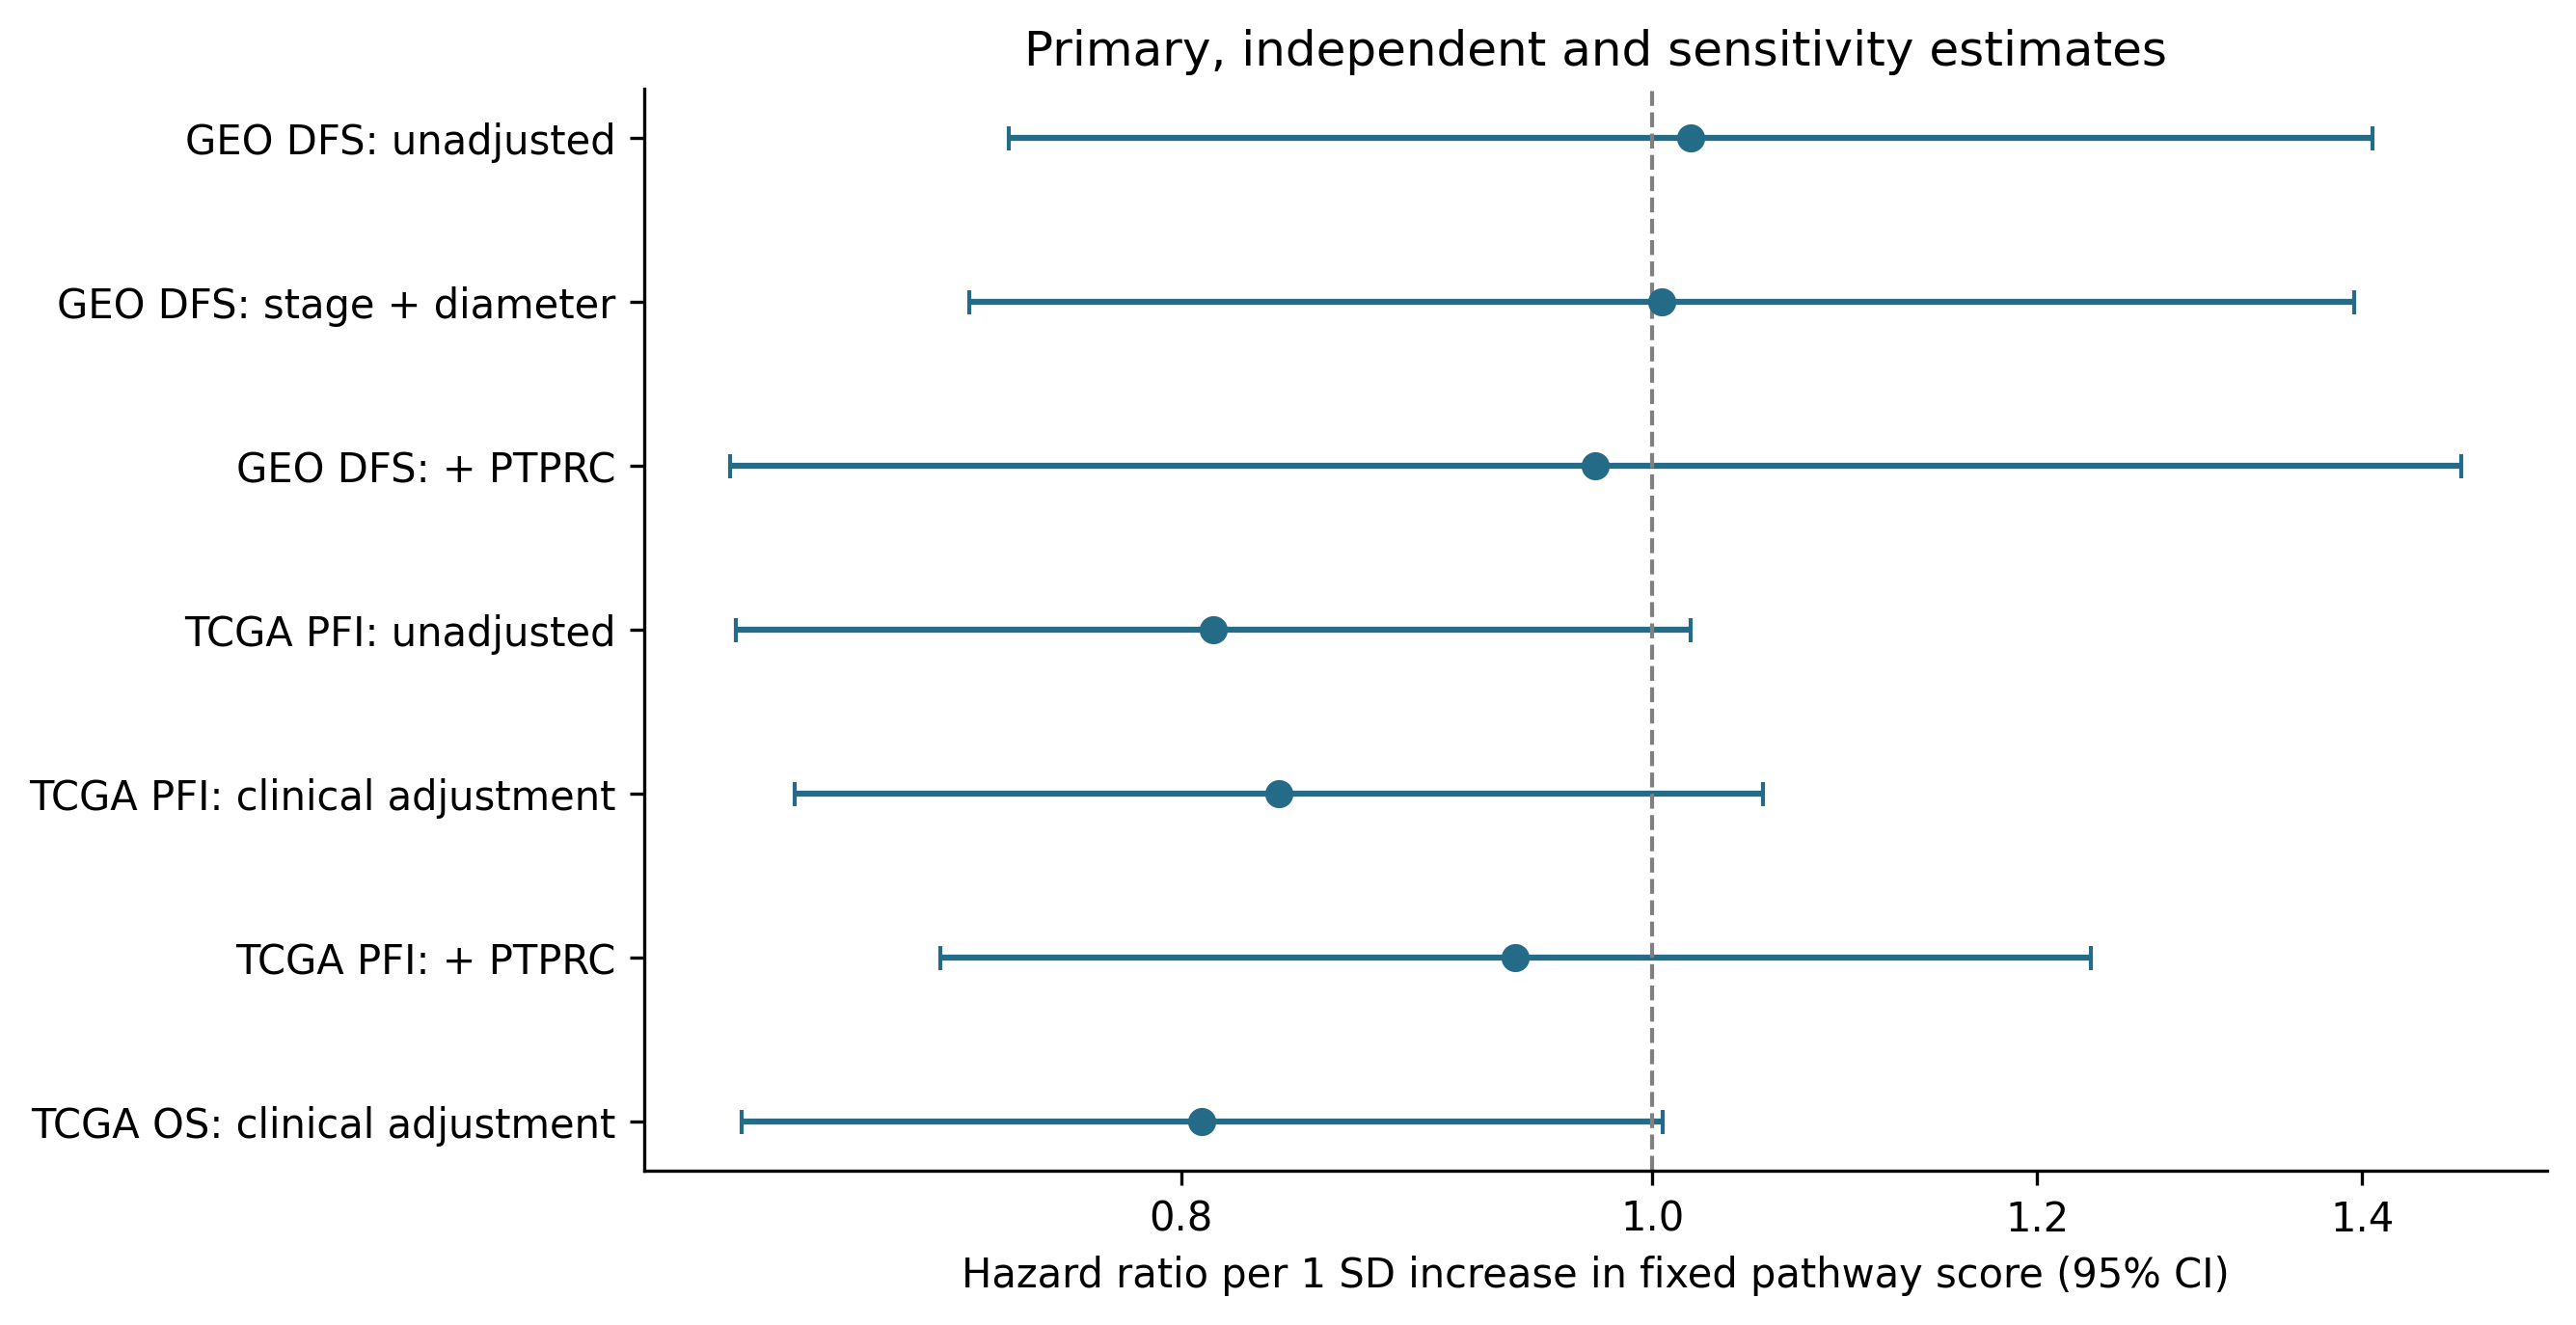

Figure_2: Uganda conditional HIV differences


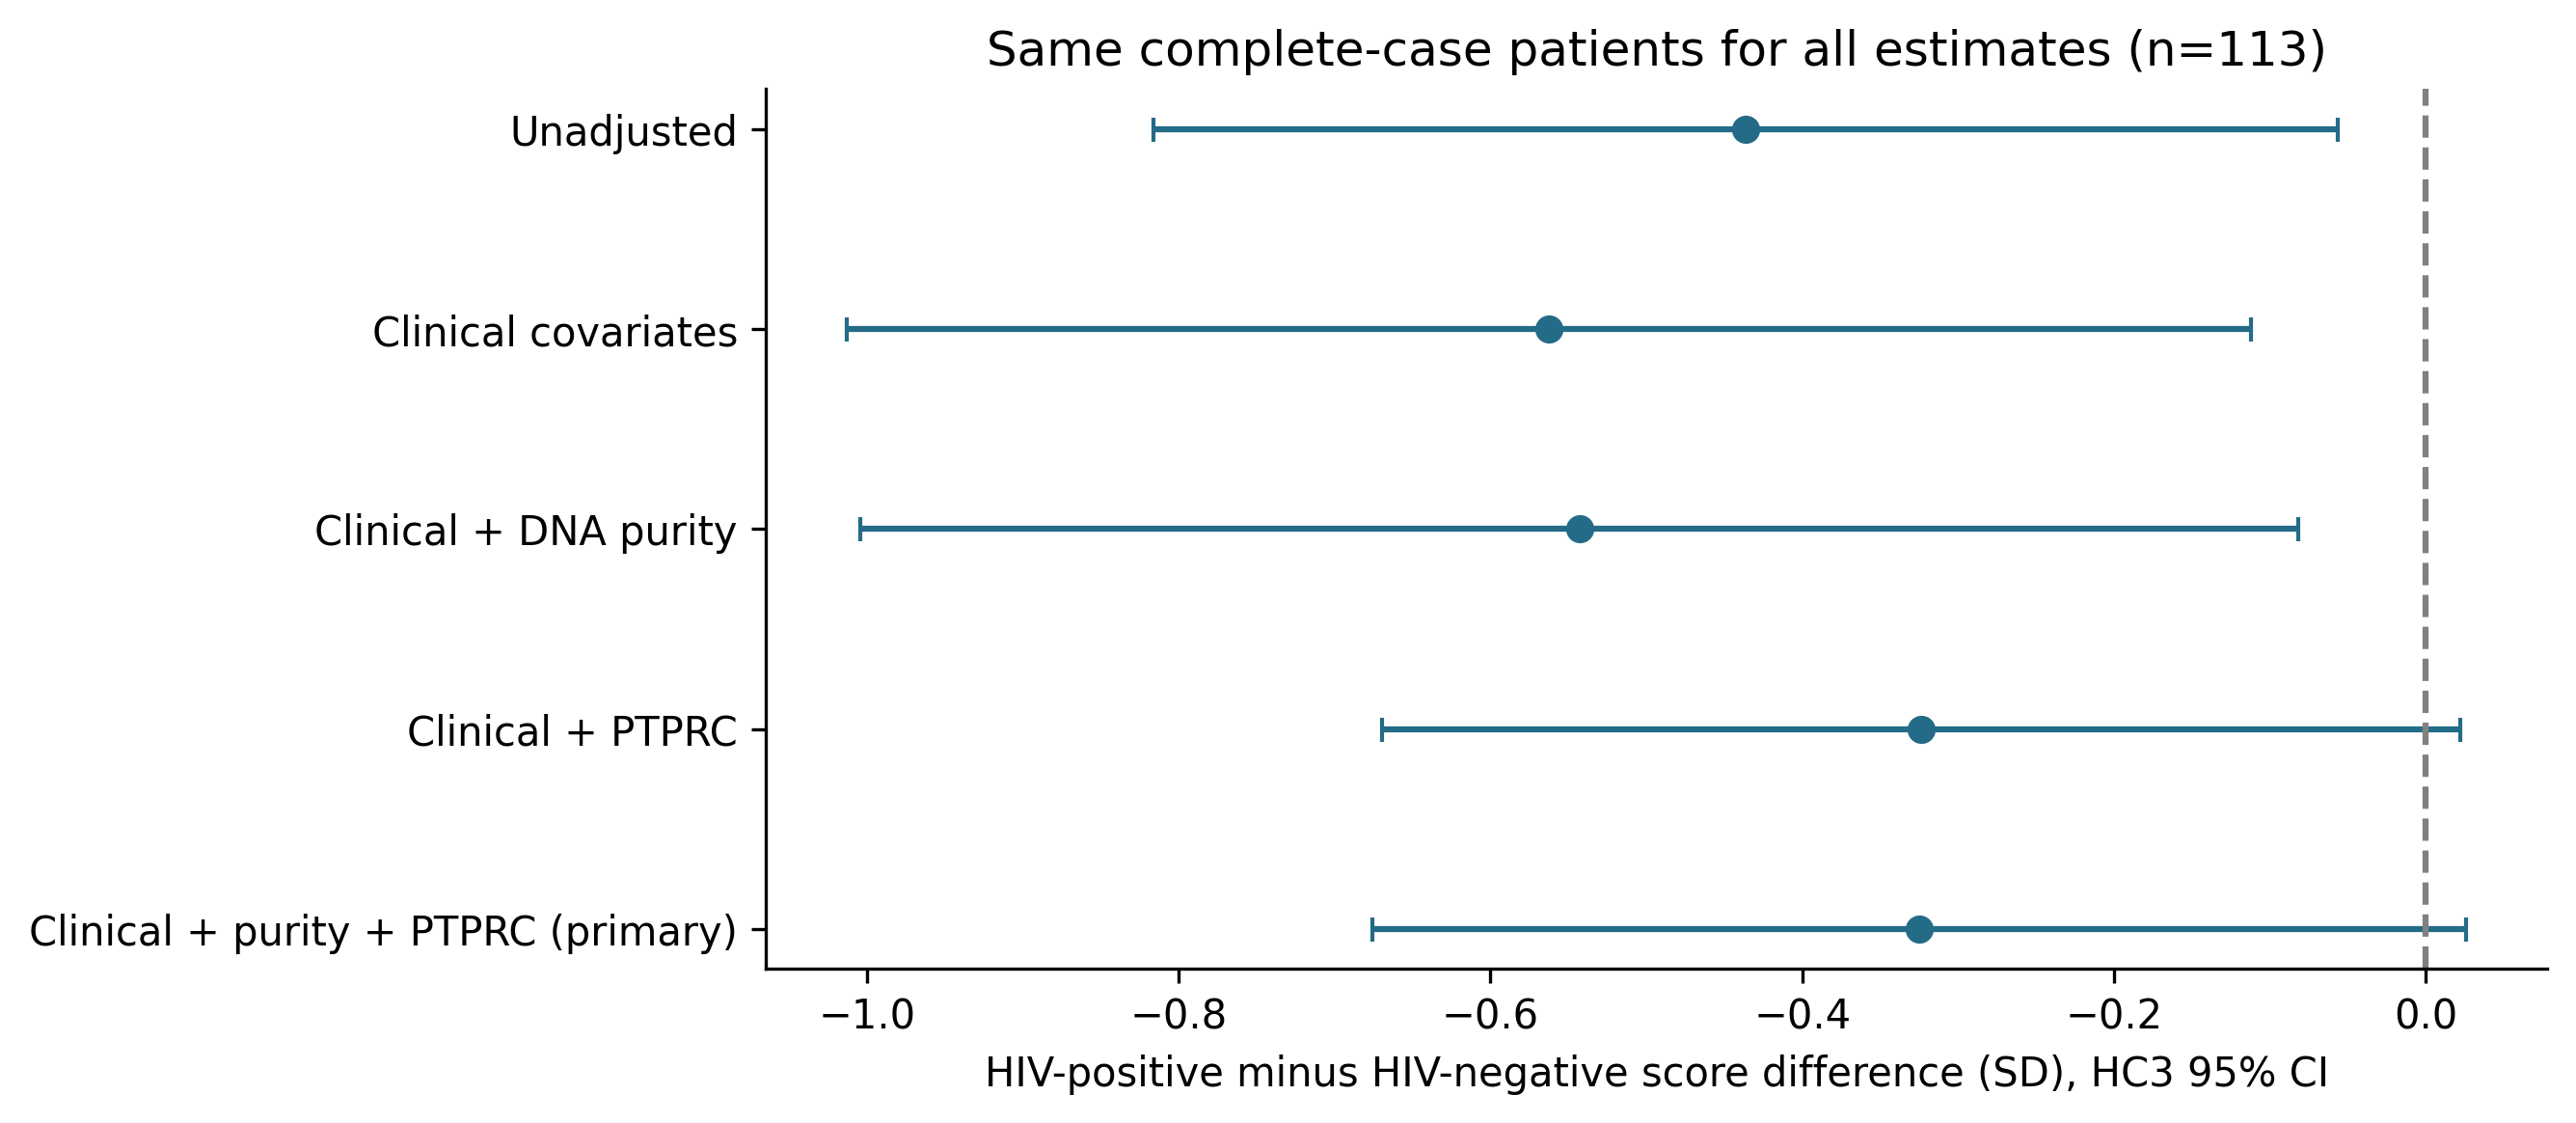

Figure_3: Single-cell target expression by compartment


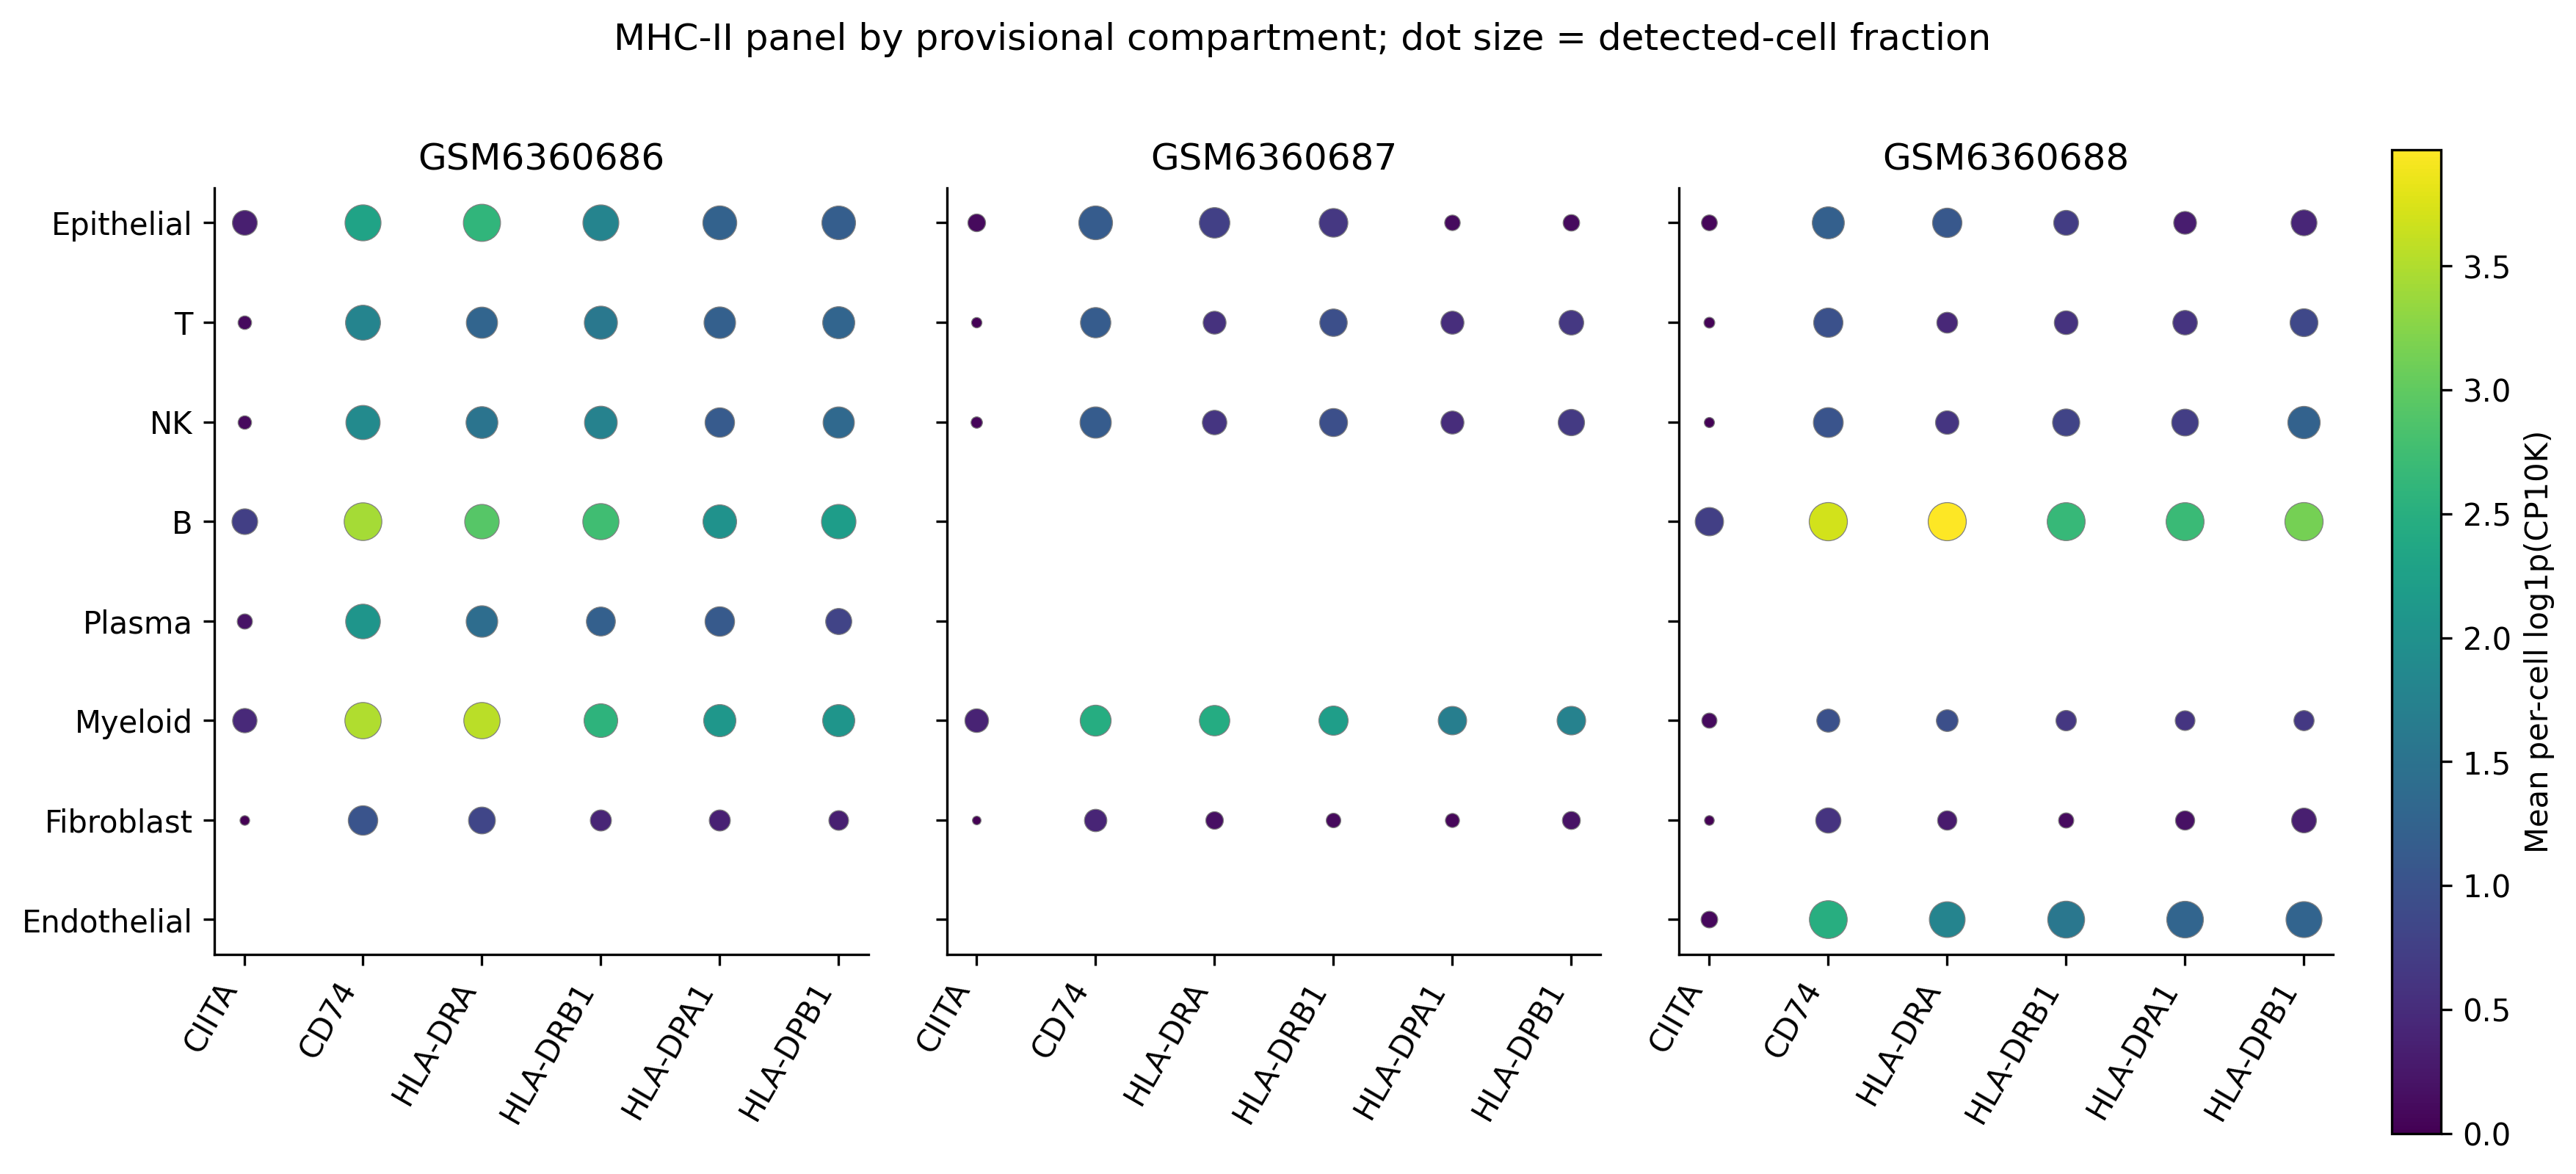

Figure_4: Single-cell robustness


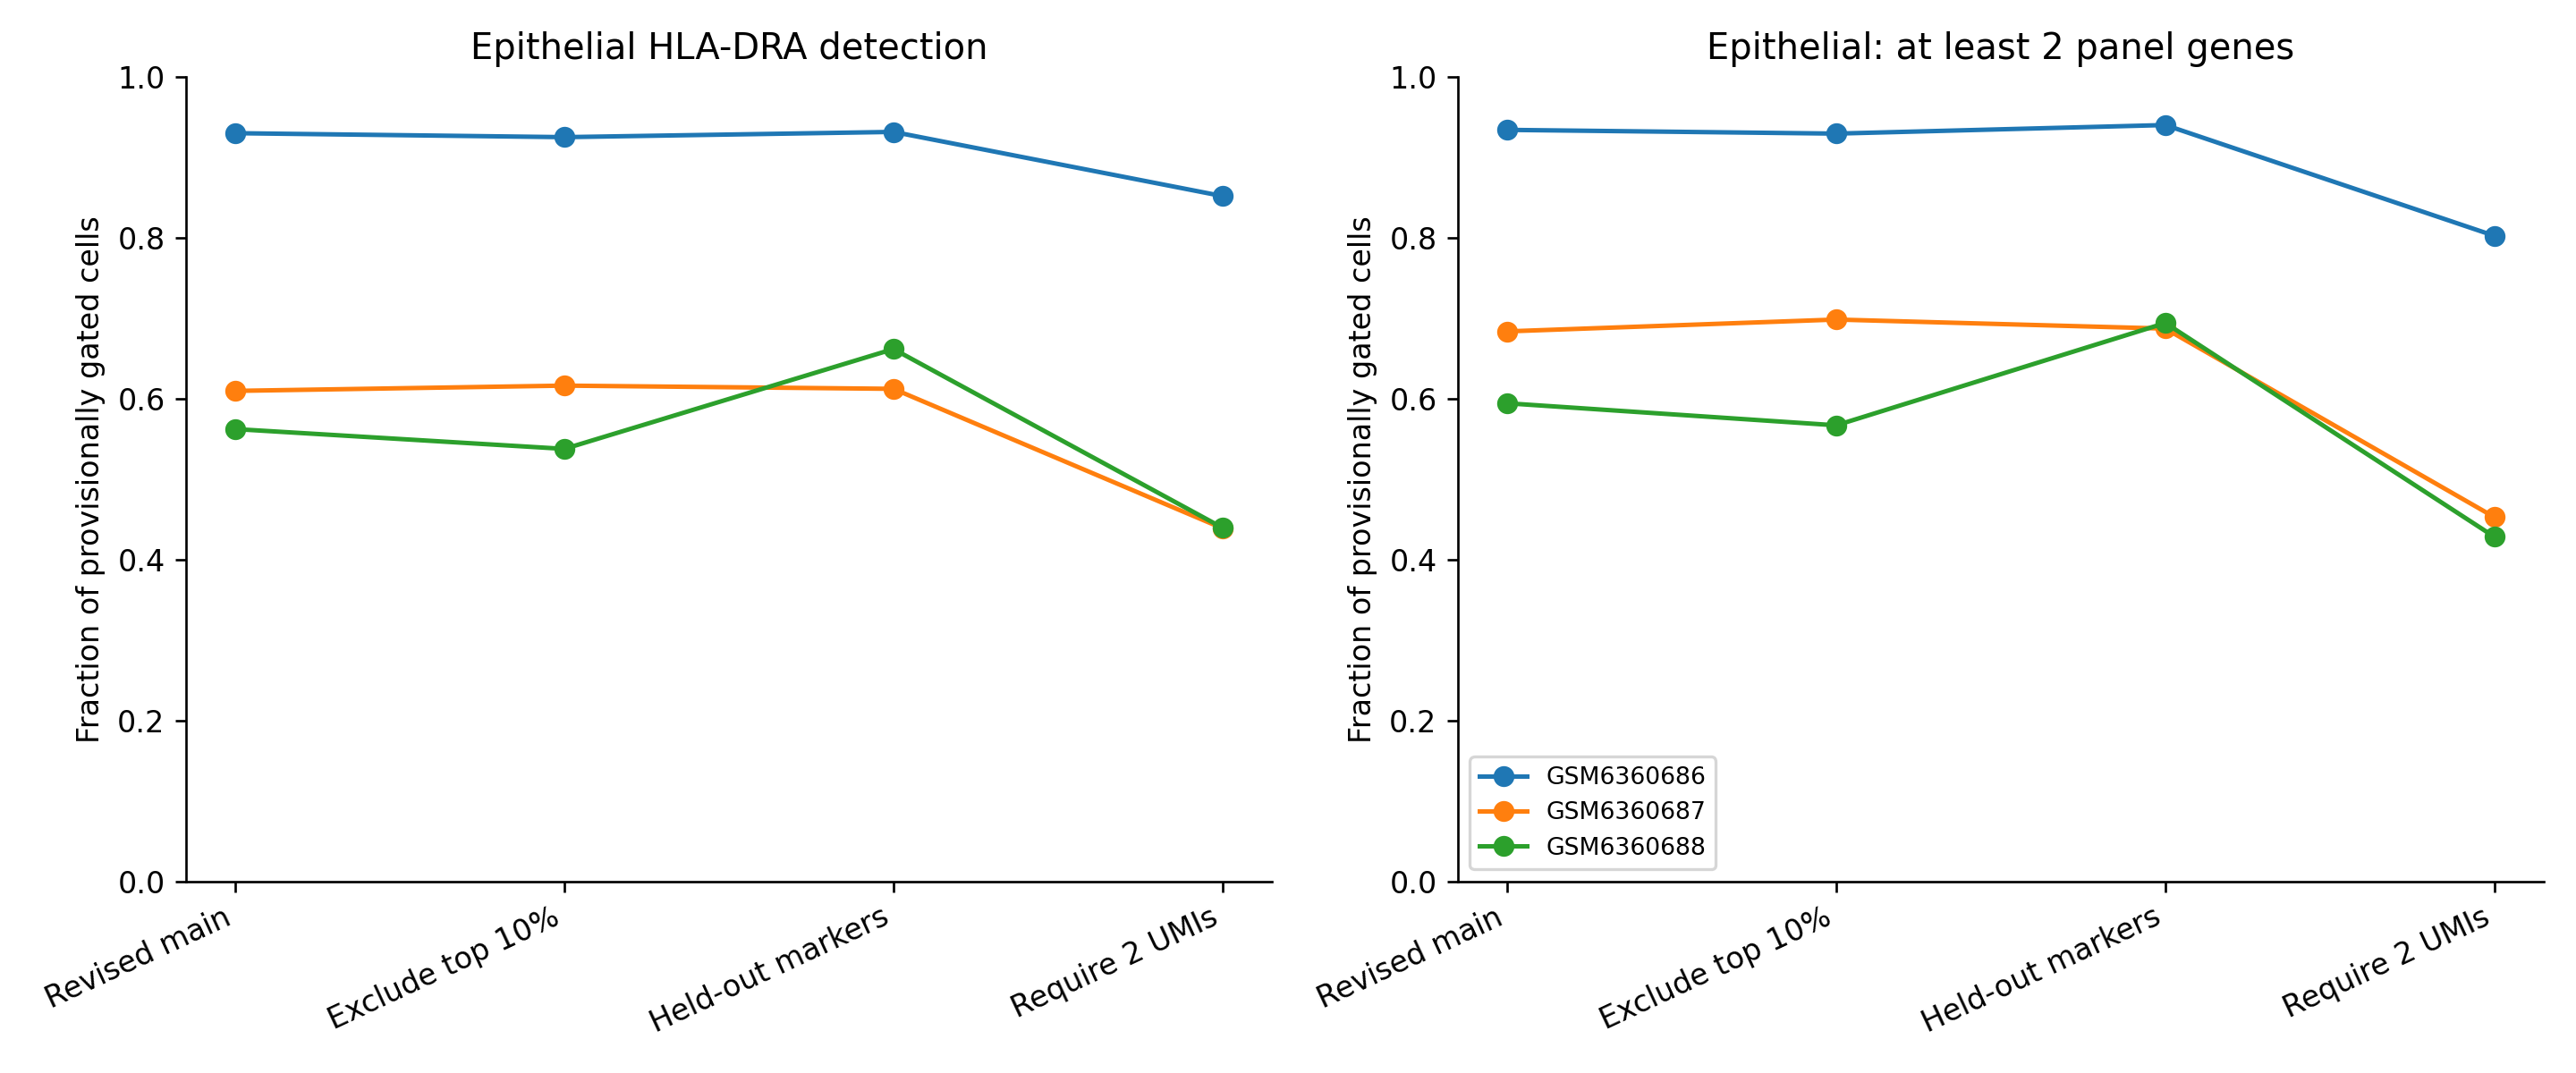

In [30]:
CELL_REGISTRY=[{'cell_id': 'c01', 'section': 'configuration', 'purpose': 'Configuration and common dependencies'}, {'cell_id': 'b01', 'section': 'bulk', 'purpose': 'Retrieve original bulk sources'}, {'cell_id': 'b02', 'section': 'bulk', 'purpose': 'Preserve GEO clinical annotations'}, {'cell_id': 'b03', 'section': 'bulk', 'purpose': 'Map probes and compute fixed GEO score'}, {'cell_id': 'b04', 'section': 'bulk', 'purpose': 'Match TCGA primary expression to curated outcomes'}, {'cell_id': 'b05', 'section': 'bulk', 'purpose': 'Missingness audit'}, {'cell_id': 'b06', 'section': 'bulk', 'purpose': 'Survival software and input checks'}, {'cell_id': 'b07', 'section': 'bulk', 'purpose': 'Clinical derivations and PTPRC proxy'}, {'cell_id': 'b08', 'section': 'bulk', 'purpose': 'Primary and independent Cox models'}, {'cell_id': 'b09', 'section': 'bulk', 'purpose': 'Prespecified sensitivity analyses and PH checks'}, {'cell_id': 'b10', 'section': 'bulk', 'purpose': 'Bootstrap uncertainty and cohort descriptions'}, {'cell_id': 'b11', 'section': 'bulk', 'purpose': 'Bulk cohort figures'}, {'cell_id': 'b12', 'section': 'bulk', 'purpose': 'Bulk analysis plan, interpretation and audit'}, {'cell_id': 'h01', 'section': 'uganda', 'purpose': 'Setup and historical analysis plan'}, {'cell_id': 'h02', 'section': 'uganda', 'purpose': 'Published clinical annotations'}, {'cell_id': 'h03', 'section': 'uganda', 'purpose': 'Pinned GDC expression retrieval'}, {'cell_id': 'h04', 'section': 'uganda', 'purpose': 'Fixed score and covariate derivation'}, {'cell_id': 'h05', 'section': 'uganda', 'purpose': 'HC3 models and same-row comparisons'}, {'cell_id': 'h06', 'section': 'uganda', 'purpose': 'Interaction and robustness analyses'}, {'cell_id': 'h07', 'section': 'uganda', 'purpose': 'Cohort flow and descriptive tables'}, {'cell_id': 'h08', 'section': 'uganda', 'purpose': 'HIV analysis figures'}, {'cell_id': 'h09', 'section': 'uganda', 'purpose': 'HIV interpretation report'}, {'cell_id': 's01', 'section': 'singlecell', 'purpose': 'Setup and documented exploratory amendment'}, {'cell_id': 's02', 'section': 'singlecell', 'purpose': 'Public single-cell sources and HIV metadata audit'}, {'cell_id': 's03', 'section': 'singlecell', 'purpose': 'QC, centred PCA doublet scores and marker measurements'}, {'cell_id': 's04', 'section': 'singlecell', 'purpose': 'Stricter provisional compartments and mixed-lineage exclusion'}, {'cell_id': 's05', 'section': 'singlecell', 'purpose': 'Specimen-level pseudobulk and robustness'}, {'cell_id': 's06', 'section': 'singlecell', 'purpose': 'Compartment figures and annotation markers'}, {'cell_id': 's07', 'section': 'singlecell', 'purpose': 'Revised interpretation and additional-marker audit'}, {'cell_id': 'm01', 'section': 'manuscript', 'purpose': 'Manuscript tables and consistent figure numbering'}, {'cell_id': 'm02', 'section': 'manuscript', 'purpose': 'Cross-section validation and manuscript interpretation'}, {'cell_id': 'm03', 'section': 'manuscript', 'purpose': 'One combined manuscript output ZIP'}]
from pathlib import Path
import shutil,json
import pandas as pd,numpy as np
from IPython.display import display,Image as DisplayImage
BULK=MROOT/'bulk'/'survival_outputs';HIV=MROOT/'uganda'/'outputs';SC=MROOT/'singlecell'/'outputs'
TABLES=MOUT/'tables';FIGURES=MOUT/'figures';SUPP=MOUT/'supplementary'
for folder in [TABLES,FIGURES,SUPP]:folder.mkdir(parents=True,exist_ok=True)
# Preserve all component outputs in explicit cohort folders. No raw matrices are exported.
for label,folder in [('bulk',BULK),('uganda',HIV),('singlecell',SC),('bulk_input_audits',MROOT/'bulk'/'outputs')]:
    dest=SUPP/label;dest.mkdir(exist_ok=True)
    for file in sorted(folder.iterdir()):
        if file.is_file():shutil.copy2(file,dest/file.name)
flow=pd.read_csv(BULK/'cohort_flow.csv');hflow=pd.read_csv(HIV/'cohort_flow.csv').set_index('step').patients
sqc=pd.read_csv(SC/'QC_summary.csv')
t1=[]
for r in flow.itertuples():t1.append({'dataset':r.cohort,'unit':'patients','input_n':r.input_patients,'endpoint_or_HIV_eligible_n':r.endpoint_and_score_eligible,'primary_analysis_n':r.adjusted_complete_cases,'events':r.adjusted_events,'endpoint':'deposited DFS (months)' if r.cohort=='GEO' else 'TCGA-CDR PFI (days)'})
t1.append({'dataset':'Uganda CGCI-HTMCP-CC','unit':'patients','input_n':int(hflow['Published discovery cohort']),'endpoint_or_HIV_eligible_n':int(hflow['Known HIV status']),'primary_analysis_n':int(hflow['Primary composition model complete cases']),'events':np.nan,'endpoint':'fixed score SD; HIV-positive minus HIV-negative'})
t1.append({'dataset':'GSE208653','unit':'specimens','input_n':3,'endpoint_or_HIV_eligible_n':np.nan,'primary_analysis_n':3,'events':np.nan,'endpoint':'descriptive cell-compartment expression'})
t1=pd.DataFrame(t1);t1.to_csv(TABLES/'Table_1_Cohort_flow.csv',index=False)
co=pd.read_csv(BULK/'cox_models_all_coefficients.csv');ph=pd.read_csv(BULK/'proportional_hazards_tests.csv')
modelnames=['GEO_unadjusted','GEO_adjusted','GEO_PTPRC_sensitivity','TCGA_PFI_unadjusted','TCGA_PFI_adjusted','TCGA_PFI_PTPRC_sensitivity','TCGA_OS_adjusted']
t2=co[co.variable.eq('score')].set_index('model').loc[modelnames,['role','n','events','HR','CI_low','CI_high','p']].reset_index()
t2=t2.merge(ph[ph.variable.eq('score')][['model','p']].rename(columns={'p':'score_PH_test_p'}),on='model',how='left')
t2['interpretation_note']=np.where(t2.model.eq('TCGA_OS_adjusted'),'Secondary OS; constant HR limited by score PH violation','Different cohorts/endpoints; no pooled effect')
t2.to_csv(TABLES/'Table_2_Survival_estimates.csv',index=False)
hiv=pd.read_csv(HIV/'HIV_effect_summary.csv');hnames=['HIV_unadjusted_same_rows','HIV_clinical_same_rows','HIV_clinical_purity_same_rows','HIV_clinical_PTPRC_same_rows','HIV_composition_adjusted_PRIMARY']
t3=hiv.set_index('model').loc[hnames,['n','HIV_positive','HIV_negative','estimate','CI_low','CI_high','p']].reset_index()
t3['effect_unit']='score SD; HIV-positive minus HIV-negative';t3.to_csv(TABLES/'Table_3_HIV_same_row_estimates.csv',index=False)
pair=pd.read_csv(SC/'epithelial_vs_immune_specimen_summaries.csv')
t4=pair[pair.gene.eq('HLA-DRA')][['sample','compartment','cells','fraction_detected','fraction_cells_at_least_2_targets','fraction_cells_all_6_targets']].rename(columns={'fraction_detected':'HLA_DRA_fraction_detected'})
t4.to_csv(TABLES/'Table_4_Single_cell_compartments.csv',index=False)
# Fixed manuscript figure labels. All other component figures remain supplementary.
figure_specs=[
 ('Figure_1','Survival estimates',BULK/'Figure_2_forest','b11'),
 ('Figure_2','Uganda conditional HIV differences',HIV/'Figure_2_HIV_adjusted_differences','h08'),
 ('Figure_3','Single-cell target expression by compartment',SC/'Figure_1_target_compartments','s06'),
 ('Figure_4','Single-cell robustness',SC/'Figure_4_robustness','s07')]
index=[]
for label,title,stem,cell in figure_specs:
    for extension in ['png','pdf']:
        origin=stem.with_suffix('.'+extension);target=FIGURES/(label+'.'+extension);assert origin.is_file();shutil.copy2(origin,target)
    index.append({'label':label,'content':title,'code_cells':cell,'file':'figures/'+label+'.pdf','role':'candidate main figure'})
for label,title,cell in [('Table_1','Cohort flow','b12;h07;s03'),('Table_2','Survival estimates','b08;b09'),('Table_3','HIV same-row contrasts','h05;h09'),('Table_4','Single-cell compartment detection','s04;s05')]:
    file=next(TABLES.glob(label+'_*.csv'));index.append({'label':label,'content':title,'code_cells':cell+';m01','file':'tables/'+file.name,'role':'candidate main table'})
for label,file,cell in [('Supplement_S1','supplementary/bulk/proportional_hazards_tests.csv','b08;b09'),('Supplement_S2','supplementary/bulk/bootstrap_coefficient_intervals.csv','b10'),('Supplement_S3','supplementary/uganda/primary_VIF.csv','h06'),('Supplement_S4','supplementary/singlecell/epithelial_sensitivity_comparison.csv','s05;s07'),('Supplement_S5','supplementary/singlecell/heldout_annotation_audit.csv','s07'),('Supplement_S6','supplementary/singlecell/empty_droplet_availability_audit.csv','s07')]:
    index.append({'label':label,'content':Path(file).name,'code_cells':cell,'file':file,'role':'supplementary audit'})
reference_index=pd.DataFrame(index);reference_index.to_csv(MOUT/'Manuscript_reference_index.csv',index=False)
(MOUT/'Notebook_cell_registry.json').write_text(json.dumps(CELL_REGISTRY,indent=2))
print('Manuscript candidate tables:')
for label,frame in [('Table 1',t1),('Table 2',t2),('Table 3',t3),('Table 4',t4)]:print(label);display(frame)
print('Four consistently numbered candidate main figures; remaining figures are supplementary.')
for label,title,_,_ in figure_specs:print(label+': '+title);display(DisplayImage(filename=str(FIGURES/(label+'.png'))))


## M02 · Cross-section validation and manuscript interpretation

In [31]:
import json,importlib.metadata as package_metadata
from datetime import datetime,timezone
# Consistency checks use current computed data, not prewritten result strings.
assert MASTER_GENES==['CIITA','CD74','HLA-DRA','HLA-DRB1','HLA-DPA1','HLA-DPB1']
assert set(t2.model)==set(modelnames) and len(t2)==7
assert t2[['HR','CI_low','CI_high','p']].notna().all().all()
assert (t2.CI_low<=t2.HR).all() and (t2.HR<=t2.CI_high).all()
assert t3.n.nunique()==1 and (t3.HIV_positive+t3.HIV_negative==t3.n).all()
assert t4[['sample','compartment']].drop_duplicates().shape[0]==6
assert t4['sample'].nunique()==3
assert t4.HLA_DRA_fraction_detected.between(0,1).all()
assert not reference_index.label.duplicated().any()
assert all((MOUT/file).is_file() for file in reference_index.file)
# Independently recompute cell summaries and pseudobulk denominators from exported arrays.
c=pd.read_csv(SC/'cell_annotations_and_marker_scores.csv.gz');a=np.load(SC/'cell_panel_arrays.npz');raw=a['raw_UMI'];panel_genes=list(a['genes'])
assert c.sample_cell_id.is_unique and np.array_equal(c.sample_cell_id.to_numpy(str),a['sample_cell_id'])
assert (c.loc[c.compartment.eq('Epithelial'),'marker_detected_Epithelial']>=3).all()
assert not c.loc[c.compartment.eq('Epithelial'),'mixed_epithelial_immune'].any()
checks=[]
for r in pd.read_csv(SC/'specimen_compartment_expression.csv').itertuples():
    keep=c['sample'].eq(r.sample)&(c.compartment.isin(['T','NK','B','Plasma','Myeloid']) if r.compartment=='Immune' else c.compartment.eq(r.compartment))
    vals=raw[keep,panel_genes.index(r.gene)]
    assert int(keep.sum())==r.cells and np.isclose((vals>0).mean(),r.fraction_detected)
    assert np.isclose(vals.sum(),r.target_UMI_sum) and np.isclose(c.loc[keep,'UMIs'].sum(),r.all_gene_UMI_sum)
    checks.append({'sample':r.sample,'compartment':r.compartment,'gene':r.gene,'passed':True})
pd.DataFrame(checks).to_csv(MOUT/'Independent_single_cell_numeric_checks.csv',index=False)
versions={'python':sys.version}
for package in ['numpy','pandas','scipy','lifelines','matplotlib','openpyxl','scikit-learn','scikit-image','scrublet','threadpoolctl']:
    versions[package]=package_metadata.version(package)
(MOUT/'Software_versions.json').write_text(json.dumps(versions,indent=2))
# Expected results from prior verified runs are a reproduction audit, not analysis targets.
expected={'GEO_adjusted': 1.0045342306921907, 'TCGA_PFI_adjusted': 0.8378857834440433}
rep=[]
for model,target in expected.items():
    actual=float(t2.set_index('model').loc[model,'HR']);rep.append({'model':model,'prior_reference_HR':target,'current_HR':actual,'difference':actual-target})
pd.DataFrame(rep).to_csv(MOUT/'Prior_run_reproduction_audit.csv',index=False)
g=t2.set_index('model').loc['GEO_adjusted'];t=t2.set_index('model').loc['TCGA_PFI_adjusted'];h=t3.set_index('model').loc['HIV_composition_adjusted_PRIMARY']
def fmt(r):return f"HR {r.HR:.3f} (95% CI {r.CI_low:.3f}–{r.CI_high:.3f}), p={r.p:.4g}; n={int(r.n)}, events={int(r.events)}"
scsens=pd.read_csv(SC/'epithelial_sensitivity_comparison.csv')
# The condition checks describe evidence, not proof of absent effects.
statements=[
 '# Manuscript analysis reference',
 'Generated '+datetime.now(timezone.utc).isoformat(),
 '## Working title',
 'Cellular context and prognostic associations of a fixed MHC-II expression panel in cervical cancer: a secondary analysis of public datasets',
 '## Design and primary results',
 'This consolidated notebook was assembled after component results were examined. It reproduces the existing models and documented exploratory single-cell revision; it is not a new preregistered analysis.',
 'GSE44001 deposited DFS: '+fmt(g),
 'TCGA-CDR PFI: '+fmt(t),
 f"Uganda composition-adjusted HIV-positive minus HIV-negative difference: {h.estimate:.3f} SD (95% CI {h.CI_low:.3f} to {h.CI_high:.3f}), p={h.p:.4g}; n={int(h.n)} ({int(h.HIV_positive)} positive, {int(h.HIV_negative)} negative).",
 'Read effects with confidence intervals. Negative or uncertain models do not establish equivalence. No sensitivity estimate replaces the original primary result. DFS and PFI are different outcomes and have not been pooled.',
 '## Single-cell interpretation',
 'The revised analysis has three specimens, not thousands of independent patients. Broad epithelial/immune labels are provisional; no malignant-cell inference was performed. Target transcripts occur in both compartments. Marker rules exclude all six targets. Additional markers audit annotation, and >=2-UMI criteria assess reliance on single counts; neither proves absence of ambient RNA.',
 f"Automatic Scrublet flags: {int(sqc.predicted_doublets.sum())} of {int(sqc.QC_pass.sum()):,} QC-passing cells. Standard centred PCA did not resolve the low flag rate. Excluding the top 3%, 6% and 10% of scores is a sensitivity exercise, not an estimated doublet rate.",
 'The deposited matrices have no verified empty-droplet background; no SoupX correction is claimed. Detection under stronger filters is descriptive robustness, not functional antigen-presentation validation. No HIV comparison is possible in this single-cell dataset.',
 '## Main table/figure map',
 reference_index.to_csv(index=False),
 'Candidate main display: four tables and four figures. This is a reference set for drafting, not a claim that the target journal allows eight main items. Reduce/combine at manuscript preparation according to current journal requirements; keep all other analyses supplementary.',
 '## Methods to retain',
 'Score: six fixed equal-weight gene z-scores averaged and standardised per cohort. GEO uses platform-symbol probe averages; TCGA retains supplied expression; Uganda uses current STAR-Counts log2(TPM+1). Cohort-specific scaling is not a transferable clinical threshold.',
 'GEO Cox model: score, stage IIA versus I and diameter per SD. TCGA Cox model: score, age per decade, major stage II/III/IV versus I and non-squamous histology. Complete cases, no imputation. PH diagnostics and 200 conditional patient-bootstrap replicates are supplementary. The secondary OS score PH violation limits its constant-HR interpretation.',
 'Uganda HC3 OLS model: score versus HIV plus age, grouped stage, HPV clade, final histology, DNA purity and PTPRC. Same-row clinical and composition models use identical complete cases. Covariate adjustment is conditional and does not establish a causal HIV effect or mediation.',
 'Single-cell QC and revised gates are given in S03–S05 and the exported amendment. No cell-level significance tests or formal SCC-versus-ADC comparison were performed.',
 '## Unresolved issues before submission',
 'GEO event composite, precise time origin/censoring and original diameter units are not fully verified. Do not relabel the deposited DFS endpoint or claim cause-specific recurrence. Diameter is analysed per SD. The original GEO covariates do not support adjustment for nodes, margins, LVSI, adjuvant therapy or HPV.',
 'PTPRC is an imperfect expression-based composition proxy. DNA purity derives from the source publication and may correspond to a different portion than selected current RNA files. The single-cell series provides context, not HIV-effect validation. Existing cervical epithelial MHC-II studies limit novelty; this work is an exploratory replication/interpretation study.',
 'Obtain the appropriate local ethics determination and review repository terms. No approval, waiver, consent exemption, funding, author contribution or permanent repository DOI is invented.',
 '## Data, code and archival record',
 'The original sources and historical plans are preserved under supplementary/. Use the final combined ZIP with the executed notebook. Archive both publicly in a permanent repository before manuscript submission and cite its assigned identifier. Do not cite a temporary Colab session as the only code record.'
]
(MOUT/'Manuscript_Analysis_Reference.md').write_text('\n\n'.join(statements))
MASTER_RUN['completed_utc']=datetime.now(timezone.utc).isoformat();MASTER_RUN['numeric_checks_passed']=len(checks)
(MOUT/'run_configuration.json').write_text(json.dumps(MASTER_RUN,indent=2))
print('Independent count and denominator checks passed:',len(checks))
print('GEO:',fmt(g));print('TCGA:',fmt(t));print('Uganda:',h[['estimate','CI_low','CI_high','p']].to_dict())
print('Manuscript reference and full software record created.')


Independent count and denominator checks passed: 132
GEO: HR 1.005 (95% CI 0.723–1.395), p=0.9784; n=300, events=38
TCGA: HR 0.838 (95% CI 0.666–1.054), p=0.131; n=284, events=70
Uganda: {'estimate': -0.3250053648575095, 'CI_low': -0.6760820852709282, 'CI_high': 0.0260713555559091, 'p': 0.0692480889133764}
Manuscript reference and full software record created.


## M03 · One combined manuscript output ZIP

In [32]:
import hashlib,zipfile,json,shutil
# Inventory is relative and excludes raw downloads and the inventory itself.
items=[]
for f in sorted(MOUT.rglob('*')):
    if f.is_file() and f.name!='Output_inventory.csv':items.append({'path':str(f.relative_to(MOUT)),'bytes':f.stat().st_size,'sha256':hashlib.sha256(f.read_bytes()).hexdigest()})
pd.DataFrame(items).to_csv(MOUT/'Output_inventory.csv',index=False)
archive=shutil.make_archive(str(MROOT/'Cervical_MHCII_Manuscript_Outputs'),'zip',MOUT)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    assert {'Manuscript_Analysis_Reference.md','Manuscript_reference_index.csv','tables/Table_1_Cohort_flow.csv','Software_versions.json'}<=set(z.namelist())
print('Completed unified manuscript analysis.')
print('Results ZIP:',archive)
print('Keep this ZIP and save the executed notebook; Colab runtime files are temporary.')
print('Use Manuscript_reference_index.csv to locate the code for every table/figure.')
try:
    from google.colab import files
    files.download(archive)
except ImportError:pass


Completed unified manuscript analysis.
Results ZIP: /content/cervical_mhcii_manuscript/Cervical_MHCII_Manuscript_Outputs.zip
Keep this ZIP and save the executed notebook; Colab runtime files are temporary.
Use Manuscript_reference_index.csv to locate the code for every table/figure.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>